# Predicting Student Failure in Distance Learning Using Machine Learning and Explainability: Ablation Study (Excluding A1 Score)

**Open University Learning Analytics Dataset (OULAD)**: courses B, D, E, F
(modules `BBB`, `DDD`, `EEE`, `FFF`).

This notebook is an end-to-end, reproducible implementation of the research
proposal. It builds a **leakage-safe early-warning** classifier of student
failure without using the first assessment (A1) score, compares four models with
explicit class-imbalance handling, explains predictions with **SHAP**, and tests
**cross-course generalisation**.

### How the notebook maps to the proposal's timeline

| Phase | Weeks | Notebook section |
|---|---|---|
| **P1** – Literature & setup, data access | 1–2 | §0 Setup · §1 Configuration · §2 Data loading |
| **P2** – EDA & preprocessing | 3–5 | §3 Target & cutoff · §4 Feature engineering · §5 EDA · §6 Imbalance |
| **P3** – Modelling | 6–8 | §7 Models · §8 Training & evaluation |
| **P4** – Explainability | 9–10 | §9 SHAP |
| **P5** – Analysis & write-up | 11–12 | §10 Cross-course generalisation · §11 Summary |

> **Running the pipeline.** The seven OULAD CSV files were placed in `./data` 
> and all notebook cells were executed. If the data folder is unavailable, the 
> notebook generates a synthetic dataset with the same schema for pipeline 
> testing only; synthetic data is not used for reported results. Course selection
> and analysis options (including A1 score inclusion/exclusion, QUICK mode, SHAP, and transfer analysis) are configured through the Notebook settings cell in §2.

## §0 · Setup

Environment flags (quiet TensorFlow), imports, a single stdout logger, global
seeding for reproducibility, and a small helper to display saved figures inline.

In [1]:
import os
# Quieten TensorFlow / oneDNN before it is imported anywhere.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

# --- Standard library ---
import glob
import json
import logging
import math
import random
import re
import shutil
import sys
import warnings
from pathlib import Path
from types import SimpleNamespace
from typing import Dict, Sequence, Tuple

# --- Third-party: scientific stack ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import seaborn as sns
import joblib

# --- Third-party: modelling ---
import shap
import tensorflow as tf
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from xgboost import XGBClassifier

# --- Notebook display ---
from IPython.display import Image, display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

# Keep the notebook output clean. Re-enable to inspect warnings.
warnings.filterwarnings("ignore")

from IPython.display import Image, display, Markdown


def get_logger(name: str = "pipeline") -> logging.Logger:
    """A single stdout logger (so messages don't render as error output)."""
    logger = logging.getLogger(name)
    if not logger.handlers:
        h = logging.StreamHandler(stream=sys.stdout)
        h.setFormatter(logging.Formatter(
            "%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S"))
        logger.addHandler(h)
        logger.setLevel(logging.INFO)
        logger.propagate = False
    return logger


logger = get_logger()


def banner(logger, text: str) -> None:
    line = "=" * 70
    logger.info(line); logger.info(text); logger.info(line)


def set_global_seed(seed: int) -> None:
    """Seed every relevant RNG so results are reproducible."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.random.set_seed(seed)
    except Exception:
        pass


def _json_default(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)


def save_json(obj, path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(obj, fh, indent=2, default=_json_default)


def show_images(paths, width=620):
    """Display one or more saved figures inline (accepts a glob or a list)."""
    import glob
    if isinstance(paths, str):
        paths = sorted(glob.glob(paths))
    for p in paths:
        if Path(p).exists():
            display(Image(filename=str(p), width=width))

## §1 · Configuration  *(Phase 1)*

Every tunable parameter lives here. `config` is a simple namespace so the rest
of the notebook stays declarative: change courses, the prediction horizon, the
target definition, the model search spaces, or output locations in one place.

Key methodological settings:

* **Target**: Pass/Distinction → 0; Fail → 1; withdrawals split on the
  **census date** (before census = never genuinely enrolled, dropped;
  on/after = failure), following common practice in OULAD-based early warning studies, students who withdrew before the census date were excluded, while those who withdrew on or after the census date were treated as failures.
* **Prediction cutoff**: all behavioural features use only data up to the
  first assessment's due date, so the model is a genuine *early-warning* system.

In [2]:
PROJECT_ROOT = Path.cwd()

config = SimpleNamespace(
    # ---- paths ----
    PROJECT_ROOT=PROJECT_ROOT,
    DATA_DIR=PROJECT_ROOT / "data",
    OUTPUT_DIR=PROJECT_ROOT / "outputs",
    CSV_FILES={
        "assessments": "assessments.csv",
        "courses": "courses.csv",
        "studentAssessment": "studentAssessment.csv",
        "studentInfo": "studentInfo.csv",
        "studentRegistration": "studentRegistration.csv",
        "studentVle": "studentVle.csv",
        "vle": "vle.csv",
    },
    # ---- reproducibility ----
    RANDOM_STATE=42,
    # ---- scope: courses B, D, E, F ----
    TARGET_MODULES=["BBB", "DDD", "EEE", "FFF"],
    # ---- target definition ----
    POSITIVE_RESULTS=["Fail"],
    PASS_RESULTS=["Pass", "Distinction"],
    WITHDRAWN_LABEL="Withdrawn",
    CENSUS_DATE=0,
    # ---- early-warning prediction horizon ----
    CUTOFF_MODE="first_assessment",   # or "fixed_day"
    CUTOFF_ASSESSMENT_OFFSET=0,
    CUTOFF_FIXED_DAY=30,
    FIRST_WEEK_DAYS=7,
    # Cap extreme A1 submission-timing outliers (days); None disables. The
    # early/late flag is derived from the uncapped sign, so this only bounds
    # magnitude so outliers can't dominate the model or its SHAP explanation.
    A1_DAYS_EARLY_CLIP=(-30.0, 30.0),
    # ---- feature groups ----
    DEMOGRAPHIC_CATEGORICAL=["gender", "region", "highest_education",
                             "imd_band", "age_band", "disability"],
    DEMOGRAPHIC_NUMERIC=["num_of_prev_attempts", "studied_credits",
                         "date_registration"],
    MODE_IMPUTE_FIELDS=["imd_band"],
    # Ablation: feature names listed here are withheld from the models. They are
    # still engineered and still saved to feature_matrix.csv -- only the
    # classifiers and SHAP stop seeing them. Set via EXCLUDE_A1_SCORE in §2.
    EXCLUDE_FEATURES=[],
    # ---- class imbalance ----
    IMBALANCE_STRATEGIES=["none", "smote", "class_weight"],
    # ---- CV / evaluation ----
    CV_FOLDS=5,
    TEST_SIZE=0.20,
    PRIMARY_METRIC="pr_auc",
    METRICS=["pr_auc", "roc_auc", "f1"],
    DECISION_THRESHOLD=0.5,
    # ---- hyper-parameter search ----
    N_RANDOM_SEARCH_ITER=25,
    LOGREG_PARAMS={
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__max_iter": [2000],
    },
    RF_PARAM_DIST={
        "classifier__n_estimators": [200, 400, 600, 800],
        "classifier__max_depth": [None, 6, 10, 16, 24],
        "classifier__min_samples_split": [2, 5, 10],
        "classifier__min_samples_leaf": [1, 2, 4],
        "classifier__max_features": ["sqrt", "log2", None],
    },
    XGB_PARAM_DIST={
        "classifier__n_estimators": [200, 400, 600, 800],
        "classifier__max_depth": [3, 4, 6, 8, 10],
        "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
        "classifier__subsample": [0.6, 0.8, 1.0],
        "classifier__colsample_bytree": [0.6, 0.8, 1.0],
        "classifier__reg_lambda": [0.5, 1.0, 2.0, 5.0],
        "classifier__min_child_weight": [1, 3, 5],
    },
    MLP_PARAMS={
        "hidden_units": (128, 64), "dropout": 0.3, "learning_rate": 1e-3,
        "batch_size": 256, "epochs": 80, "patience": 10,
    },
    # ---- SHAP ----
    SHAP_BACKGROUND_SIZE=100,
    SHAP_KERNEL_SAMPLE=200,
    SHAP_N_WATERFALL=3,
    # ---- cross-course ----
    RUN_CROSS_COURSE_TRANSFER=True,
)

# Derived output sub-directories.
config.FIGURE_DIR = config.OUTPUT_DIR / "figures"
config.MODEL_DIR = config.OUTPUT_DIR / "models"
config.TABLE_DIR = config.OUTPUT_DIR / "tables"
config.SHAP_DIR = config.OUTPUT_DIR / "shap"
for _d in (config.OUTPUT_DIR, config.FIGURE_DIR, config.MODEL_DIR,
           config.TABLE_DIR, config.SHAP_DIR):
    _d.mkdir(parents=True, exist_ok=True)

set_global_seed(config.RANDOM_STATE)
print("Configuration ready. Outputs ->", config.OUTPUT_DIR)

Configuration ready. Outputs -> C:\Users\twuma\OneDrive - hull.ac.uk\Research\Research Project\Final Code (A1_score excluded)\outputs


## §2 · Data loading & settings  *(Phase 1)*

First, the **notebook settings** that can be changed. Then the loader,
which validates each table's schema against the documented OULAD structure
(Kuzilek et al., 2017) and restricts everything to the four courses in scope.

### Notebook settings

* `COURSES`: subset of `BBB, DDD, EEE, FFF` to analyse.
* `QUICK`: `True` shrinks CV folds / search iterations / MLP epochs for a fast
  smoke run; set `False` for full-strength runs on the real data.
* `RUN_EDA`, `RUN_SHAP`, `RUN_TRANSFER`: toggle the expensive stages.
* `USE_SYNTHETIC_IF_MISSING`: if the real data is absent, generate a synthetic
  stand-in so the notebook still runs.
* `EXCLUDE_A1_SCORE`: `True` excludes the first assessment mark (`a1_score` and `a1_score_band`) to evaluate the contribution of the mark itself, while retaining submission behaviour features; `False` uses the full feature set (default).


In [3]:
COURSES = ["BBB", "DDD", "EEE", "FFF"]    # e.g. ["BBB", "DDD"] for just those courses
QUICK = False                           # set True for a fast smoke run
RUN_EDA = True
RUN_SHAP = True
RUN_TRANSFER = True
USE_SYNTHETIC_IF_MISSING = True   # generate synthetic data if ./data is absent

# --- Ablation: how much of the performance comes from the A1 mark itself? ----
# True  -> withhold the first-assessment MARK from every model.
# False -> the full feature set (the default configuration).
# a1_score_band is the same mark bucketed into grade bands, so a clean ablation
# must drop both; dropping only "a1_score" leaves the mark in banded form.
# Submission BEHAVIOUR (a1_submitted, a1_days_early, a1_is_banked) is kept
# either way, so the models still know whether and when the student submitted.
EXCLUDE_A1_SCORE = True

if EXCLUDE_A1_SCORE:
    config.EXCLUDE_FEATURES = ["a1_score", "a1_score_band"]
    logger.info("Ablation ON: withholding the A1 mark (%s) from the models",
                ", ".join(config.EXCLUDE_FEATURES))
else:
    config.EXCLUDE_FEATURES = []

if QUICK:
    config.CV_FOLDS = 3
    config.N_RANDOM_SEARCH_ITER = 4
    config.MLP_PARAMS["epochs"] = 5
    config.SHAP_KERNEL_SAMPLE = 40
    config.SHAP_BACKGROUND_SIZE = 30
    logger.info("QUICK mode: CV=3, search_iter=4, MLP epochs=5")
else:
    logger.info("FULL mode: CV=%d, search_iter=%d, MLP epochs=%d",
                config.CV_FOLDS, config.N_RANDOM_SEARCH_ITER,
                config.MLP_PARAMS["epochs"])

20:20:57 | INFO    | Ablation ON: withholding the A1 mark (a1_score, a1_score_band) from the models
20:20:57 | INFO    | FULL mode: CV=5, search_iter=25, MLP epochs=80


In [4]:
# Minimal expected columns per table (used for schema validation).
EXPECTED_COLUMNS: Dict[str, list[str]] = {
    "assessments": [
        "code_module", "code_presentation", "id_assessment",
        "assessment_type", "date", "weight",
    ],
    "courses": ["code_module", "code_presentation", "module_presentation_length"],
    "studentAssessment": [
        "id_assessment", "id_student", "date_submitted", "is_banked", "score",
    ],
    "studentInfo": [
        "code_module", "code_presentation", "id_student", "gender", "region",
        "highest_education", "imd_band", "age_band", "num_of_prev_attempts",
        "studied_credits", "disability", "final_result",
    ],
    "studentRegistration": [
        "code_module", "code_presentation", "id_student",
        "date_registration", "date_unregistration",
    ],
    "studentVle": [
        "code_module", "code_presentation", "id_student", "id_site",
        "date", "sum_click",
    ],
    "vle": [
        "id_site", "code_module", "code_presentation", "activity_type",
        "week_from", "week_to",
    ],
}


def load_raw(data_dir: Path | None = None) -> Dict[str, pd.DataFrame]:
    """Load and validate all OULAD tables."""
    data_dir = Path(data_dir or config.DATA_DIR)
    banner(logger, "PHASE 1 | Loading OULAD dataset")

    tables: Dict[str, pd.DataFrame] = {}
    for name, filename in config.CSV_FILES.items():
        path = data_dir / filename
        if not path.exists():
            raise FileNotFoundError(
                f"Missing OULAD file: {path}\n"
                f"Download the dataset from https://analyse.kmi.open.ac.uk "
                f"and place the seven .csv files in {data_dir}."
            )
        df = pd.read_csv(path)
        _validate_schema(name, df)
        tables[name] = df
        logger.info("Loaded %-20s %8d rows x %2d cols",
                    name, df.shape[0], df.shape[1])

    _integrity_checks(tables)
    return tables


def _validate_schema(name: str, df: pd.DataFrame) -> None:
    """Raise if expected columns are missing."""
    expected = EXPECTED_COLUMNS[name]
    missing = [c for c in expected if c not in df.columns]
    if missing:
        raise ValueError(f"Table '{name}' is missing columns: {missing}")


def _integrity_checks(tables: Dict[str, pd.DataFrame]) -> None:
    """Log a few cross-table sanity checks (non-fatal)."""
    info = tables["studentInfo"]
    reg = tables["studentRegistration"]

    # Every student in studentInfo should have a registration row.
    info_keys = info[["code_module", "code_presentation", "id_student"]]
    reg_keys = reg[["code_module", "code_presentation", "id_student"]]
    merged = info_keys.merge(reg_keys, how="left", indicator=True,
                             on=list(info_keys.columns))
    n_missing_reg = (merged["_merge"] == "left_only").sum()
    if n_missing_reg:
        logger.warning("%d studentInfo rows lack a registration record",
                       n_missing_reg)

    # final_result categories present.
    logger.info("final_result categories: %s",
                sorted(info["final_result"].unique().tolist()))
    logger.info("Modules available: %s",
                sorted(info["code_module"].unique().tolist()))


def filter_to_target_modules(
    tables: Dict[str, pd.DataFrame],
    modules: list[str] | None = None,
) -> Dict[str, pd.DataFrame]:
    """Restrict every table that has a ``code_module`` column to the modules
    in scope (default: courses B, D, E, F)."""
    modules = modules or config.TARGET_MODULES
    out: Dict[str, pd.DataFrame] = {}
    for name, df in tables.items():
        if "code_module" in df.columns:
            out[name] = df[df["code_module"].isin(modules)].copy()
        else:
            out[name] = df.copy()
    logger.info("Filtered to modules %s | studentInfo now %d rows",
                modules, out["studentInfo"].shape[0])
    return out

### Synthetic data generator *(testing only)*

Produces tiny CSVs with the exact OULAD schema and a built-in learnable signal
(a latent engagement/ability factor drives clicks, first-assessment behaviour
and the final result). This exists only so the pipeline can be exercised when 
the real dataset is unavailable.

In [5]:
RNG = np.random.default_rng(7)
MODULES = ["BBB", "DDD", "EEE", "FFF"]
PRESENTATION = "2013J"
REGIONS = ["Scotland", "London Region", "Wales", "East Anglian Region",
           "North Western Region", "South East Region"]
EDU = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent",
       "HE Qualification", "Post Graduate Qualification"]
IMD = ["0-10%", "10-20%", "20-30%", "30-40%", "40-50%",
       "50-60%", "60-70%", "70-80%", "80-90%", "90-100%"]
AGE = ["0-35", "35-55", "55<="]
ACTS = ["resource", "oucontent", "url", "homepage", "subpage", "quiz", "forumng"]


def generate(n_per_course: int):
    info_rows, reg_rows, vle_rows, vle_meta, ass_rows, sass_rows, course_rows = (
        [], [], [], [], [], [], [])
    sid = 10000
    aid = 1000
    site = 500000

    for mod in MODULES:
        length = int(RNG.integers(234, 270))
        course_rows.append({"code_module": mod, "code_presentation": PRESENTATION,
                            "module_presentation_length": length})

        # VLE metadata (sites) for this module
        sites = []
        for _ in range(12):
            site += 1
            sites.append(site)
            vle_meta.append({
                "id_site": site, "code_module": mod,
                "code_presentation": PRESENTATION,
                "activity_type": RNG.choice(ACTS),
                "week_from": np.nan, "week_to": np.nan,
            })

        # assessments: A1 (TMA early), A2 (TMA), exam
        a1 = aid + 1
        a2 = aid + 2
        ax = aid + 3
        aid += 3
        ass_rows += [
            {"code_module": mod, "code_presentation": PRESENTATION,
             "id_assessment": a1, "assessment_type": "TMA",
             "date": 24.0, "weight": 10.0},
            {"code_module": mod, "code_presentation": PRESENTATION,
             "id_assessment": a2, "assessment_type": "TMA",
             "date": 60.0, "weight": 20.0},
            {"code_module": mod, "code_presentation": PRESENTATION,
             "id_assessment": ax, "assessment_type": "Exam",
             "date": float(length), "weight": 70.0},
        ]

        for _ in range(n_per_course):
            sid += 1
            ability = RNG.normal(0, 1)               # latent engagement factor

            # demographics correlated weakly with ability
            edu_idx = int(np.clip(round(2 + ability + RNG.normal(0, 1)), 0, 4))
            info_rows.append({
                "code_module": mod, "code_presentation": PRESENTATION,
                "id_student": sid,
                "gender": RNG.choice(["M", "F"]),
                "region": RNG.choice(REGIONS),
                "highest_education": EDU[edu_idx],
                "imd_band": RNG.choice(IMD + [np.nan], p=[0.095] * 10 + [0.05]),
                "age_band": RNG.choice(AGE, p=[0.6, 0.3, 0.1]),
                "num_of_prev_attempts": int(RNG.poisson(0.2)),
                "studied_credits": int(RNG.choice([30, 60, 90, 120])),
                "disability": RNG.choice(["N", "Y"], p=[0.9, 0.1]),
                "final_result": "TBD",
            })

            # registration
            date_reg = -float(RNG.integers(10, 200))
            reg_rows.append({
                "code_module": mod, "code_presentation": PRESENTATION,
                "id_student": sid,
                "date_registration": date_reg,
                "date_unregistration": np.nan,
            })

            # VLE clicks up to ~A2; intensity driven by ability
            n_active = max(0, int(RNG.normal(18 + 8 * ability, 5)))
            days = np.unique(RNG.integers(-10, 60, size=n_active))
            for d in days:
                lam = max(0.5, 3 + 3 * (ability + 1))
                k = int(max(1, RNG.poisson(lam)))
                for _ in range(min(k, 4)):
                    vle_rows.append({
                        "code_module": mod, "code_presentation": PRESENTATION,
                        "id_student": sid, "id_site": int(RNG.choice(sites)),
                        "date": int(d),
                        "sum_click": int(max(1, RNG.poisson(4))),
                    })

            # A1 submission/score driven by ability
            p_submit = 1 / (1 + np.exp(-(1.0 + 1.5 * ability)))
            submitted = RNG.random() < p_submit
            if submitted:
                score = float(np.clip(RNG.normal(60 + 12 * ability, 12), 0, 100))
                sass_rows.append({
                    "id_assessment": a1, "id_student": sid,
                    "date_submitted": int(24 - RNG.integers(0, 8)),
                    "is_banked": 0, "score": round(score, 1),
                })

            # final result driven by ability + A1 behaviour
            risk = -ability - (0.8 if submitted else -0.8)
            p_fail = 1 / (1 + np.exp(-risk))
            r = RNG.random()
            if r < 0.15 and not submitted:
                # withdrawal: half before census, half after
                info_rows[-1]["final_result"] = "Withdrawn"
                reg_rows[-1]["date_unregistration"] = float(
                    RNG.choice([-20, -5, 10, 40]))
            elif RNG.random() < p_fail:
                info_rows[-1]["final_result"] = "Fail"
            else:
                info_rows[-1]["final_result"] = RNG.choice(
                    ["Pass", "Distinction"], p=[0.85, 0.15])

    return {
        "studentInfo": pd.DataFrame(info_rows),
        "studentRegistration": pd.DataFrame(reg_rows),
        "studentVle": pd.DataFrame(vle_rows),
        "vle": pd.DataFrame(vle_meta),
        "assessments": pd.DataFrame(ass_rows),
        "studentAssessment": pd.DataFrame(sass_rows),
        "courses": pd.DataFrame(course_rows),
    }


def generate_synthetic(out_dir, n_per_course=300):
    """Write the seven synthetic OULAD CSVs into ``out_dir``."""
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    tables = generate(n_per_course)
    names = {
        "assessments": "assessments.csv", "courses": "courses.csv",
        "studentAssessment": "studentAssessment.csv",
        "studentInfo": "studentInfo.csv",
        "studentRegistration": "studentRegistration.csv",
        "studentVle": "studentVle.csv", "vle": "vle.csv",
    }
    for key, fname in names.items():
        tables[key].to_csv(out / fname, index=False)
    return out

### Resolve the data directory and load the tables

In [6]:
# Check whether all required OULAD CSV files exist. If missing, optionally
# generate synthetic data for testing, then load and filter the dataset.
def _has_all_csvs(d: Path) -> bool:
    d = Path(d)
    return d.exists() and all((d / f).exists() for f in config.CSV_FILES.values())

data_dir = config.DATA_DIR
if not _has_all_csvs(data_dir):
    if USE_SYNTHETIC_IF_MISSING:
        logger.warning("Real OULAD data not found in %s — generating SYNTHETIC "
                       "data for a smoke test (not for reported results).",
                       data_dir)
        data_dir = generate_synthetic(config.PROJECT_ROOT / "data_synth",
                                      n_per_course=300)
    else:
        raise FileNotFoundError(
            f"Place the seven OULAD CSVs in {config.DATA_DIR} or set "
            f"USE_SYNTHETIC_IF_MISSING = True.")

tables = load_raw(data_dir)
tables = filter_to_target_modules(tables, COURSES)

20:20:57 | INFO    | ======================================================================
20:20:57 | INFO    | PHASE 1 | Loading OULAD dataset
20:20:57 | INFO    | ======================================================================
20:20:58 | INFO    | Loaded assessments               206 rows x  6 cols
20:20:58 | INFO    | Loaded courses                    22 rows x  3 cols
20:20:58 | INFO    | Loaded studentAssessment      173912 rows x  5 cols
20:20:58 | INFO    | Loaded studentInfo             32593 rows x 12 cols
20:20:58 | INFO    | Loaded studentRegistration     32593 rows x  5 cols
20:21:05 | INFO    | Loaded studentVle           10655280 rows x  6 cols
20:21:05 | INFO    | Loaded vle                      6364 rows x  6 cols
20:21:05 | INFO    | final_result categories: ['Distinction', 'Fail', 'Pass', 'Withdrawn']
20:21:05 | INFO    | Modules available: ['AAA', 'BBB', 'CCC', 'DDD', 'EEE', 'FFF', 'GGG']
20:21:06 | INFO    | Filtered to modules ['BBB', 'DDD', 'EEE', 'FFF'] |

### First look at the raw tables

Before any preprocessing, a quick inventory of the seven OULAD tables **as
loaded and filtered to the courses in `COURSES`**: each table's shape, and a
per-column summary of data type, missing values, and number of distinct values,
followed by the first five rows. This is the standard sanity check on structure,
dtypes, and missingness that every later modelling decision relies on.

In [7]:
def table_overview(name, df):
    """Show shape, a per-column summary (dtype / missing / unique), and head()."""
    n_rows, n_cols = df.shape
    display(Markdown(f"#### `{name}` — {n_rows:,} rows x {n_cols} columns"))
    # n_unique is skipped on very large tables (e.g. the VLE clickstream) so the
    # overview stays responsive; everything else is cheap to compute.
    big = n_rows > 1_000_000
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "missing": df.isna().sum(),
        "missing_%": (df.isna().mean() * 100).round(2),
    })
    summary["n_unique"] = "(skipped: large)" if big else df.nunique()
    summary.index.name = "column"
    display(summary)
    display(df.head(5))


# Student-centric order, most-referenced tables first. Tables are already
# filtered to the selected courses (see the loading cell above).
_overview_order = ["studentInfo", "studentRegistration", "courses",
                   "assessments", "studentAssessment", "vle", "studentVle"]
for _name in _overview_order:
    if _name in tables:
        table_overview(_name, tables[_name])


#### `studentInfo` — 24,877 rows x 12 columns

,dtype,non_null,missing,missing_%,n_unique
column,,,,,
code_module,object,24877,0,0.00,4
code_presentation,object,24877,0,0.00,4
id_student,int64,24877,0,0.00,23638
gender,object,24877,0,0.00,2
region,object,24877,0,0.00,13
highest_education,object,24877,0,0.00,5
imd_band,object,24050,827,3.32,10
age_band,object,24877,0,0.00,3
num_of_prev_attempts,int64,24877,0,0.00,7


column,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
748,BBB,2013B,23629,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,N,Fail
749,BBB,2013B,25107,F,East Anglian Region,Lower Than A Level,20-30%,0-35,0,120,N,Pass
750,BBB,2013B,27891,M,Scotland,Lower Than A Level,0-10%,0-35,2,120,Y,Withdrawn
751,BBB,2013B,29144,M,South Region,Lower Than A Level,60-70%,0-35,0,120,N,Fail
752,BBB,2013B,31663,M,North Region,A Level or Equivalent,30-40%,35-55,0,60,N,Pass


#### `studentRegistration` — 24,877 rows x 5 columns

,dtype,non_null,missing,missing_%,n_unique
column,,,,,
code_module,object,24877,0,0.00,4
code_presentation,object,24877,0,0.00,4
id_student,int64,24877,0,0.00,23638
date_registration,float64,24840,37,0.15,315
date_unregistration,float64,7710,17167,69.01,403


...

,dtype,non_null,missing,missing_%,n_unique
column,,,,,
id_site,int64,5165,0,0.00,5165
code_module,object,5165,0,0.00,4
code_presentation,object,5165,0,0.00,4
activity_type,object,5165,0,0.00,20
week_from,float64,1093,4072,78.84,30
week_to,float64,1093,4072,78.84,30


column,id_site,code_module,code_presentation,activity_type,week_from,week_to
413,543306,BBB,2013B,resource,NaN,NaN
414,542803,BBB,2013B,forumng,NaN,NaN
415,543170,BBB,2013B,resource,NaN,NaN
416,543040,BBB,2013B,subpage,NaN,NaN
417,543202,BBB,2013B,resource,NaN,NaN


#### `studentVle` — 8,709,982 rows x 6 columns

,dtype,non_null,missing,missing_%,n_unique
column,,,,,
code_module,object,8709982,0,0.0,(skipped: large)
code_presentation,object,8709982,0,0.0,(skipped: large)
id_student,int64,8709982,0,0.0,(skipped: large)
id_site,int64,8709982,0,0.0,(skipped: large)
date,int64,8709982,0,0.0,(skipped: large)
sum_click,int64,8709982,0,0.0,(skipped: large)


column,code_module,code_presentation,id_student,id_site,date,sum_click
350298,BBB,2013B,333129,542864,-9,3
350299,BBB,2013B,333129,542808,-9,4
350300,BBB,2013B,333129,542795,-9,1
350301,BBB,2013B,333129,542808,-9,6
350302,BBB,2013B,333129,542795,-9,1


## §3 · Target, census & cutoff  *(Phase 2)*

Build the binary target with census-aware withdrawal handling, compute the
per-presentation early-warning cutoff (the first assessment's due date), and
apply per-field missing-value handling (mode imputation for `imd_band`, median
for `date_registration`).

In [8]:
KEY = ["code_module", "code_presentation", "id_student"]


# --------------------------------------------------------------------------- #
# Target
# --------------------------------------------------------------------------- #
def build_target(tables: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Construct the binary target and drop pre-census withdrawals.

    Returns a frame keyed by (module, presentation, student) with columns
    ``target`` (0/1) and ``final_result`` (kept for descriptive analysis).
    """
    info = tables["studentInfo"].copy()
    reg = tables["studentRegistration"][KEY + ["date_unregistration"]].copy()
    df = info.merge(reg, on=KEY, how="left")

    result = df["final_result"]
    unreg = df["date_unregistration"]

    is_pass = result.isin(config.PASS_RESULTS)
    is_fail = result.isin(config.POSITIVE_RESULTS)
    is_withdrawn = result.eq(config.WITHDRAWN_LABEL)

    # Withdrawal split on the census date.
    withdrew_before_census = is_withdrawn & (unreg < config.CENSUS_DATE)
    withdrew_after_census = is_withdrawn & (~(unreg < config.CENSUS_DATE))
    #   (NaN date_unregistration with a 'Withdrawn' label is treated as
    #    after-census fail rather than discarded.)

    df["target"] = np.where(
        is_pass, 0,
        np.where(is_fail | withdrew_after_census, 1, np.nan),
    )

    n_before = len(df)
    excluded = withdrew_before_census.sum()
    df = df[~withdrew_before_census].copy()
    df = df.dropna(subset=["target"])
    df["target"] = df["target"].astype(int)

    rate = df["target"].mean()
    logger.info("Target built: %d students (%d pre-census withdrawals dropped)",
                len(df), excluded)
    logger.info("Overall fail rate (positive class): %.3f  -> class ratio %.1f:1",
                rate, (1 - rate) / max(rate, 1e-9))
    return df[KEY + ["final_result", "target"]]


# --------------------------------------------------------------------------- #
# Prediction cutoff (early-warning horizon)
# --------------------------------------------------------------------------- #
def compute_cutoffs(tables: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Compute, per course-presentation, the day index used as the prediction
    cutoff. In ``first_assessment`` mode this is the first assessment's due
    date plus an optional offset.

    Returns columns: code_module, code_presentation, cutoff_day, a1_id, a1_date.
    """
    assess = tables["assessments"].copy()

    if config.CUTOFF_MODE == "fixed_day":
        grp = assess[["code_module", "code_presentation"]].drop_duplicates()
        grp["cutoff_day"] = config.CUTOFF_FIXED_DAY
        grp["a1_id"] = np.nan
        grp["a1_date"] = np.nan
        logger.info("Cutoff mode = fixed_day (%d)", config.CUTOFF_FIXED_DAY)
        return grp

    # first_assessment mode: earliest-dated assessment per presentation.
    assess = assess.dropna(subset=["date"])
    idx = assess.groupby(["code_module", "code_presentation"])["date"].idxmin()
    first = assess.loc[idx, ["code_module", "code_presentation",
                             "id_assessment", "date"]].copy()
    first = first.rename(columns={"id_assessment": "a1_id", "date": "a1_date"})
    first["cutoff_day"] = first["a1_date"] + config.CUTOFF_ASSESSMENT_OFFSET
    logger.info("Cutoff mode = first_assessment | cutoff days:\n%s",
                first[["code_module", "code_presentation", "cutoff_day"]]
                .to_string(index=False))
    return first


# --------------------------------------------------------------------------- #
# Base table
# --------------------------------------------------------------------------- #
def build_base_table(tables: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Assemble target + cutoff + raw demographic/registration fields and
    apply per-field missing-value handling.
    """
    banner(logger, "PHASE 2 | Target, cutoff and missing-value handling")

    target = build_target(tables)
    cutoffs = compute_cutoffs(tables)

    info = tables["studentInfo"]
    reg = tables["studentRegistration"][KEY + ["date_registration"]]

    base = (
        target
        .merge(info.drop(columns=["final_result"]), on=KEY, how="left")
        .merge(reg, on=KEY, how="left")
        .merge(cutoffs, on=["code_module", "code_presentation"], how="left")
    )

    base = _handle_missing(base)
    logger.info("Base table: %d rows x %d cols", base.shape[0], base.shape[1])
    return base


def _handle_missing(base: pd.DataFrame) -> pd.DataFrame:
    """Per-field missing-value handling.

    * Mode imputation for low-missingness categoricals (imd_band).
    * date_registration: median imputation (few missing) + flag retained
      implicitly via value; negative values are legitimate (early registration).
    """
    base = base.copy()

    for col in config.MODE_IMPUTE_FIELDS:
        if col in base.columns and base[col].isna().any():
            mode_val = base[col].mode(dropna=True)
            fill = mode_val.iloc[0] if not mode_val.empty else "missing"
            n = base[col].isna().sum()
            base[col] = base[col].fillna(fill)
            logger.info("Imputed %d missing '%s' with mode='%s'", n, col, fill)

    if base["date_registration"].isna().any():
        med = base["date_registration"].median()
        n = base["date_registration"].isna().sum()
        base["date_registration"] = base["date_registration"].fillna(med)
        logger.info("Imputed %d missing 'date_registration' with median=%.1f",
                    n, med)

    return base

## §4 · Feature engineering  *(Phase 2)*

Three feature families, all clipped to the prediction cutoff so nothing leaks
from the future:

1. **Demographic**: encoded later in the modelling pipeline.
2. **VLE engagement**: total clicks, active days, clicks per active day,
   longest active streak, days since last login, first-week clicks, pre-start
   clicks, engagement trend (slope), and site / activity-type diversity.
3. **First assessment (A1)**: submitted?, score, score band, banked flag, and
   submission timing relative to the due date.

Students with no clickstream before the cutoff are encoded as zero-click.

In [9]:
KEY = ["code_module", "code_presentation", "id_student"]
PKEY = ["code_module", "code_presentation"]          # presentation key


# --------------------------------------------------------------------------- #
# Helpers
# --------------------------------------------------------------------------- #
def _first_assessment(tables: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """First assessment (A1) per presentation = earliest-dated assessment."""
    a = tables["assessments"].dropna(subset=["date"]).copy()
    idx = a.groupby(PKEY)["date"].idxmin()
    a1 = a.loc[idx, PKEY + ["id_assessment", "date", "assessment_type", "weight"]]
    return a1.rename(columns={"id_assessment": "a1_id", "date": "a1_date",
                              "assessment_type": "a1_type", "weight": "a1_weight"})


def _max_consecutive_run(days: np.ndarray) -> int:
    """Longest run of consecutive integer days in a sorted unique array."""
    if days.size == 0:
        return 0
    # streak id is constant along consecutive days
    breaks = np.where(np.diff(days) != 1)[0]
    run_lengths = np.diff(np.concatenate(([-1], breaks, [days.size - 1])))
    return int(run_lengths.max())


# --------------------------------------------------------------------------- #
# VLE engagement features
# --------------------------------------------------------------------------- #
def build_vle_features(
    tables: Dict[str, pd.DataFrame],
    base: pd.DataFrame,
) -> pd.DataFrame:
    """Aggregate clickstream behaviour up to each presentation's cutoff."""
    vle = tables["studentVle"].copy()
    cutoffs = base[PKEY + ["cutoff_day"]].drop_duplicates()

    vle = vle.merge(cutoffs, on=PKEY, how="inner")
    # Keep only pre-cutoff activity (no leakage). Pre-start days (<0) are kept
    # and captured separately by the pre_start_clicks feature.
    vle = vle[vle["date"] <= vle["cutoff_day"]].copy()

    # ---- daily aggregation per student ----------------------------------- #
    daily = (
        vle.groupby(KEY + ["date"], as_index=False)["sum_click"].sum()
        .sort_values(KEY + ["date"])
    )

    # site / activity-type diversity
    act = tables["vle"][["id_site", "code_module", "code_presentation",
                         "activity_type"]]
    vle_act = vle.merge(act, on=["id_site", "code_module", "code_presentation"],
                        how="left")

    # ---- scalar aggregates ---------------------------------------------- #
    g = daily.groupby(KEY)
    feat = pd.DataFrame(index=g.size().index)
    feat["vle_total_clicks"] = g["sum_click"].sum()
    feat["vle_active_days"] = g["date"].nunique()
    feat["vle_mean_clicks_active_day"] = g["sum_click"].mean()
    feat["vle_std_clicks_active_day"] = g["sum_click"].std().fillna(0.0)
    feat["vle_max_clicks_day"] = g["sum_click"].max()
    feat["vle_last_active_day"] = g["date"].max()

    # longest consecutive active streak
    feat["vle_max_consecutive_days"] = g["date"].apply(
        lambda s: _max_consecutive_run(np.sort(s.unique()))
    )

    feat = feat.reset_index()

    # clicks-per-active-day (guard divide-by-zero)
    feat["vle_clicks_per_active_day"] = (
        feat["vle_total_clicks"] / feat["vle_active_days"].clip(lower=1)
    )

    # days since last login (relative to cutoff)
    feat = feat.merge(cutoffs, on=PKEY, how="left")
    feat["vle_days_since_last_login"] = (
        feat["cutoff_day"] - feat["vle_last_active_day"]
    ).clip(lower=0)

    # active-day ratio over the available window [0, cutoff]
    window = (feat["cutoff_day"] - 0).clip(lower=1)
    feat["vle_active_day_ratio"] = (feat["vle_active_days"] / window).clip(upper=1)

    # ---- windowed clicks (first-week engagement, pre-start) -------------- #
    fw = (
        daily[(daily["date"] >= 0) & (daily["date"] <= config.FIRST_WEEK_DAYS)]
        .groupby(KEY)["sum_click"].sum()
        .rename("vle_first_week_clicks")
        .reset_index()
    )
    pre = (
        daily[daily["date"] < 0]
        .groupby(KEY)["sum_click"].sum()
        .rename("vle_prestart_clicks")
        .reset_index()
    )
    feat = feat.merge(fw, on=KEY, how="left").merge(pre, on=KEY, how="left")

    # ---- engagement trend (slope of daily clicks over time) -------------- #
    def _slope(sub: pd.DataFrame) -> float:
        if len(sub) < 2:
            return 0.0
        x = sub["date"].to_numpy(dtype=float)
        y = sub["sum_click"].to_numpy(dtype=float)
        if np.ptp(x) == 0:
            return 0.0
        return float(np.polyfit(x, y, 1)[0])

    trend = (
        daily.groupby(KEY)[["date", "sum_click"]]
        .apply(_slope)
        .rename("vle_engagement_trend")
        .reset_index()
    )
    feat = feat.merge(trend, on=KEY, how="left")

    # ---- diversity ------------------------------------------------------- #
    div = vle_act.groupby(KEY).agg(
        vle_distinct_sites=("id_site", "nunique"),
        vle_distinct_activity_types=("activity_type", "nunique"),
    ).reset_index()
    feat = feat.merge(div, on=KEY, how="left")

    feat = feat.drop(columns=["cutoff_day", "vle_last_active_day"])
    return feat


# --------------------------------------------------------------------------- #
# Assessment (A1) features
# --------------------------------------------------------------------------- #
def build_assessment_features(
    tables: Dict[str, pd.DataFrame],
    base: pd.DataFrame,
) -> pd.DataFrame:
    """Features about the first assessment A1: submission, timing, score."""
    a1 = _first_assessment(tables)
    sa = tables["studentAssessment"].copy()

    # restrict to A1 submissions only
    sa_a1 = sa.merge(a1[PKEY + ["a1_id", "a1_date"]],
                     left_on="id_assessment", right_on="a1_id", how="inner")

    # one row per student (first/only A1 submission)
    sa_a1 = sa_a1.sort_values("date_submitted").drop_duplicates(
        subset=PKEY + ["id_student"], keep="first"
    )

    sa_a1["a1_submitted"] = 1
    sa_a1["a1_score"] = sa_a1["score"]
    sa_a1["a1_is_banked"] = sa_a1["is_banked"]
    # days early relative to the A1 due date (positive = early, negative = late)
    sa_a1["a1_days_early"] = sa_a1["a1_date"] - sa_a1["date_submitted"]
    # Late flag uses the true (uncapped) sign.
    sa_a1["a1_late"] = (sa_a1["a1_days_early"] < 0).astype(int)
    # Cap extreme submission-timing outliers so they don't dominate the model
    # or its SHAP explanation (configurable; set A1_DAYS_EARLY_CLIP=None to skip).
    if config.A1_DAYS_EARLY_CLIP is not None:
        lo, hi = config.A1_DAYS_EARLY_CLIP
        sa_a1["a1_days_early"] = sa_a1["a1_days_early"].clip(lower=lo, upper=hi)

    cols = KEY + ["a1_submitted", "a1_score", "a1_is_banked",
                  "a1_days_early", "a1_late"]
    feat = sa_a1[cols].copy()
    return feat


def _score_band(score: float) -> str:
    """Categorical band for A1 score (pass mark in OU is 40)."""
    if pd.isna(score):
        return "not_submitted"
    if score < 40:
        return "fail_<40"
    if score < 55:
        return "40-54"
    if score < 70:
        return "55-69"
    if score < 85:
        return "70-84"
    return "85-100"


# --------------------------------------------------------------------------- #
# Assemble final feature matrix
# --------------------------------------------------------------------------- #
def build_feature_matrix(tables: Dict[str, pd.DataFrame],
                         base: pd.DataFrame) -> pd.DataFrame:
    """Merge demographic, VLE and assessment features into the model table."""
    banner(logger, "PHASE 2 | Feature engineering")

    vle_feat = build_vle_features(tables, base)
    ass_feat = build_assessment_features(tables, base)

    df = base.merge(vle_feat, on=KEY, how="left").merge(ass_feat, on=KEY, how="left")

    # ---- VLE absence == zero-click -------------------------------------- #
    vle_cols = [c for c in df.columns if c.startswith("vle_")]
    df[vle_cols] = df[vle_cols].fillna(0.0)

    # ---- A1 non-submission ---------------------------------------------- #
    df["a1_submitted"] = df["a1_submitted"].fillna(0).astype(int)
    df["a1_is_banked"] = df["a1_is_banked"].fillna(0).astype(int)
    df["a1_late"] = df["a1_late"].fillna(0).astype(int)
    df["a1_days_early"] = df["a1_days_early"].fillna(0.0)
    df["a1_score_band"] = df["a1_score"].apply(_score_band)
    # numeric score: keep raw; non-submitters scored 0 (worst-case)
    df["a1_score"] = df["a1_score"].fillna(0.0)

    logger.info("Engineered feature matrix: %d rows x %d cols",
                df.shape[0], df.shape[1])
    logger.info("VLE features: %s", [c for c in df.columns if c.startswith("vle_")])
    logger.info("Assessment features: %s",
                [c for c in df.columns if c.startswith("a1_")])
    return df


# --------------------------------------------------------------------------- #
# Feature column registry (used by the modelling pipeline)
# --------------------------------------------------------------------------- #
def feature_columns(df: pd.DataFrame) -> Dict[str, list[str]]:
    """Return categorical / numeric feature column lists present in ``df``."""
    categorical = [c for c in config.DEMOGRAPHIC_CATEGORICAL if c in df.columns]
    categorical += [c for c in ["a1_score_band"] if c in df.columns]

    numeric = [c for c in config.DEMOGRAPHIC_NUMERIC if c in df.columns]
    numeric += [c for c in df.columns if c.startswith("vle_")]
    numeric += [c for c in ["a1_submitted", "a1_score", "a1_is_banked",
                            "a1_days_early", "a1_late"] if c in df.columns]
    # de-duplicate while preserving order
    numeric = list(dict.fromkeys(numeric))

    # Ablation hook: withhold selected features from the models. Applied here,
    # in the single registry the whole pipeline reads, so the preprocessor, the
    # cross-validation, every classifier and SHAP all inherit it automatically.
    drop = set(getattr(config, "EXCLUDE_FEATURES", None) or [])
    if drop:
        kept_cat = [c for c in categorical if c not in drop]
        kept_num = [c for c in numeric if c not in drop]
        removed = sorted((set(categorical) | set(numeric)) - set(kept_cat)
                         - set(kept_num))
        missing = sorted(drop - set(removed))
        if removed:
            logger.info("Ablation: withholding %d feature(s) from the models: "
                        "%s", len(removed), ", ".join(removed))
        if missing:
            logger.warning("Ablation: %s listed in EXCLUDE_FEATURES but not "
                           "found among the features", ", ".join(missing))
        categorical, numeric = kept_cat, kept_num

    return {"categorical": categorical, "numeric": numeric}

In [10]:
# Build the feature matrix from the raw tables, identify feature types,
# save the processed data, and create separate datasets for each course.
base = build_base_table(tables)
features = build_feature_matrix(tables, base)
feature_cols = feature_columns(features)
features.to_csv(config.OUTPUT_DIR / "feature_matrix.csv", index=False)

# Per-course frames for modelling.
course_frames = {c: features[features["code_module"] == c].copy()
                 for c in COURSES if (features["code_module"] == c).any()}

print("Feature matrix:", features.shape)
print("Categorical features:", feature_cols["categorical"])
print("Numeric features    :", feature_cols["numeric"])
with pd.option_context('display.max_columns', None):
    display(features.head())

20:21:10 | INFO    | ======================================================================
20:21:10 | INFO    | PHASE 2 | Target, cutoff and missing-value handling
20:21:10 | INFO    | ======================================================================
20:21:10 | INFO    | Target built: 22749 students (2128 pre-census withdrawals dropped)
20:21:10 | INFO    | Overall fail rate (positive class): 0.487  -> class ratio 1.1:1
20:21:10 | INFO    | Cutoff mode = first_assessment | cutoff days:
code_module code_presentation  cutoff_day
        BBB             2013B        19.0
        BBB             2013J        19.0
        BBB             2014B        12.0
        BBB             2014J        19.0
        DDD             2013B        23.0
        DDD             2013J        25.0
        DDD             2014B        25.0
        DDD             2014J        20.0
        EEE             2013J        33.0
        EEE             2014B        33.0
        EEE             2014J        33.0

,code_module,code_presentation,id_student,final_result,target,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,date_registration,a1_id,a1_date,cutoff_day,vle_total_clicks,vle_active_days,vle_mean_clicks_active_day,vle_std_clicks_active_day,vle_max_clicks_day,vle_max_consecutive_days,vle_clicks_per_active_day,vle_days_since_last_login,vle_active_day_ratio,vle_first_week_clicks,vle_prestart_clicks,vle_engagement_trend,vle_distinct_sites,vle_distinct_activity_types,a1_submitted,a1_score,a1_is_banked,a1_days_early,a1_late,a1_score_band
0,BBB,2013B,23629,Fail,1,F,East Anglian Region,Lower Than A Level,20-30%,0-35,2,60,N,-47.0,14984,19.0,19.0,51.0,5.0,10.200000,3.834058,14.0,1.0,10.200000,2.0,0.263158,23.0,14.0,-0.265475,7.0,4.0,1,67.0,0,10.0,0,55-69
1,BBB,2013B,25107,Pass,0,F,East Anglian Region,Lower Than A Level,20-30%,0-35,0,120,N,-73.0,14984,19.0,19.0,79.0,5.0,15.800000,26.061466,62.0,2.0,15.800000,3.0,0.263158,10.0,5.0,1.344054,12.0,6.0,1,59.0,0,-1.0,1,55-69
2,BBB,2013B,27891,Withdrawn,1,M,Scotland,Lower Than A Level,0-10%,0-35,2,120,Y,-58.0,14984,19.0,19.0,174.0,8.0,21.750000,24.540055,80.0,2.0,21.750000,1.0,0.421053,124.0,16.0,-0.517322,18.0,6.0,1,73.0,0,1.0,0,70-84
3,BBB,2013B,29144,Fail,1,M,South Region,Lower Than A Level,60-70%,0-35,0,120,N,-24.0,14984,19.0,19.0,211.0,9.0,23.444444,30.850896,100.0,5.0,23.444444,1.0,0.473684,126.0,12.0,0.300846,22.0,7.0,1,60.0,0,1.0,0,55-69
4,BBB,2013B,31663,Pass,0,M,North Region,A Level or Equivalent,30-40%,35-55,0,60,N,-60.0,14984,19.0,19.0,837.0,28.0,29.892857,26.848463,138.0,16.0,29.892857,0.0,1.000000,302.0,292.0,-0.802235,43.0,8.0,1,88.0,0,1.0,0,85-100


## §5 · Exploratory data analysis  *(Phase 2)*

Class balance, per-course fail rates, residual missingness, demographic fail
rates, key feature distributions by outcome, and a numeric-feature correlation
heatmap (which also flags the feature-correlation caveat for SHAP).

In [11]:
sns.set_theme(style="whitegrid", context="notebook")


def run_eda(df: pd.DataFrame, feature_cols: dict) -> None:
    """Generate the full EDA artefact set from the engineered feature matrix."""
    banner(logger, "PHASE 2 | Exploratory Data Analysis")

    _class_balance(df)
    _target_by_course(df)
    _missingness_report(df)
    _demographic_target_rates(df)
    _numeric_distributions(df, feature_cols["numeric"])
    _correlation_heatmap(df, feature_cols["numeric"])
    logger.info("EDA artefacts written to %s", config.FIGURE_DIR)


def _class_balance(df: pd.DataFrame) -> None:
    """Create and save a bar chart showing the distribution of pass and fail
    outcomes, including the overall failure rate.
    """
    counts = df["target"].value_counts().sort_index()
    rate = df["target"].mean()
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.barplot(x=["Pass (0)", "Fail (1)"], y=counts.values, ax=ax,
                hue=["Pass (0)", "Fail (1)"], legend=False, palette="viridis")
    ax.set_title(f"Overall class balance (fail rate = {rate:.1%})", fontsize=13)
    ax.set_ylabel("Students", fontsize=12)
    ax.tick_params(labelsize=11)
    for i, v in enumerate(counts.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=11)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "eda_class_balance.png", dpi=150)
    plt.close(fig)


def _target_by_course(df: pd.DataFrame) -> None:
    """Calculate and save failure rates by course, generate a bar chart, and log
    the course-level target distribution.
    """
    tab = (df.groupby("code_module")["target"]
           .agg(["count", "mean"])
           .rename(columns={"count": "n_students", "mean": "fail_rate"}))
    tab.to_csv(config.TABLE_DIR / "eda_target_by_course.csv")
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.barplot(x=tab.index, y=tab["fail_rate"], ax=ax,
                hue=tab.index, legend=False, palette="rocket")
    ax.set_title("Fail rate by course", fontsize=13)
    ax.set_ylabel("Fail rate", fontsize=12)
    ax.set_ylim(0, 1)
    ax.tick_params(labelsize=11)
    for i, v in enumerate(tab["fail_rate"].values):
        ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=11)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "eda_fail_rate_by_course.png", dpi=150)
    plt.close(fig)
    logger.info("Per-course target rates:\n%s", tab.to_string())

    
def _missingness_report(df: pd.DataFrame) -> None:
    """Generate a report of missing values in the feature matrix, save the results,
     and log whether any missing data remains after preprocessing.
    """
    miss = (df.isna().mean().sort_values(ascending=False))
    miss = miss[miss > 0]
    miss.to_csv(config.TABLE_DIR / "eda_missingness.csv", header=["frac_missing"])
    if not miss.empty:
        logger.info("Residual missingness after imputation:\n%s", miss.to_string())
    else:
        logger.info("No residual missingness in the feature matrix.")


def _demographic_target_rates(df: pd.DataFrame) -> None:
    """Calculate failure rates across demographic groups, save the results, and
    generate visualisations for each available demographic feature.
    """
    for col in ["highest_education", "imd_band", "age_band", "gender",
                "disability"]:
        if col not in df.columns:
            continue
        tab = (df.groupby(col)["target"]
               .agg(["count", "mean"])
               .rename(columns={"mean": "fail_rate"}))
        tab.to_csv(config.TABLE_DIR / f"eda_failrate_by_{col}.csv")
        _plot_failrate_by_demographic(tab, col)


def _plot_failrate_by_demographic(tab: pd.DataFrame, col: str) -> None:
    """Bar chart of fail rate for one demographic category, with the fail rate
    and group size annotated on each bar. Saved as ``eda_failrate_by_<col>.png``
    to mirror the CSV of the same name.
    """
    order = [str(i) for i in tab.index]
    width = max(5.0, 0.8 * len(order) + 2.0)
    fig, ax = plt.subplots(figsize=(width, 4))
    sns.barplot(x=order, y=tab["fail_rate"].values, ax=ax,
                hue=order, legend=False, palette="mako")
    pretty = col.replace("_", " ")
    ax.set_title(f"Fail rate by {pretty}")
    ax.set_xlabel(pretty)
    ax.set_ylabel("Fail rate")
    ax.set_ylim(0, 1)
    for i, (rate, n) in enumerate(zip(tab["fail_rate"].values,
                                      tab["count"].values)):
        ax.text(i, rate, f"{rate:.1%}\n(n={int(n):,})",
                ha="center", va="bottom", fontsize=8)
    if len(order) > 4:
        ax.tick_params(axis="x", rotation=30)
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment("right")
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / f"eda_failrate_by_{col}.png", dpi=150)
    plt.close(fig)


def _numeric_distributions(df: pd.DataFrame, numeric_cols: list[str]) -> None:
    """Plot distributions of key numeric features, comparing their values between
    passing and failing students.
    """
    key_feats = [c for c in [
        "vle_total_clicks", "vle_active_days", "vle_days_since_last_login",
        "vle_clicks_per_active_day", "vle_first_week_clicks", "a1_score",
    ] if c in numeric_cols]
    if not key_feats:
        return
    n = len(key_feats)
    ncols = 3
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axes = axes.ravel()
    for ax, col in zip(axes, key_feats):
        for label, sub in df.groupby("target"):
            sns.kdeplot(sub[col].clip(upper=sub[col].quantile(0.99)),
                        ax=ax, fill=True, alpha=0.4,
                        label="Fail" if label == 1 else "Pass")
        ax.set_title(col)
        ax.legend()
    for ax in axes[n:]:
        ax.axis("off")
    fig.suptitle("Key engagement / assessment features by outcome", y=1.02)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "eda_feature_distributions.png",
                dpi=150, bbox_inches="tight")
    plt.close(fig)


def _correlation_heatmap(df: pd.DataFrame, numeric_cols: list[str]) -> None:
    """Compute correlations between numeric features, save the correlation table,
     and generate a heatmap to visualise feature relationships.
    """
    cols = [c for c in numeric_cols if c in df.columns]
    corr = df[cols].corr()
    corr.to_csv(config.TABLE_DIR / "eda_numeric_correlations.csv")
    fig, ax = plt.subplots(figsize=(0.6 * len(cols) + 2, 0.6 * len(cols) + 2))
    sns.heatmap(corr, cmap="coolwarm", center=0, square=True,
                cbar_kws={"shrink": 0.6}, ax=ax)
    ax.set_title("Numeric feature correlations\n(monitors SHAP correlation caveat)")
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "eda_correlation_heatmap.png", dpi=150)
    plt.close(fig)

20:21:24 | INFO    | ======================================================================
20:21:24 | INFO    | PHASE 2 | Exploratory Data Analysis
20:21:24 | INFO    | ======================================================================
20:21:25 | INFO    | Per-course target rates:
             n_students  fail_rate
code_module                       
BBB                7052   0.467669
DDD                5757   0.546639
EEE                2751   0.400218
FFF                7189   0.492558
20:21:25 | INFO    | No residual missingness in the feature matrix.
20:21:31 | INFO    | EDA artefacts written to C:\Users\twuma\OneDrive - hull.ac.uk\Research\Research Project\Final Code (A1_score excluded)\outputs\figures


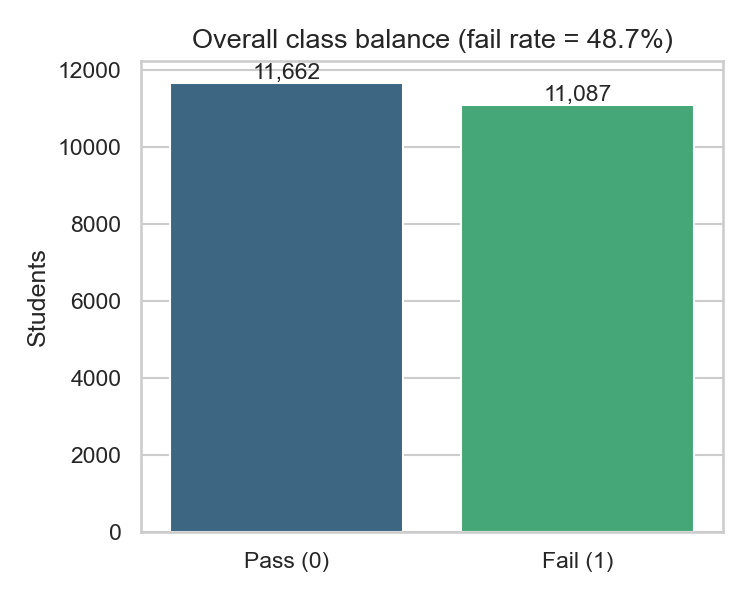

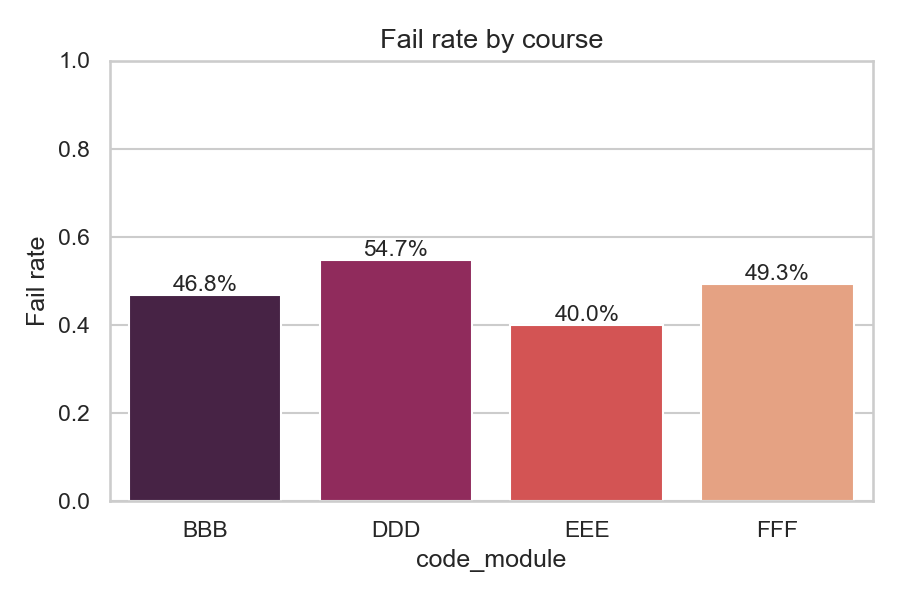

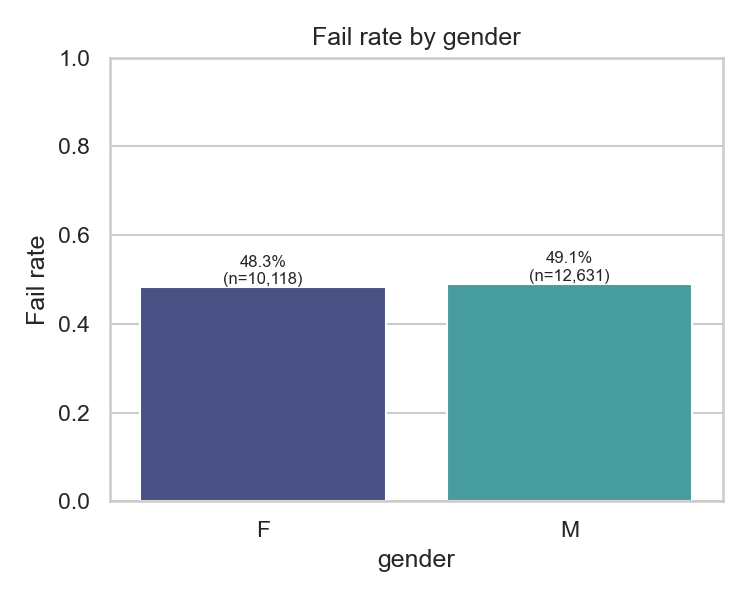

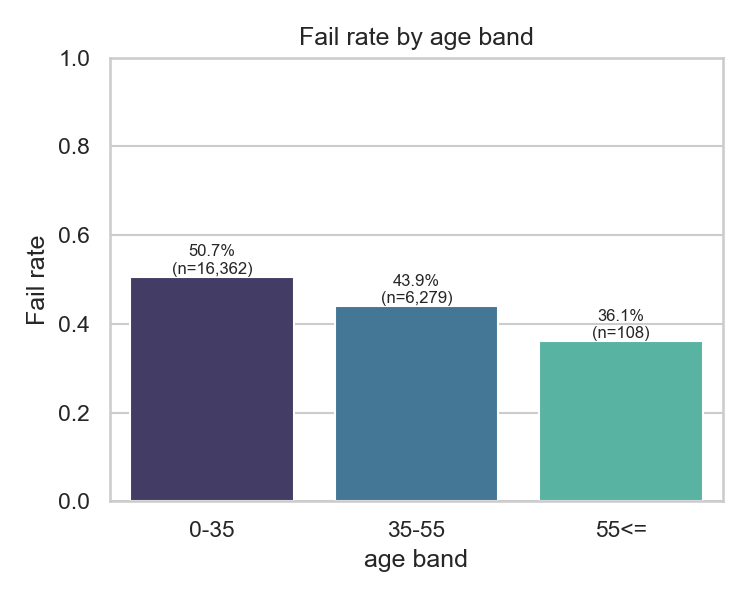

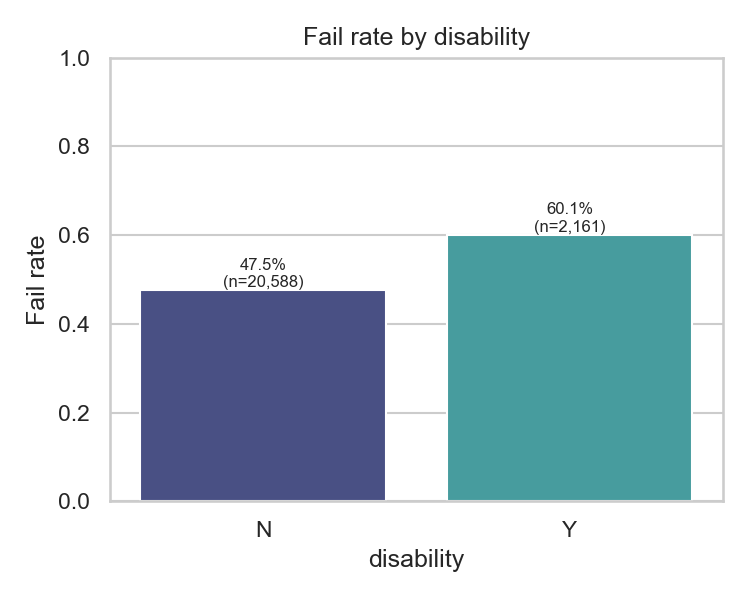

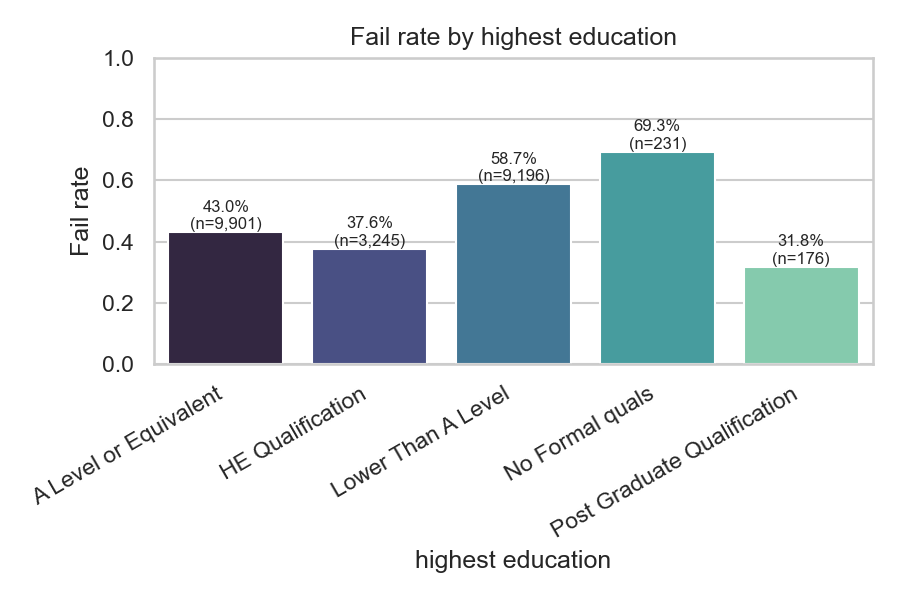

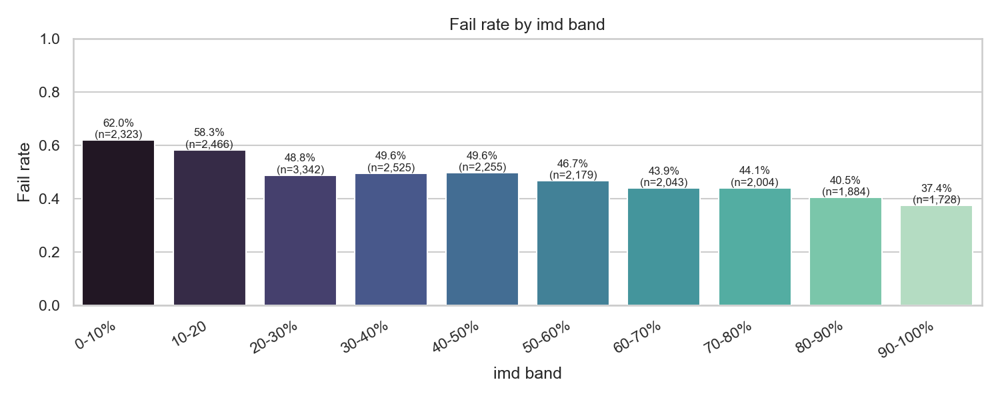

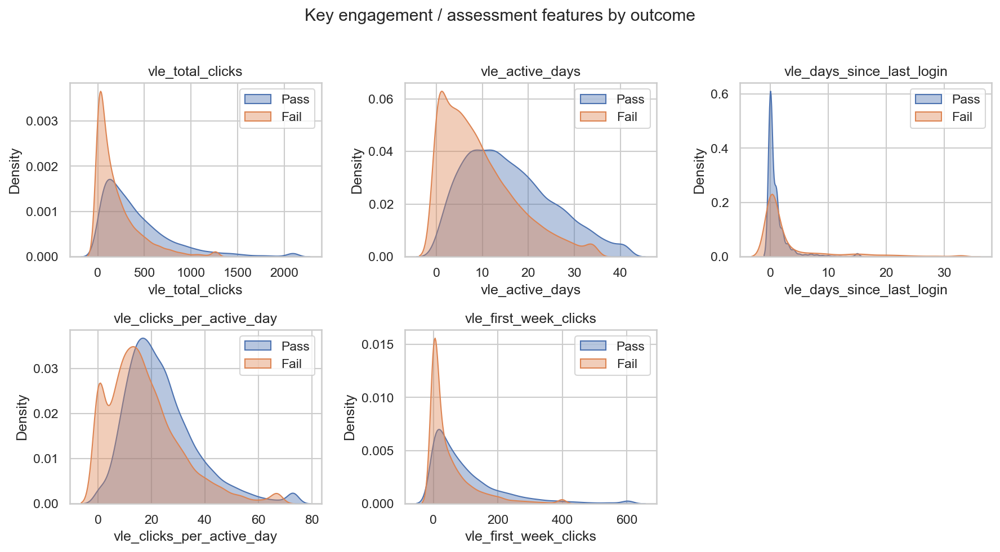

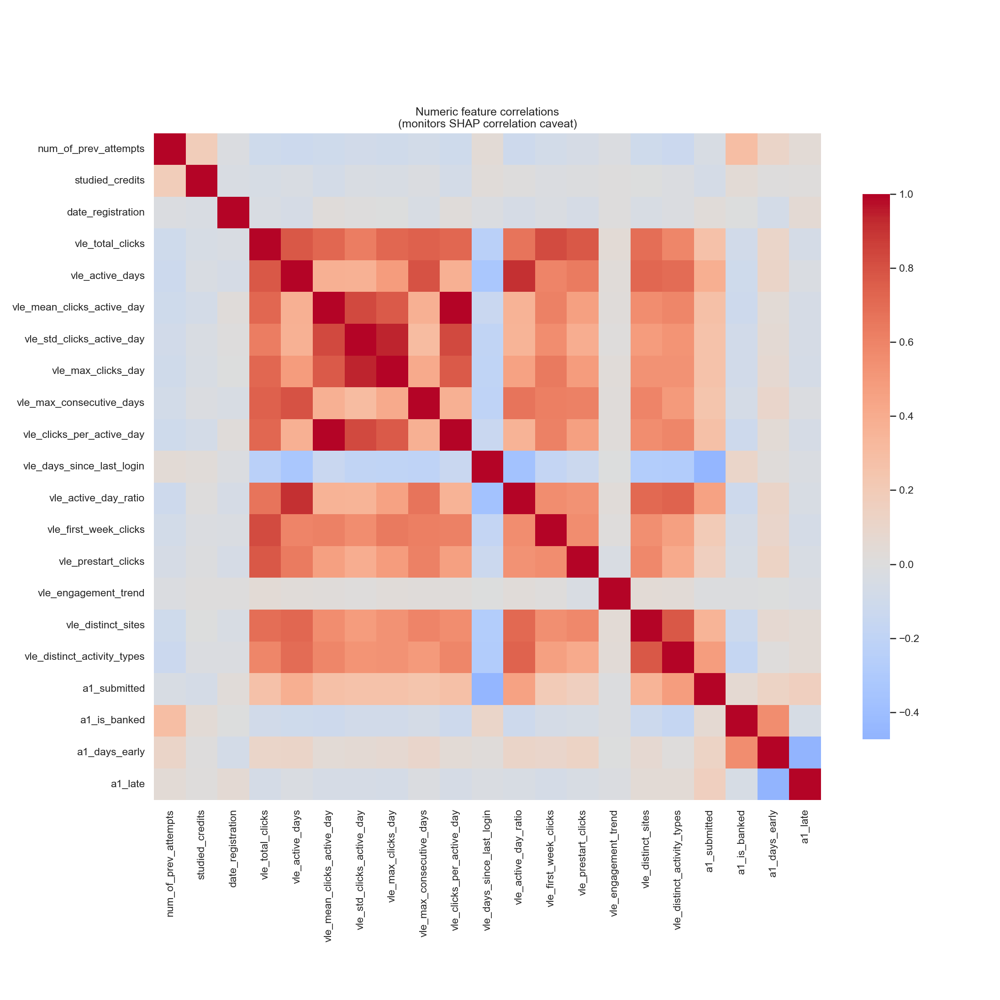

In [12]:
# Run exploratory data analysis (EDA) and display generated visualisations
# when enabled; otherwise, log that EDA has been skipped.
if RUN_EDA:
    run_eda(features, feature_cols)
    show_images([
        config.FIGURE_DIR / "eda_class_balance.png",
        config.FIGURE_DIR / "eda_fail_rate_by_course.png",
        config.FIGURE_DIR / "eda_failrate_by_gender.png",
        config.FIGURE_DIR / "eda_failrate_by_age_band.png",
        config.FIGURE_DIR / "eda_failrate_by_disability.png",
        config.FIGURE_DIR / "eda_failrate_by_highest_education.png",
        config.FIGURE_DIR / "eda_failrate_by_imd_band.png",
        config.FIGURE_DIR / "eda_feature_distributions.png",
        config.FIGURE_DIR / "eda_correlation_heatmap.png",
    ])
else:
    logger.info("RUN_EDA = False — skipping EDA.")

## §6 · Class-imbalance strategies  *(Phase 2)*

For each model we compare **no resampling**, **SMOTE** (applied inside each CV
fold so it never touches validation data), and **cost-sensitive class
weighting**, and keep whichever maximises cross-validated PR-AUC.

In [13]:
def _build_pipeline(model_name: str, strategy: str, categorical, numeric,
                    y_train=None) -> ImbPipeline:
    """Assemble preprocessor -> [SMOTE] -> classifier for a given strategy."""
    scale = model_name not in SCALE_FREE_MODELS
    pre = build_preprocessor(categorical, numeric, scale=scale)

    class_weight = None
    if strategy == "class_weight" and model_name in SUPPORTS_CLASS_WEIGHT:
        class_weight = "balanced"

    clf = get_classifier(model_name, class_weight=class_weight)

    # XGBoost uses scale_pos_weight rather than class_weight.
    if model_name == "xgboost" and strategy == "class_weight" and y_train is not None:
        clf.set_params(scale_pos_weight=xgb_scale_pos_weight(y_train))

    steps = [("pre", pre)]
    if strategy == "smote":
        steps.append(("smote", SMOTE(random_state=config.RANDOM_STATE)))
    steps.append(("classifier", clf))
    return ImbPipeline(steps)


def select_strategy(model_name: str, X_train: pd.DataFrame, y_train,
                    categorical, numeric,
                    folds: int = None) -> Tuple[str, Dict[str, float]]:
    """Return the best imbalance strategy for ``model_name`` and the full
    table of mean CV PR-AUC per strategy.
    """
    skf = StratifiedKFold(n_splits=(folds or config.CV_FOLDS), shuffle=True,
                          random_state=config.RANDOM_STATE)
    scores: Dict[str, float] = {}

    for strat in config.IMBALANCE_STRATEGIES:
        if strat == "class_weight" and model_name not in SUPPORTS_CLASS_WEIGHT:
            continue
        pipe = _build_pipeline(model_name, strat, categorical, numeric, y_train)
        try:
            cv = cross_val_score(pipe, X_train, y_train, cv=skf,
                                 scoring="average_precision", n_jobs=1)
            scores[strat] = float(np.mean(cv))
            logger.info("  [%s] strategy=%-12s CV PR-AUC=%.4f (+/-%.4f)",
                        model_name, strat, np.mean(cv), np.std(cv))
        except Exception as exc:                       # pragma: no cover
            logger.warning("  [%s] strategy=%s failed: %s",
                           model_name, strat, exc)

    if not scores:
        # Every strategy errored (e.g. a fold too small to resample). Fall back
        # to a safe default so the wider pipeline degrades gracefully.
        fallback = ("class_weight"
                    if model_name in SUPPORTS_CLASS_WEIGHT else "none")
        logger.warning("  [%s] all strategies failed; falling back to '%s'",
                       model_name, fallback)
        return fallback, {fallback: float("nan")}

    best = max(scores, key=scores.get)
    logger.info("  -> best strategy for %s: %s (PR-AUC=%.4f)",
                model_name, best, scores[best])
    return best, scores

## §7 · Models  *(Phase 3)*

Four models behind one scikit-learn-compatible interface: Logistic Regression
(interpretable baseline), Random Forest, XGBoost (primary), and a Keras MLP with
dropout. A single transformer one-hot-encodes categoricals, scales numerics for
LR/MLP (tree models skip scaling), and **sanitises feature names**. OULAD
produces names such as `age_band=55<=` that XGBoost rejects.

In [14]:
# Models that natively support cost-sensitive class weighting.
SUPPORTS_CLASS_WEIGHT = {"logreg", "random_forest", "xgboost", "mlp"}
# Tree models do not require feature scaling.
SCALE_FREE_MODELS = {"random_forest", "xgboost"}


# --------------------------------------------------------------------------- #
# Column-name sanitiser
# --------------------------------------------------------------------------- #
# XGBoost >= 1.7 rejects feature names containing the characters ``[ ] <``.
# OULAD produces such names after one-hot encoding (e.g. ``age_band_55<=`` and
# the engineered ``a1_score_band_fail_<40``). We therefore sanitise *every*
# feature name once, immediately after the ColumnTransformer, so that the
# models, the persisted pipelines and the SHAP explainers all observe the same
# clean names.
_UNSAFE_CHARS = re.compile(r"[\[\]<>,{}\":]+")


def _sanitize_name(name: str) -> str:
    clean = _UNSAFE_CHARS.sub("_", str(name))
    clean = re.sub(r"\s+", "_", clean)
    clean = re.sub(r"_+", "_", clean).strip("_")
    return clean or "feature"


class _SanitizingPreprocessor(BaseEstimator, TransformerMixin):
    """ColumnTransformer + name sanitisation behind a single estimator.

    imbalanced-learn forbids nested Pipelines as intermediate pipeline steps,
    so we expose the (encode -> scale -> sanitise) chain as one transformer.
    Emits a pandas DataFrame with model-safe, unique column names.
    """

    def __init__(self, categorical, numeric, scale=True):
        self.categorical = categorical
        self.numeric = numeric
        self.scale = scale

    def _build_ct(self) -> ColumnTransformer:
        num_tf = StandardScaler() if self.scale else "passthrough"
        ct = ColumnTransformer(
            transformers=[
                ("cat", OneHotEncoder(handle_unknown="ignore",
                                      sparse_output=False), list(self.categorical)),
                ("num", num_tf, list(self.numeric)),
            ],
            remainder="drop",
            verbose_feature_names_out=False,
        )
        ct.set_output(transform="pandas")
        return ct

    def fit(self, X, y=None):
        self.ct_ = self._build_ct()
        Xt = self.ct_.fit_transform(X)
        seen: dict[str, int] = {}
        out = []
        for c in Xt.columns:
            base = _sanitize_name(c)
            if base in seen:
                seen[base] += 1
                base = f"{base}_{seen[base]}"
            else:
                seen[base] = 0
            out.append(base)
        self.feature_names_out_ = np.asarray(out, dtype=object)
        return self

    def transform(self, X):
        Xt = self.ct_.transform(X)
        Xt.columns = self.feature_names_out_
        return Xt

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_


# --------------------------------------------------------------------------- #
# Preprocessor
# --------------------------------------------------------------------------- #
def build_preprocessor(categorical: Sequence[str],
                       numeric: Sequence[str],
                       scale: bool = True) -> _SanitizingPreprocessor:
    """One-hot encode categoricals; standardise numerics when ``scale``.

    Returns a single transformer emitting a pandas DataFrame with model-safe
    column names (XGBoost rejects ``[ ] <`` characters that OULAD produces).
    """
    return _SanitizingPreprocessor(categorical, numeric, scale=scale)


# --------------------------------------------------------------------------- #
# Keras MLP wrapped for scikit-learn
# --------------------------------------------------------------------------- #
class KerasMLPClassifier(ClassifierMixin, BaseEstimator):
    """A small feed-forward network with dropout, exposed through the
    scikit-learn estimator API (fit / predict / predict_proba).

    ``ClassifierMixin`` precedes ``BaseEstimator`` so that scikit-learn's tag
    system correctly identifies this as a classifier (needed for probability
    scoring inside cross-validation)."""

    _estimator_type = "classifier"

    def __init__(self, hidden_units=(128, 64), dropout=0.3, learning_rate=1e-3,
                 batch_size=256, epochs=80, patience=10, class_weight=None,
                 random_state=config.RANDOM_STATE, verbose=0):
        self.hidden_units = hidden_units
        self.dropout = dropout
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.patience = patience
        self.class_weight = class_weight
        self.random_state = random_state
        self.verbose = verbose

    # -- internal builder --------------------------------------------------- #
    def _build(self, n_features: int):
        import tensorflow as tf
        from tensorflow.keras import layers, models

        tf.get_logger().setLevel("ERROR")   # hush deprecation / GPU notices

        # Release graphs/weights from previous fits; across many CV folds this
        # prevents unbounded TensorFlow memory growth.
        tf.keras.backend.clear_session()
        tf.random.set_seed(self.random_state)
        net = models.Sequential(name="mlp_dropout")
        net.add(layers.Input(shape=(n_features,)))
        for units in self.hidden_units:
            net.add(layers.Dense(units, activation="relu"))
            net.add(layers.Dropout(self.dropout))      # dropout regularisation
        net.add(layers.Dense(1, activation="sigmoid"))
        net.compile(
            optimizer=tf.keras.optimizers.Adam(self.learning_rate),
            loss="binary_crossentropy",
            metrics=[tf.keras.metrics.AUC(curve="PR", name="pr_auc")],
        )
        return net

    # -- sklearn API -------------------------------------------------------- #
    def fit(self, X, y):
        import tensorflow as tf

        X = np.asarray(X, dtype="float32")
        y = np.asarray(y, dtype="float32").ravel()
        self.classes_ = np.unique(y)
        self.n_features_in_ = X.shape[1]
        self.model_ = self._build(X.shape[1])

        cw = None
        if self.class_weight == "balanced":
            pos = float(y.sum())
            neg = float(len(y) - pos)
            total = pos + neg
            cw = {0: total / (2 * neg), 1: total / (2 * pos)}
        elif isinstance(self.class_weight, dict):
            cw = self.class_weight

        es = tf.keras.callbacks.EarlyStopping(
            monitor="val_pr_auc", mode="max", patience=self.patience,
            restore_best_weights=True,
        )
        self.model_.fit(
            X, y,
            validation_split=0.15,
            epochs=self.epochs,
            batch_size=self.batch_size,
            class_weight=cw,
            callbacks=[es],
            verbose=self.verbose,
        )
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype="float32")
        p = self.model_.predict(X, verbose=0).ravel()
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


# --------------------------------------------------------------------------- #
# Model factory
# --------------------------------------------------------------------------- #
def get_classifier(name: str, class_weight=None):
    """Instantiate a classifier by name with optional class weighting."""
    if name == "logreg":
        return LogisticRegression(
            class_weight=class_weight, max_iter=2000, n_jobs=None,
            random_state=config.RANDOM_STATE,
        )
    if name == "random_forest":
        return RandomForestClassifier(
            class_weight=class_weight, n_estimators=400, n_jobs=-1,
            random_state=config.RANDOM_STATE,
        )
    if name == "xgboost":
        spw = None
        # scale_pos_weight is XGBoost's cost-sensitive lever
        kwargs = dict(
            n_estimators=400, max_depth=6, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
            tree_method="hist", random_state=config.RANDOM_STATE, n_jobs=-1,
        )
        if class_weight == "balanced":
            kwargs["scale_pos_weight"] = "balanced_placeholder"  # set at fit
        return XGBClassifier(**{k: v for k, v in kwargs.items()
                                if v != "balanced_placeholder"})
    if name == "mlp":
        p = config.MLP_PARAMS
        return KerasMLPClassifier(
            hidden_units=p["hidden_units"], dropout=p["dropout"],
            learning_rate=p["learning_rate"], batch_size=p["batch_size"],
            epochs=p["epochs"], patience=p["patience"],
            class_weight=class_weight,
        )
    raise ValueError(f"Unknown model '{name}'")


def xgb_scale_pos_weight(y) -> float:
    """Compute XGBoost scale_pos_weight = n_neg / n_pos for class weighting."""
    y = np.asarray(y)
    pos = max(int((y == 1).sum()), 1)
    neg = int((y == 0).sum())
    return neg / pos


MODEL_NAMES = ["logreg", "random_forest", "xgboost", "mlp"]
PARAM_SEARCH = {
    "logreg": config.LOGREG_PARAMS,
    "random_forest": config.RF_PARAM_DIST,
    "xgboost": config.XGB_PARAM_DIST,
}

## §8 · Training & evaluation  *(Phase 3)*

Metrics first (PR-AUC primary, ROC-AUC, F1, confusion counts), then the
per-course training routine: stratified split, imbalance-strategy selection,
hyper-parameter search, held-out evaluation, and persistence of the fitted
pipeline plus the transformed matrices SHAP needs.

In [15]:
def compute_metrics(y_true, proba, threshold: float = config.DECISION_THRESHOLD
                    ) -> Dict[str, float]:
    """Return PR-AUC, ROC-AUC and thresholded F1 (plus precision/recall)."""
    y_true = np.asarray(y_true)
    proba = np.asarray(proba)
    y_pred = (proba >= threshold).astype(int)

    # ROC-AUC is undefined if only one class present in y_true.
    try:
        roc = roc_auc_score(y_true, proba)
    except ValueError:
        roc = float("nan")

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0

    return {
        "pr_auc": float(average_precision_score(y_true, proba)),
        "roc_auc": float(roc),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "precision": float(precision),
        "recall": float(recall),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }


def plot_curves(results: Dict[str, dict], course: str) -> None:
    """Overlay PR and ROC curves for all models of a course.

    ``results[name]`` must contain 'y_true' and 'proba'.
    """
    fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))
    for name, r in results.items():
        y_true, proba = r["y_true"], r["proba"]
        prec, rec, _ = precision_recall_curve(y_true, proba)
        ap = average_precision_score(y_true, proba)
        ax_pr.plot(rec, prec, label=f"{name} (AP={ap:.3f})")

        fpr, tpr, _ = roc_curve(y_true, proba)
        try:
            auc = roc_auc_score(y_true, proba)
        except ValueError:
            auc = float("nan")
        ax_roc.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

    base_rate = float(np.mean(list(results.values())[0]["y_true"]))
    ax_pr.axhline(base_rate, ls="--", color="grey",
                  label=f"baseline={base_rate:.3f}")
    ax_pr.set_xlabel("Recall", fontsize=13)
    ax_pr.set_ylabel("Precision", fontsize=13)
    ax_pr.set_title(f"Precision-Recall - {course}", fontsize=14)
    ax_pr.tick_params(labelsize=11)
    ax_pr.legend(loc="best", fontsize=11)

    ax_roc.plot([0, 1], [0, 1], ls="--", color="grey")
    ax_roc.set_xlabel("False positive rate", fontsize=13)
    ax_roc.set_ylabel("True positive rate", fontsize=13)
    ax_roc.set_title(f"ROC - {course}", fontsize=14)
    ax_roc.tick_params(labelsize=11)
    ax_roc.legend(loc="best", fontsize=11)

    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / f"eval_curves_{course}.png", dpi=150)
    plt.close(fig)


def plot_confusion(y_true, proba, course: str, model: str,
                   threshold: float = config.DECISION_THRESHOLD) -> None:
    """Save a labelled confusion matrix heatmap."""
    import seaborn as sns

    y_pred = (np.asarray(proba) >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["Pass", "Fail"],
                yticklabels=["Pass", "Fail"], ax=ax)
    ax.set(xlabel="Predicted", ylabel="Actual",
           title=f"{model} - {course}")
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / f"eval_confusion_{course}_{model}.png",
                dpi=150)
    plt.close(fig)

In [16]:
warnings.filterwarnings("ignore", category=UserWarning)

def _make_pipeline(model_name: str, strategy: str, categorical, numeric,
                   y_train) -> ImbPipeline:
    """Create a machine learning pipeline with preprocessing, optional imbalance
    handling (SMOTE/class weights), and the selected classifier.
    """
    scale = model_name not in SCALE_FREE_MODELS
    pre = build_preprocessor(categorical, numeric, scale=scale)
    class_weight = "balanced" if (strategy == "class_weight"
                                  and model_name in SUPPORTS_CLASS_WEIGHT) else None
    clf = get_classifier(model_name, class_weight=class_weight)
    if model_name == "xgboost" and strategy == "class_weight":
        clf.set_params(scale_pos_weight=xgb_scale_pos_weight(y_train))
    steps = [("pre", pre)]
    if strategy == "smote":
        steps.append(("smote", SMOTE(random_state=config.RANDOM_STATE)))
    steps.append(("classifier", clf))
    return ImbPipeline(steps)


def _tune(model_name: str, pipe: ImbPipeline, X_train, y_train):
    """Hyper-parameter search where a search space is defined."""
    skf = StratifiedKFold(n_splits=config.CV_FOLDS, shuffle=True,
                          random_state=config.RANDOM_STATE)
    if model_name == "logreg":
        search = GridSearchCV(pipe, PARAM_SEARCH["logreg"], cv=skf,
                              scoring="average_precision", n_jobs=1, refit=True)
    elif model_name in ("random_forest", "xgboost"):
        search = RandomizedSearchCV(
            pipe, PARAM_SEARCH[model_name], n_iter=config.N_RANDOM_SEARCH_ITER,
            cv=skf, scoring="average_precision", n_jobs=1,
            random_state=config.RANDOM_STATE, refit=True,
        )
    else:                                    # MLP: no search, fit directly
        pipe.fit(X_train, y_train)
        return pipe, {}
    search.fit(X_train, y_train)
    logger.info("  [%s] best CV PR-AUC=%.4f | params=%s",
                model_name, search.best_score_, search.best_params_)
    return search.best_estimator_, search.best_params_


def train_course(df_course: pd.DataFrame, feature_cols: Dict[str, list],
                 course: str) -> Dict[str, dict]:
    """Train and evaluate all four models for a single course."""
    banner(logger, f"PHASE 3 | Modelling course {course}")

    categorical = feature_cols["categorical"]
    numeric = feature_cols["numeric"]
    feat_all = categorical + numeric

    X = df_course[feat_all].copy()
    y = df_course["target"].astype(int).to_numpy()

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=config.TEST_SIZE, stratify=y,
        random_state=config.RANDOM_STATE,
    )
    logger.info("course=%s | train=%d test=%d | train fail rate=%.3f",
                course, len(X_train), len(X_test), float(np.mean(y_train)))

    results: Dict[str, dict] = {}
    for model_name in MODEL_NAMES:
        logger.info("-" * 60)
        logger.info("Model: %s", model_name)

        # 1) choose imbalance strategy
        strategy, strat_scores = select_strategy(
            model_name, X_train, y_train, categorical, numeric)

        # 2) build + tune
        pipe = _make_pipeline(model_name, strategy, categorical, numeric, y_train)
        best_pipe, best_params = _tune(model_name, pipe, X_train, y_train)

        # 3) test-set evaluation
        proba = best_pipe.predict_proba(X_test)[:, 1]
        metrics = compute_metrics(y_test, proba)
        logger.info("  [%s] TEST  PR-AUC=%.4f  ROC-AUC=%.4f  F1=%.4f",
                    model_name, metrics["pr_auc"], metrics["roc_auc"],
                    metrics["f1"])

        # 4) transformed matrices + feature names for SHAP
        pre = best_pipe.named_steps["pre"]
        clf = best_pipe.named_steps["classifier"]
        X_train_t = pre.transform(X_train)
        X_test_t = pre.transform(X_test)
        feat_names = list(X_test_t.columns)

        # persist model
        joblib.dump(best_pipe,
                    config.MODEL_DIR / f"{course}_{model_name}.joblib")

        results[model_name] = {
            "pipeline": best_pipe,
            "classifier": clf,
            "preprocessor": pre,
            "strategy": strategy,
            "strategy_scores": strat_scores,
            "best_params": best_params,
            "metrics": metrics,
            "proba": proba,
            "y_true": y_test,
            "X_train_t": X_train_t,
            "X_test_t": X_test_t,
            "X_test_raw": X_test.reset_index(drop=True),
            "feat_names": feat_names,
            "scaled": model_name not in SCALE_FREE_MODELS,
        }
        plot_confusion(y_test, proba, course, model_name)

    # PR/ROC overlay + metrics table
    plot_curves({k: {"y_true": v["y_true"], "proba": v["proba"]}
                   for k, v in results.items()}, course)
    _save_metrics_table(results, course)
    return results


def _save_metrics_table(results: Dict[str, dict], course: str) -> None:
    """Save model evaluation metrics for a course as a CSV file and log a summary
     of the key performance measures.
    """
    rows = []
    for name, r in results.items():
        m = r["metrics"]
        rows.append({
            "course": course, "model": name, "strategy": r["strategy"],
            "pr_auc": m["pr_auc"], "roc_auc": m["roc_auc"], "f1": m["f1"],
            "precision": m["precision"], "recall": m["recall"],
            "tp": m["tp"], "fp": m["fp"], "fn": m["fn"], "tn": m["tn"],
        })
    tab = pd.DataFrame(rows).sort_values("pr_auc", ascending=False)
    path = config.TABLE_DIR / f"metrics_{course}.csv"
    tab.to_csv(path, index=False)
    logger.info("Saved metrics table -> %s\n%s", path,
                tab[["model", "strategy", "pr_auc", "roc_auc", "f1"]]
                .to_string(index=False))


def best_model_name(results: Dict[str, dict]) -> str:
    """Name of the best model for a course by the primary metric."""
    return max(results, key=lambda k: results[k]["metrics"][config.PRIMARY_METRIC])

20:21:31 | INFO    | ======================================================================
20:21:31 | INFO    | PHASE 3 | Modelling course BBB
20:21:31 | INFO    | ======================================================================
20:21:31 | INFO    | course=BBB | train=5641 test=1411 | train fail rate=0.468
20:21:31 | INFO    | ------------------------------------------------------------
20:21:31 | INFO    | Model: logreg
20:21:32 | INFO    |   [logreg] strategy=none         CV PR-AUC=0.8027 (+/-0.0106)
20:21:34 | INFO    |   [logreg] strategy=smote        CV PR-AUC=0.8026 (+/-0.0105)
20:21:35 | INFO    |   [logreg] strategy=class_weight CV PR-AUC=0.8028 (+/-0.0106)
20:21:35 | INFO    |   -> best strategy for logreg: class_weight (PR-AUC=0.8028)
20:21:36 | INFO    |   [logreg] best CV PR-AUC=0.8029 | params={'classifier__C': 0.1, 'classifier__max_iter': 2000}
20:21:36 | INFO    |   [logreg] TEST  PR-AUC=0.8047  ROC-AUC=0.7847  F1=0.6574
20:21:37 | INFO    | ----------------------

### Course BBB — held-out metrics

,course,model,strategy,pr_auc,roc_auc,f1,precision,recall,tp,fp,fn,tn
0,BBB,xgboost,class_weight,0.8147,0.7966,0.6867,0.7630,0.6242,412,128,248,623
1,BBB,mlp,class_weight,0.8075,0.7898,0.6599,0.7424,0.5939,392,136,268,615
2,BBB,logreg,class_weight,0.8047,0.7847,0.6574,0.7181,0.6061,400,157,260,594
3,BBB,random_forest,smote,0.8043,0.7887,0.6554,0.7381,0.5894,389,138,271,613


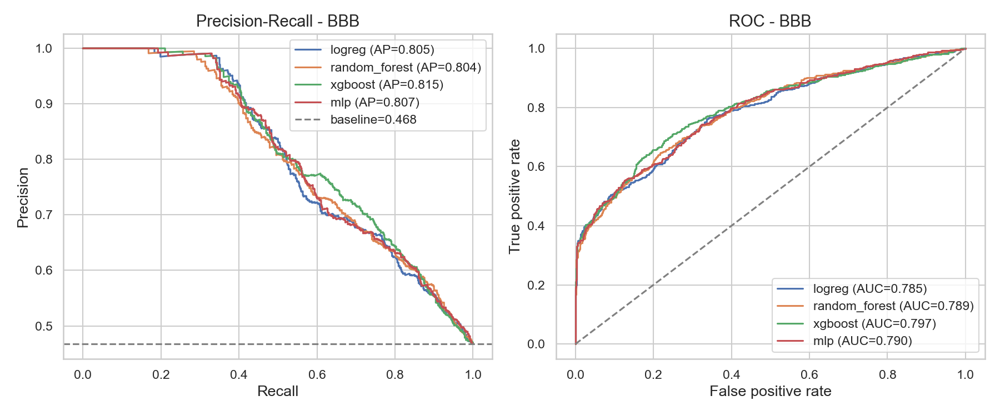

### Course DDD — held-out metrics

,course,model,strategy,pr_auc,roc_auc,f1,precision,recall,tp,fp,fn,tn
0,DDD,xgboost,smote,0.8450,0.8098,0.7299,0.7822,0.6841,431,120,199,402
1,DDD,logreg,class_weight,0.8444,0.8100,0.7263,0.8118,0.6571,414,96,216,426
2,DDD,random_forest,smote,0.8405,0.7995,0.7197,0.7909,0.6603,416,110,214,412
3,DDD,mlp,none,0.8292,0.7907,0.7335,0.7743,0.6968,439,128,191,394


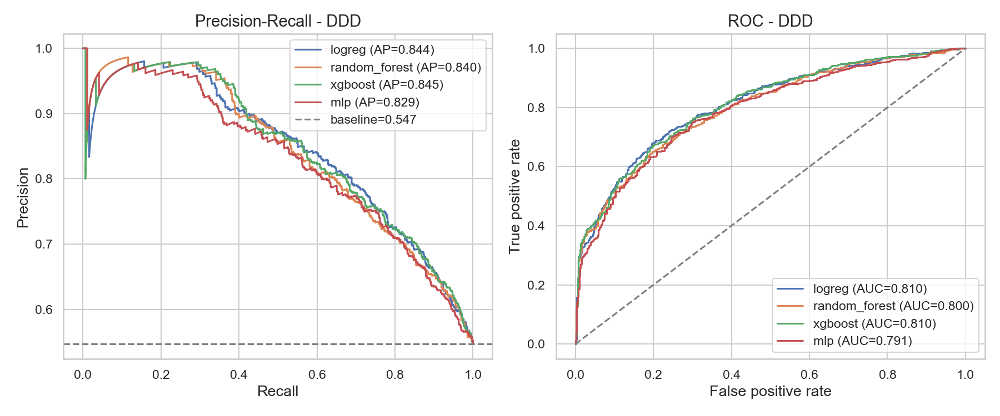

### Course EEE — held-out metrics

,course,model,strategy,pr_auc,roc_auc,f1,precision,recall,tp,fp,fn,tn
0,EEE,xgboost,smote,0.8355,0.8428,0.7074,0.8581,0.6018,133,22,88,308
1,EEE,logreg,class_weight,0.8286,0.8442,0.6946,0.7622,0.6380,141,44,80,286
2,EEE,random_forest,class_weight,0.8265,0.8380,0.7026,0.8107,0.6199,137,32,84,298
3,EEE,mlp,none,0.8249,0.8445,0.6845,0.8366,0.5792,128,25,93,305


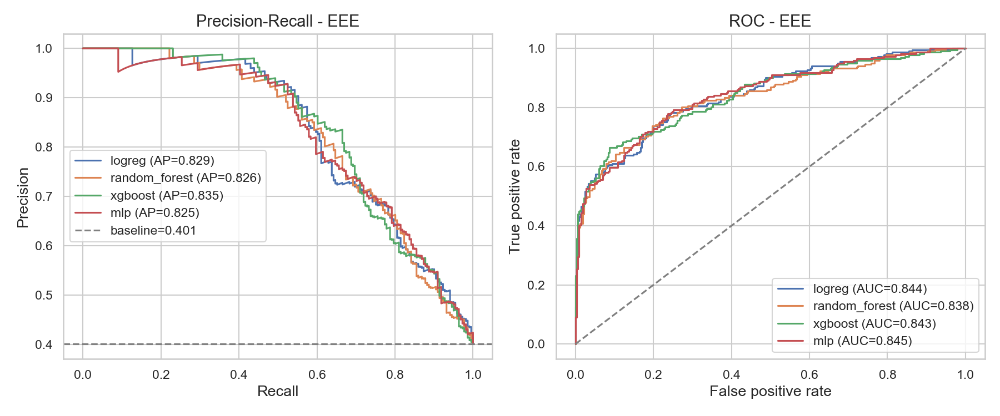

### Course FFF — held-out metrics

,course,model,strategy,pr_auc,roc_auc,f1,precision,recall,tp,fp,fn,tn
0,FFF,xgboost,class_weight,0.8206,0.7961,0.6934,0.7451,0.6483,459,157,249,573
1,FFF,logreg,class_weight,0.8173,0.7952,0.7009,0.7532,0.6554,464,152,244,578
2,FFF,mlp,none,0.8165,0.7921,0.7014,0.7545,0.6554,464,151,244,579
3,FFF,random_forest,smote,0.8081,0.7866,0.6881,0.7294,0.6511,461,171,247,559


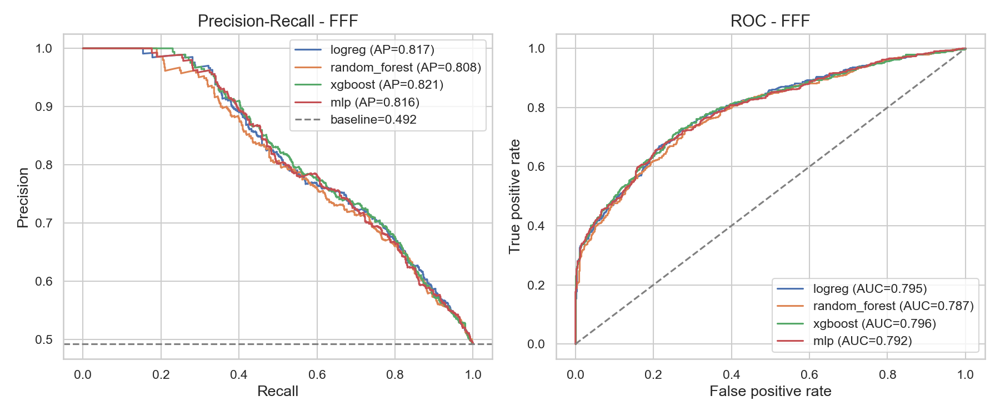

In [17]:
# Train and evaluate all models for each course, then store the results and
# record the best-performing model and its evaluation metrics.
all_results: Dict[str, Dict[str, dict]] = {}
summary = {}

for course, df_c in course_frames.items():
    results = train_course(df_c, feature_cols, course)
    all_results[course] = results
    best = best_model_name(results)
    summary[course] = {
        "best_model": best,
        "best_pr_auc": results[best]["metrics"]["pr_auc"],
        "per_model": {m: results[m]["metrics"] for m in results},
    }

# Show the held-out leaderboard and diagnostic curves per course.
for course in all_results:
    display(Markdown(f"### Course {course} — held-out metrics"))
    display(pd.read_csv(config.TABLE_DIR / f"metrics_{course}.csv")
            .round(4))
    show_images([config.FIGURE_DIR / f"eval_curves_{course}.png"])

## §9 · Explainability with SHAP  *(Phase 4)*

For each course's best model we compute SHAP values (TreeExplainer/a sampled model-agnostic explainer for
RF/XGBoost, LinearExplainer for Logistic Regression, KernelExplainer on a
sample for the MLP) and produce a global beeswarm + mean-|SHAP| ranking, plus
per-student **waterfall** plots for representative true-positive, false-positive
and false-negative cases.

In [18]:
# --------------------------------------------------------------------------- #
# SHAP value computation (normalised across explainers)
# --------------------------------------------------------------------------- #
def _positive_class(values, base):
    """Reduce multi-output SHAP results to the positive (fail) class."""
    values = np.asarray(values)
    if values.ndim == 3:                     # (n, features, classes)
        values = values[:, :, 1]
    if np.ndim(base) > 0 and np.asarray(base).size > 1:
        base = np.asarray(base)[1]
    return values, float(np.asarray(base).ravel()[0])


def _sampled_proba_shap(clf, X_train_t: pd.DataFrame, X_test_t: pd.DataFrame):
    """Model-agnostic SHAP on ``predict_proba`` for the positive class,
    computed on a sample against a background set.

    Used for the MLP and as a robust fallback when ``TreeExplainer`` cannot read
    a fitted model. (Some SHAP / XGBoost version combinations can serialise
    ``base_score`` as a bracketed string such as ``"[4.6E-1]"``, 
    which can cause TreeExplainer to fail during model passing;
    this path sidesteps that entirely.)
    """
    cols = list(X_test_t.columns)
    bg = shap.sample(X_train_t,
                     min(config.SHAP_BACKGROUND_SIZE, len(X_train_t)),
                     random_state=config.RANDOM_STATE)
    n = min(config.SHAP_KERNEL_SAMPLE, len(X_test_t))
    X_sample = X_test_t.iloc[:n].reset_index(drop=True)

    def f(data):
        # KernelExplainer feeds numpy arrays; restore column names so models
        # fitted on a DataFrame (e.g. XGBoost) don't complain.
        if not isinstance(data, pd.DataFrame):
            data = pd.DataFrame(data, columns=cols)
        return clf.predict_proba(data)[:, 1]

    explainer = shap.KernelExplainer(f, bg)
    sv = explainer.shap_values(X_sample, nsamples="auto")
    values = np.asarray(sv)
    if values.ndim == 3:
        values = values[:, :, 1]
    base = float(np.asarray(explainer.expected_value).ravel()[0])
    return values, base, X_sample


def compute_shap(model_name: str, clf, X_train_t: pd.DataFrame,
                 X_test_t: pd.DataFrame):
    """Return (shap_values [n,feat], base_value, X_explained DataFrame).

    Tree models use the fast, exact ``TreeExplainer``; if that fails for any
    reason we fall back to a sampled model-agnostic explainer so SHAP always
    returns a result rather than skipping the model.
    """
    if model_name in ("xgboost", "random_forest"):
        try:
            explainer = shap.TreeExplainer(clf)
            exp = explainer(X_test_t, check_additivity=False)
            values, base = _positive_class(exp.values, exp.base_values)
            return values, base, X_test_t
        except Exception as exc:
            logger.warning(
                "TreeExplainer unavailable for %s (%s); falling back to a "
                "sampled model-agnostic explainer. ",
                model_name, exc)
            return _sampled_proba_shap(clf, X_train_t, X_test_t)

    if model_name == "logreg":
        masker = shap.maskers.Independent(X_train_t, max_samples=200)
        explainer = shap.LinearExplainer(clf, masker)
        exp = explainer(X_test_t)
        values, base = _positive_class(exp.values, exp.base_values)
        return values, base, X_test_t

    if model_name == "mlp":
        return _sampled_proba_shap(clf, X_train_t, X_test_t)

    raise ValueError(model_name)


# --------------------------------------------------------------------------- #
# Plots
# --------------------------------------------------------------------------- #
def _global_plots(values, X_exp, course, model_name) -> pd.DataFrame:
    feat_names = list(X_exp.columns)

    # beeswarm
    plt.figure()
    shap.summary_plot(values, X_exp, feature_names=feat_names, show=False,
                      max_display=20)
    plt.title(f"SHAP summary - {course} ({model_name})")
    plt.tight_layout()
    plt.savefig(config.SHAP_DIR / f"shap_summary_{course}_{model_name}.png",
                dpi=150, bbox_inches="tight")
    plt.close()

    # mean |SHAP| bar
    plt.figure()
    shap.summary_plot(values, X_exp, feature_names=feat_names, show=False,
                      plot_type="bar", max_display=20)
    plt.title(f"Mean |SHAP| - {course} ({model_name})")
    # SHAP's default x-label is verbose and gets truncated; use a short one.
    plt.gca().set_xlabel("mean(|SHAP value|)")
    plt.tight_layout()
    plt.savefig(config.SHAP_DIR / f"shap_bar_{course}_{model_name}.png",
                dpi=150, bbox_inches="tight")
    plt.close()

    mean_abs = np.abs(values).mean(axis=0)
    ranking = (pd.DataFrame({"feature": feat_names, "mean_abs_shap": mean_abs})
               .sort_values("mean_abs_shap", ascending=False))
    ranking.to_csv(config.SHAP_DIR /
                   f"shap_importance_{course}_{model_name}.csv", index=False)
    return ranking


def _representative_indices(y_true, proba, n: int) -> Dict[str, list]:
    """Pick n true-positive, false-positive and false-negative test rows."""
    y_true = np.asarray(y_true)
    proba = np.asarray(proba)
    pred = (proba >= config.DECISION_THRESHOLD).astype(int)

    tp = np.where((y_true == 1) & (pred == 1))[0]
    fp = np.where((y_true == 0) & (pred == 1))[0]
    fn = np.where((y_true == 1) & (pred == 0))[0]

    tp = tp[np.argsort(-proba[tp])][:n]      # most confident correct at-risk
    fp = fp[np.argsort(-proba[fp])][:n]      # most confident wrong alarm
    fn = fn[np.argsort(proba[fn])][:n]       # most confidently missed
    return {"true_positive": tp.tolist(),
            "false_positive": fp.tolist(),
            "false_negative": fn.tolist()}


def _waterfall(values, base, X_exp, idx, course, model_name, case, rank):
    expl = shap.Explanation(
        values=values[idx],
        base_values=base,
        data=X_exp.iloc[idx].to_numpy(),
        feature_names=list(X_exp.columns),
    )
    # Wide canvas and larger fonts were used to keep the long OULAD feature names
    # and SHAP visualisations readable when combined into a full-width report figure.
    # The top 10 features were displayed to maintain clarity and spacing, while the
    # remaining features were grouped into SHAP's "N other features" category.
    with plt.rc_context({"font.size": 18, "axes.titlesize": 20,
                         "xtick.labelsize": 17, "ytick.labelsize": 17}):
        plt.figure(figsize=(10, 7))
        shap.plots.waterfall(expl, max_display=10, show=False)
        plt.gcf().set_size_inches(10, 7)
        plt.title(f"{case} #{rank} - {course} ({model_name})")
        plt.tight_layout()
        plt.savefig(config.SHAP_DIR /
                    f"shap_waterfall_{course}_{model_name}_{case}_{rank}.png",
                    dpi=200, bbox_inches="tight")
        plt.close()


def explain_best_model(course: str, results: Dict[str, dict],
                       best_name: str) -> pd.DataFrame:
    """Run the full SHAP analysis for a course's best model."""
    banner(logger, f"PHASE 4 | SHAP explainability - {course} ({best_name})")
    r = results[best_name]
    clf = r["classifier"]

    values, base, X_exp = compute_shap(
        best_name, clf, r["X_train_t"], r["X_test_t"])
    logger.info("Computed SHAP values: %s", np.asarray(values).shape)

    ranking = _global_plots(values, X_exp, course, best_name)
    logger.info("Top global features:\n%s", ranking.head(10).to_string(index=False))

    # per-student waterfalls (only for rows present in X_exp)
    n_exp = len(X_exp)
    proba = r["proba"][:n_exp]
    y_true = r["y_true"][:n_exp]
    cases = _representative_indices(y_true, proba, config.SHAP_N_WATERFALL)
    for case, idxs in cases.items():
        for rank, idx in enumerate(idxs, 1):
            if idx < n_exp:
                _waterfall(values, base, X_exp, idx, course, best_name,
                           case, rank)
    logger.info("Per-student waterfall plots saved for TP/FP/FN cases.")
    return ranking

21:08:30 | INFO    | ======================================================================
21:08:30 | INFO    | PHASE 4 | SHAP explainability - BBB (xgboost)
21:08:30 | INFO    | ======================================================================
21:08:30 | WARNING | TreeExplainer unavailable for xgboost (could not convert string to float: '[5E-1]'); falling back to a sampled model-agnostic explainer. 


  0%|          | 0/200 [00:00<?, ?it/s]

21:09:19 | INFO    | Computed SHAP values: (200, 56)
21:09:21 | INFO    | Top global features:
                             feature  mean_abs_shap
                        a1_submitted       0.093439
                       a1_days_early       0.052423
highest_education_Lower_Than_A_Level       0.049508
                    vle_total_clicks       0.038770
                vle_active_day_ratio       0.017736
                num_of_prev_attempts       0.012330
                   date_registration       0.009396
                      age_band_35-55       0.005747
                      imd_band_0-10%       0.005274
                  vle_max_clicks_day       0.004331
21:09:30 | INFO    | Per-student waterfall plots saved for TP/FP/FN cases.


### Course BBB — SHAP (best model: `xgboost`)

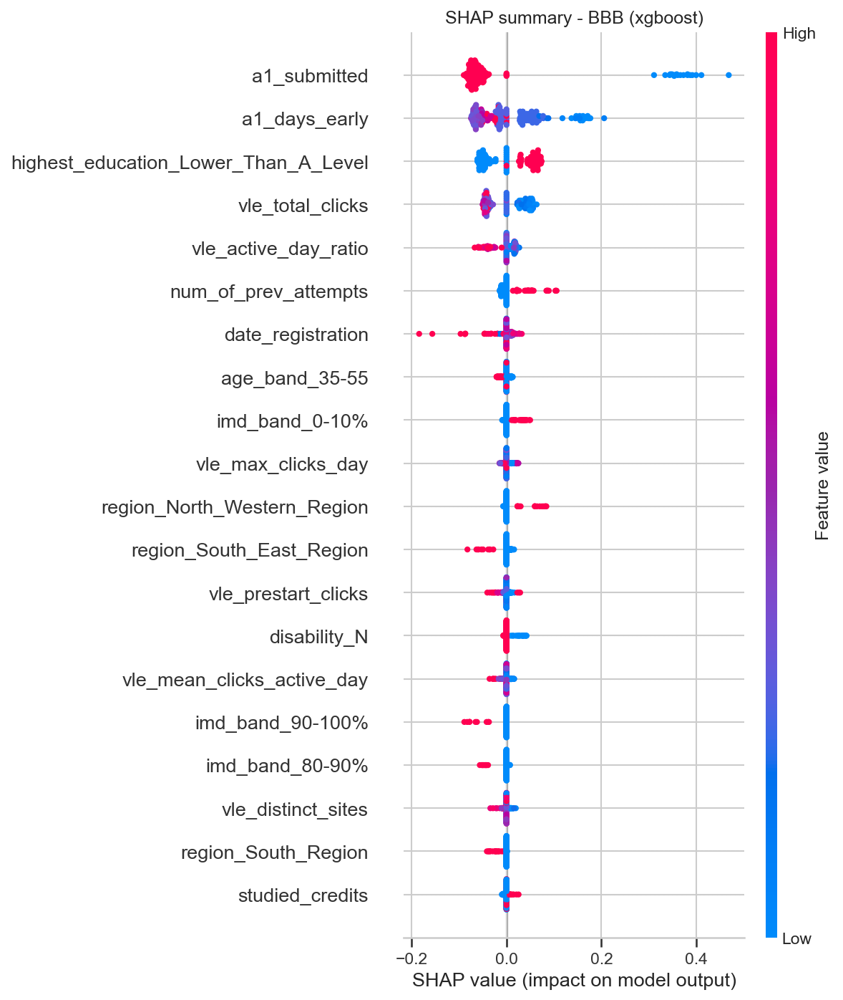

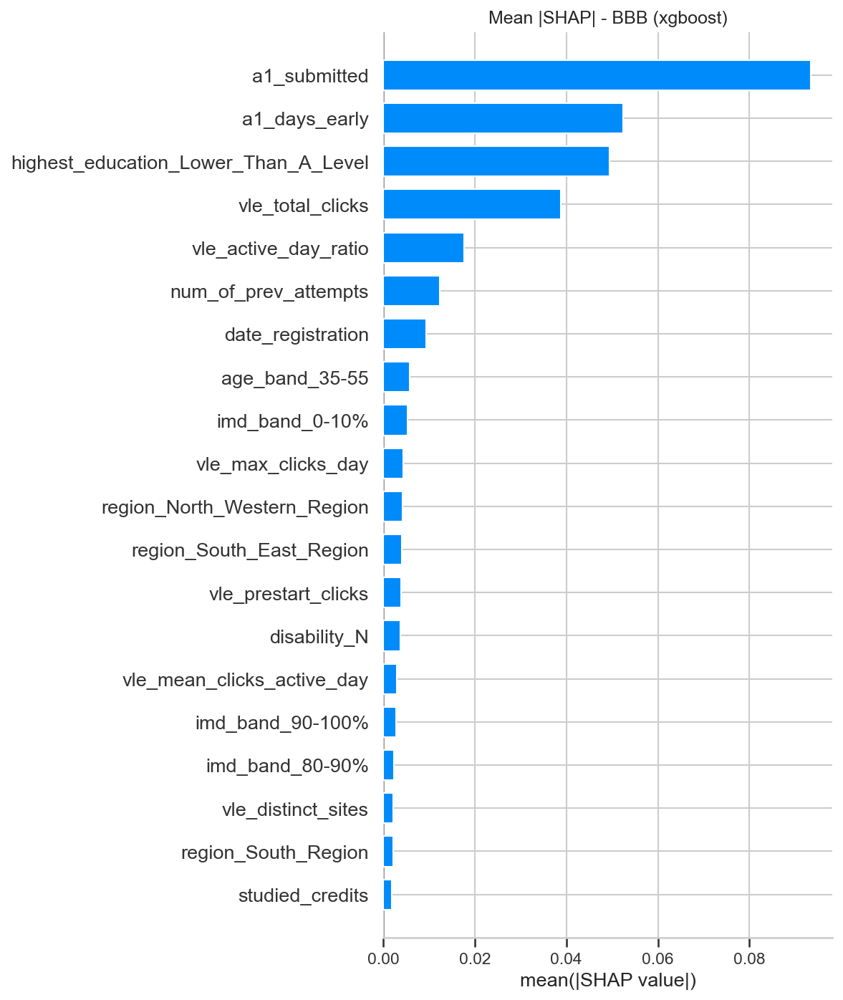

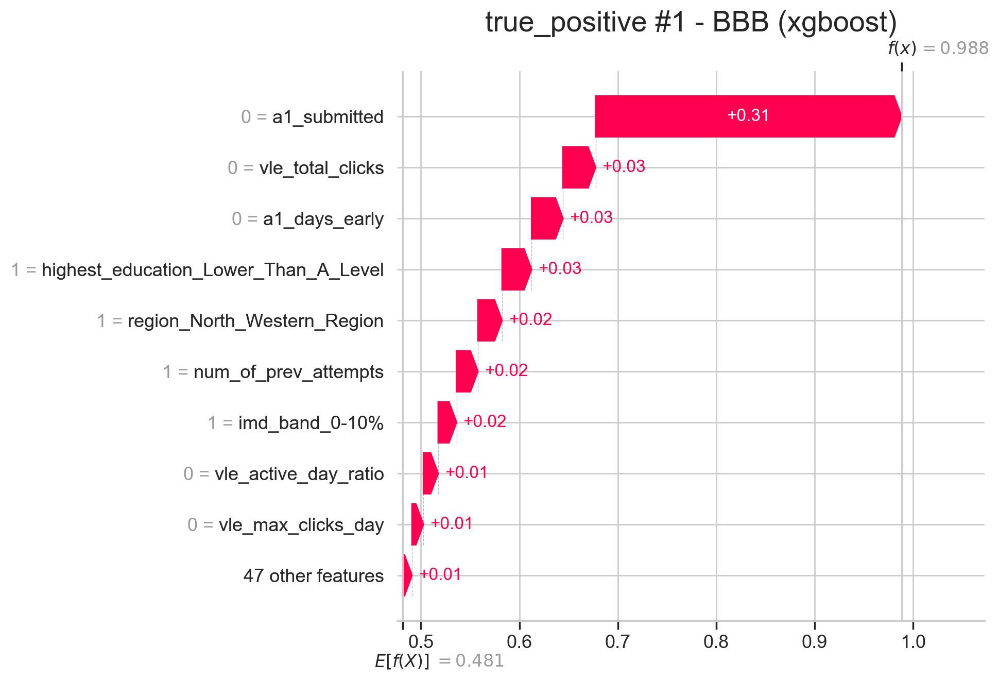

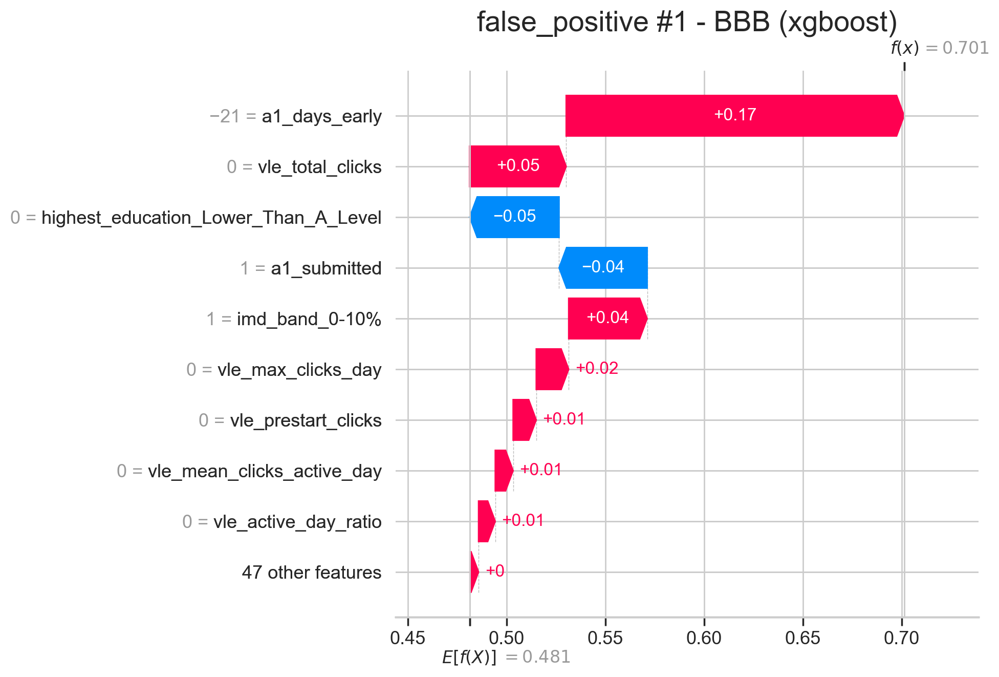

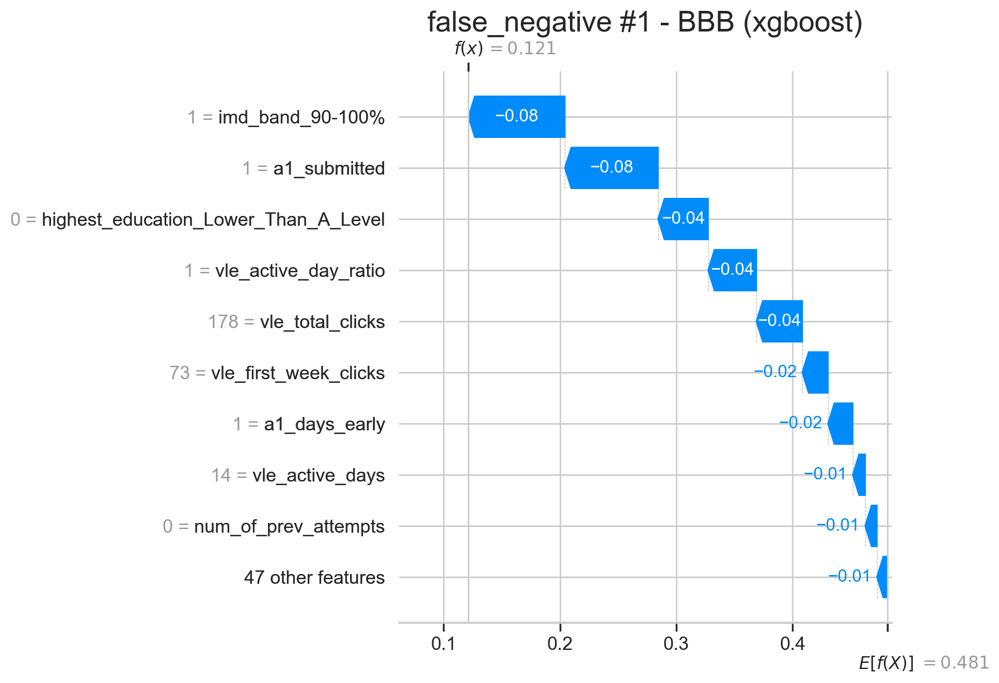

21:09:30 | INFO    | ======================================================================
21:09:30 | INFO    | PHASE 4 | SHAP explainability - DDD (xgboost)
21:09:30 | INFO    | ======================================================================
21:09:30 | WARNING | TreeExplainer unavailable for xgboost (could not convert string to float: '[5E-1]'); falling back to a sampled model-agnostic explainer. 


  0%|          | 0/200 [00:00<?, ?it/s]

21:10:26 | INFO    | Computed SHAP values: (200, 56)
21:10:27 | INFO    | Top global features:
                             feature  mean_abs_shap
                        a1_submitted       0.109048
                       a1_days_early       0.055997
highest_education_Lower_Than_A_Level       0.048574
                  vle_distinct_sites       0.028497
                vle_active_day_ratio       0.027176
                     vle_active_days       0.018466
                    vle_total_clicks       0.016355
                num_of_prev_attempts       0.009726
                     studied_credits       0.009322
           vle_days_since_last_login       0.004283
21:10:37 | INFO    | Per-student waterfall plots saved for TP/FP/FN cases.


### Course DDD — SHAP (best model: `xgboost`)

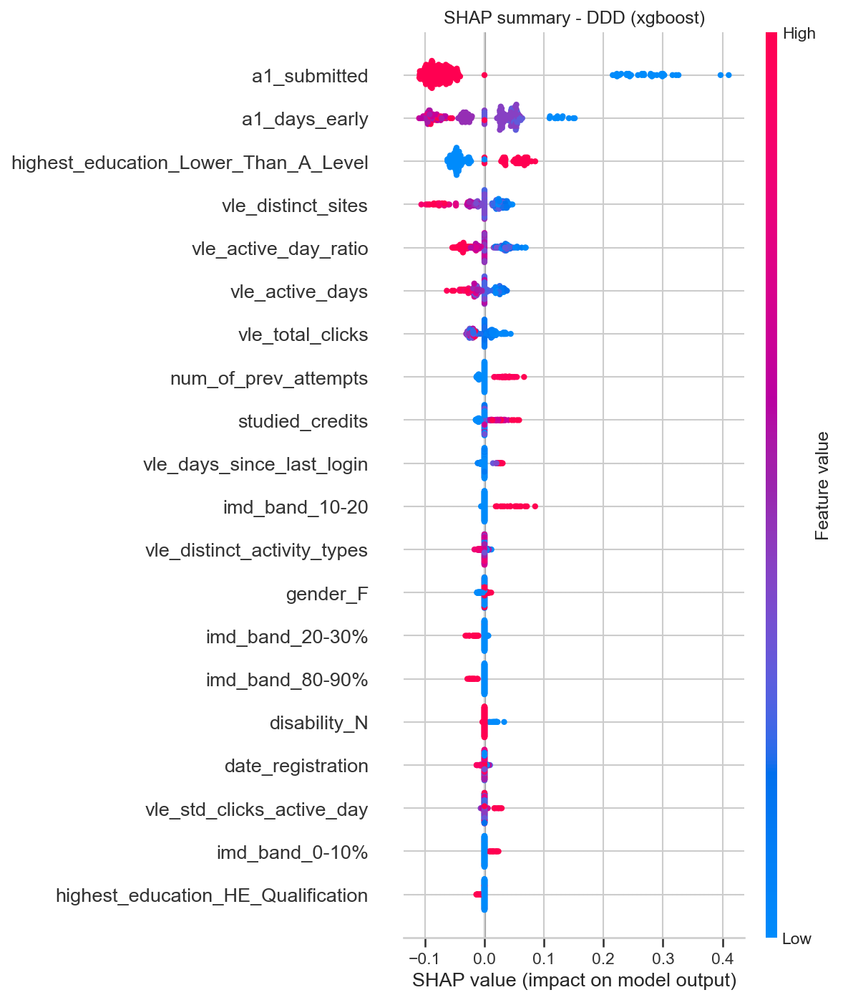

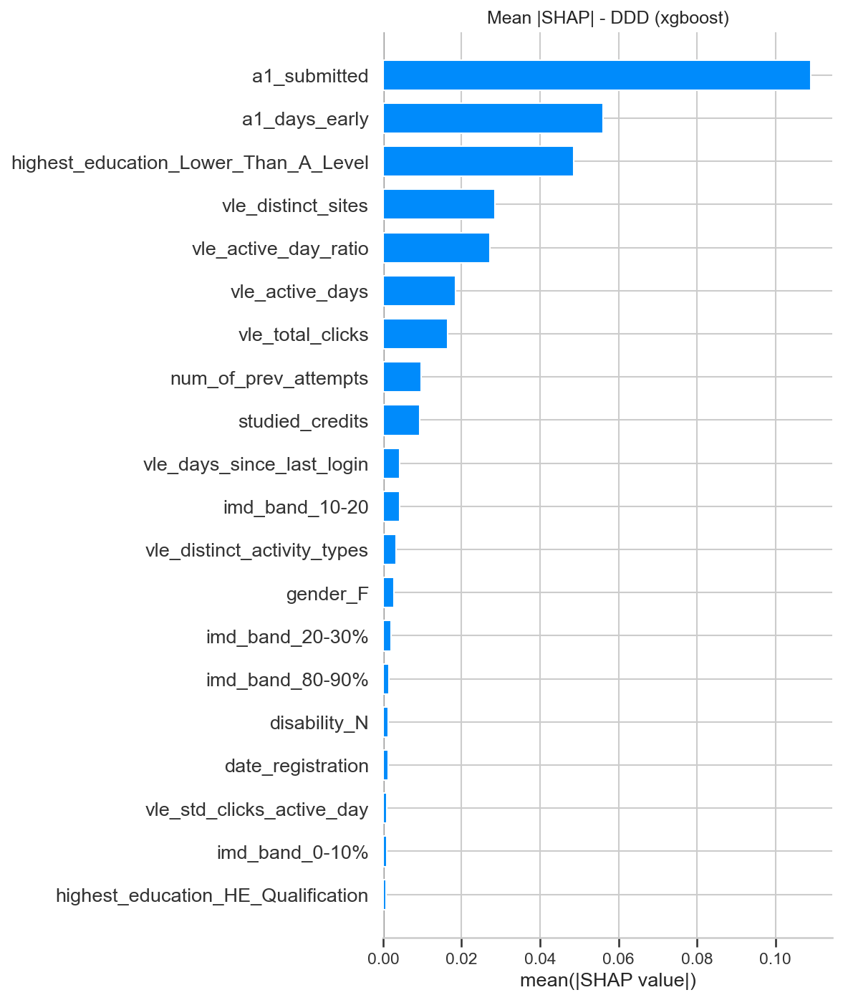

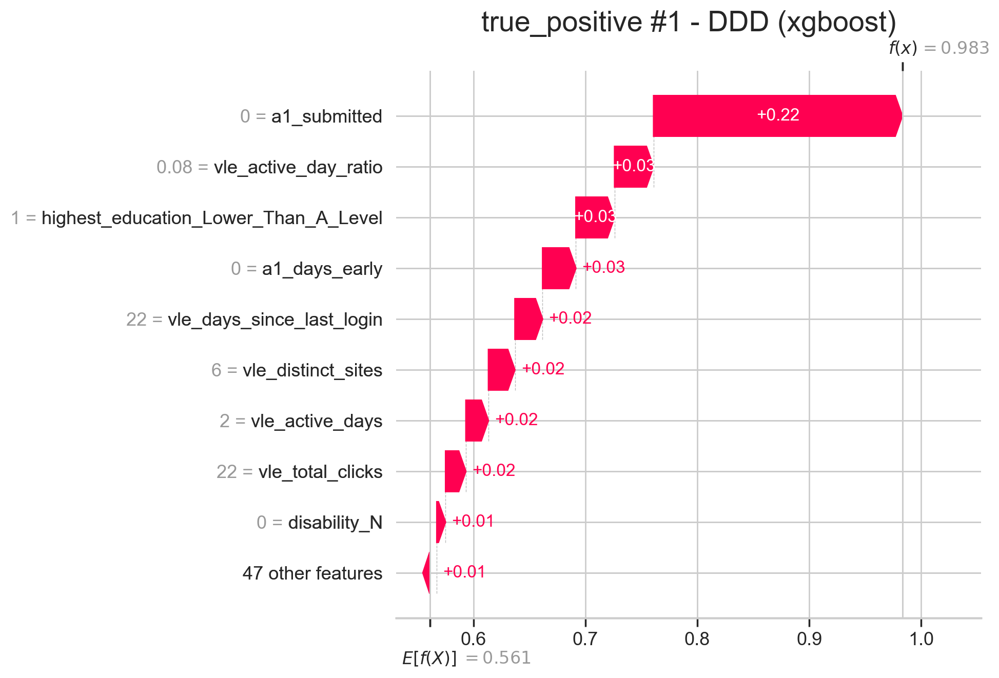

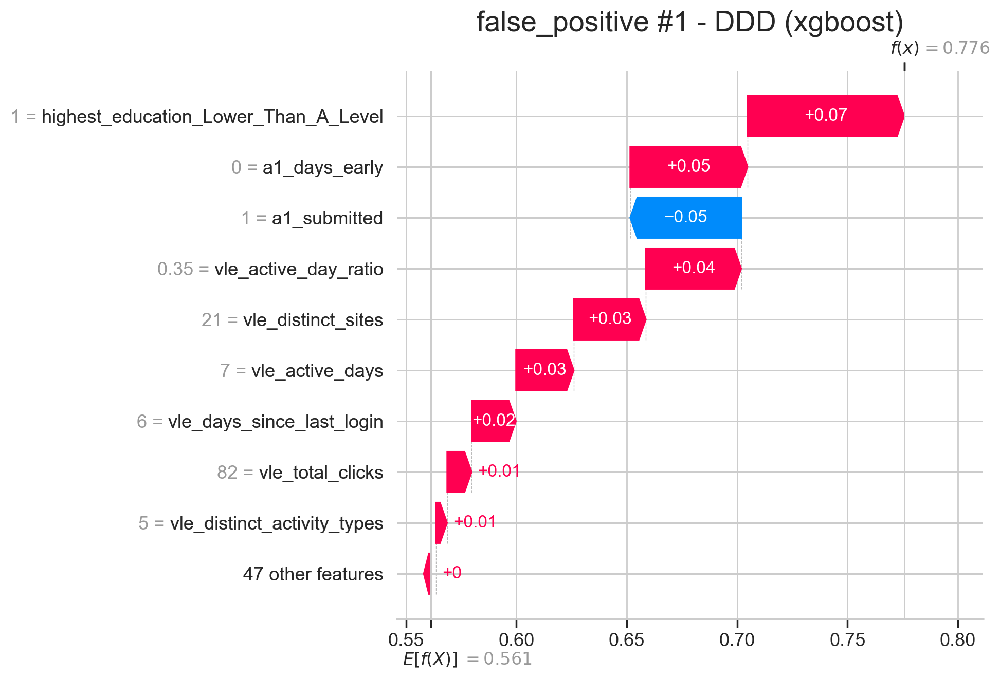

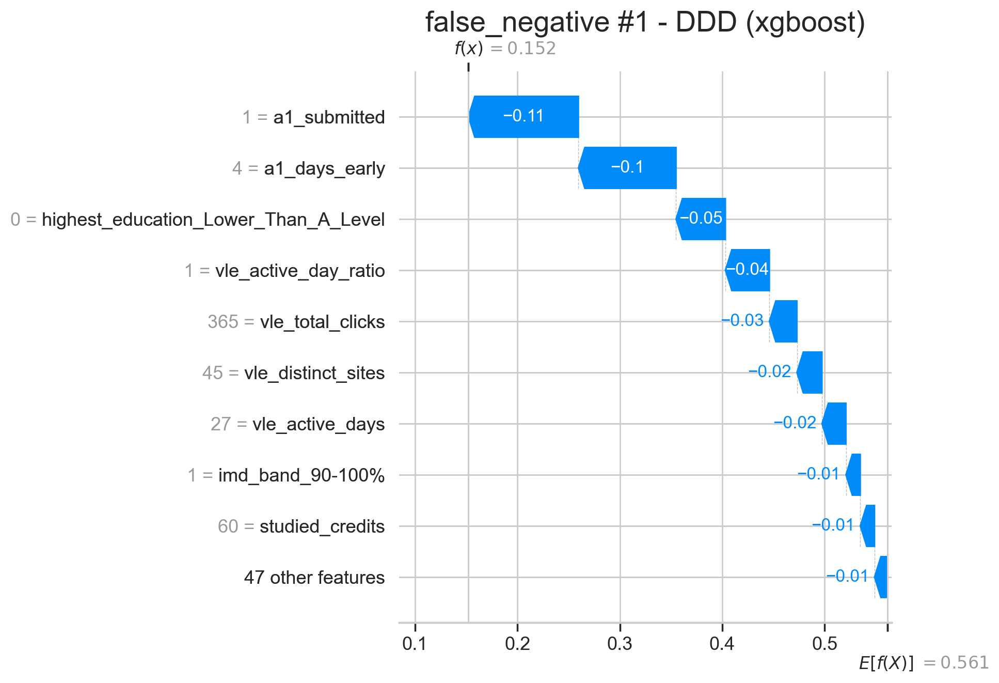

21:10:38 | INFO    | ======================================================================
21:10:38 | INFO    | PHASE 4 | SHAP explainability - EEE (xgboost)
21:10:38 | INFO    | ======================================================================
21:10:38 | WARNING | TreeExplainer unavailable for xgboost (could not convert string to float: '[5E-1]'); falling back to a sampled model-agnostic explainer. 


  0%|          | 0/200 [00:00<?, ?it/s]

21:11:56 | INFO    | Computed SHAP values: (200, 56)
21:11:57 | INFO    | Top global features:
                             feature  mean_abs_shap
                        a1_submitted       0.122093
                       a1_days_early       0.063764
                     vle_active_days       0.038004
highest_education_Lower_Than_A_Level       0.025560
         vle_distinct_activity_types       0.014660
                      age_band_35-55       0.010591
                  vle_max_clicks_day       0.008708
               vle_first_week_clicks       0.008142
            vle_max_consecutive_days       0.006130
                    vle_total_clicks       0.005660
21:12:07 | INFO    | Per-student waterfall plots saved for TP/FP/FN cases.


### Course EEE — SHAP (best model: `xgboost`)

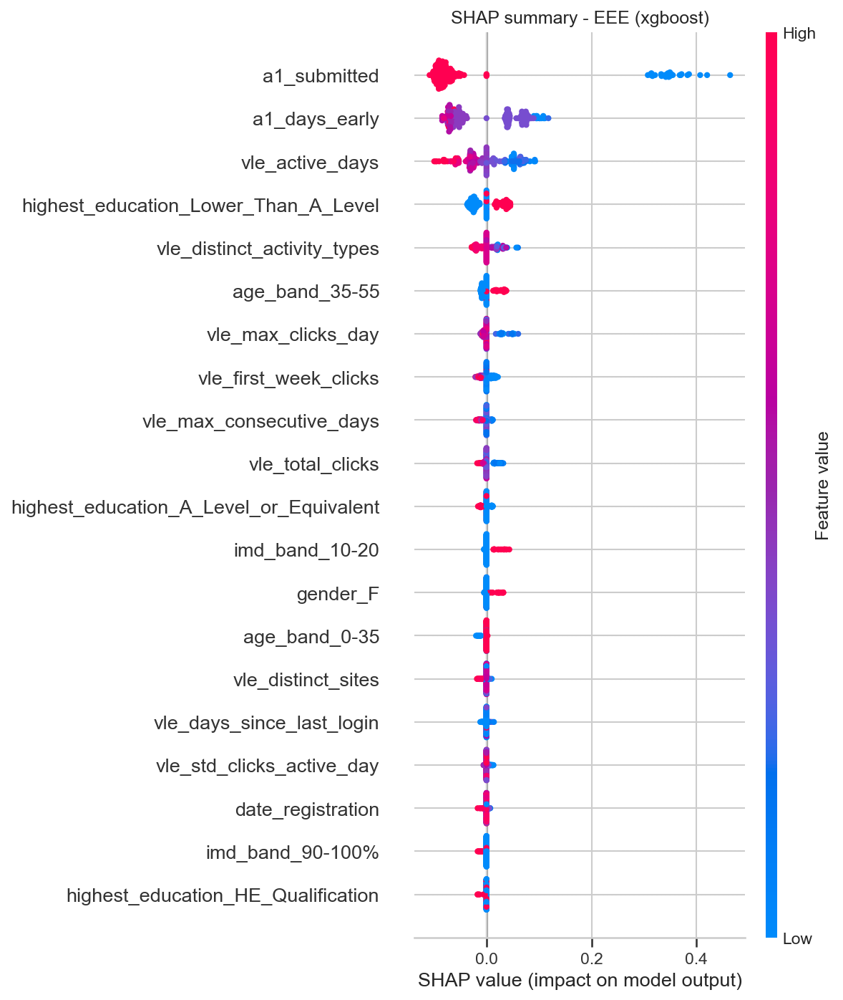

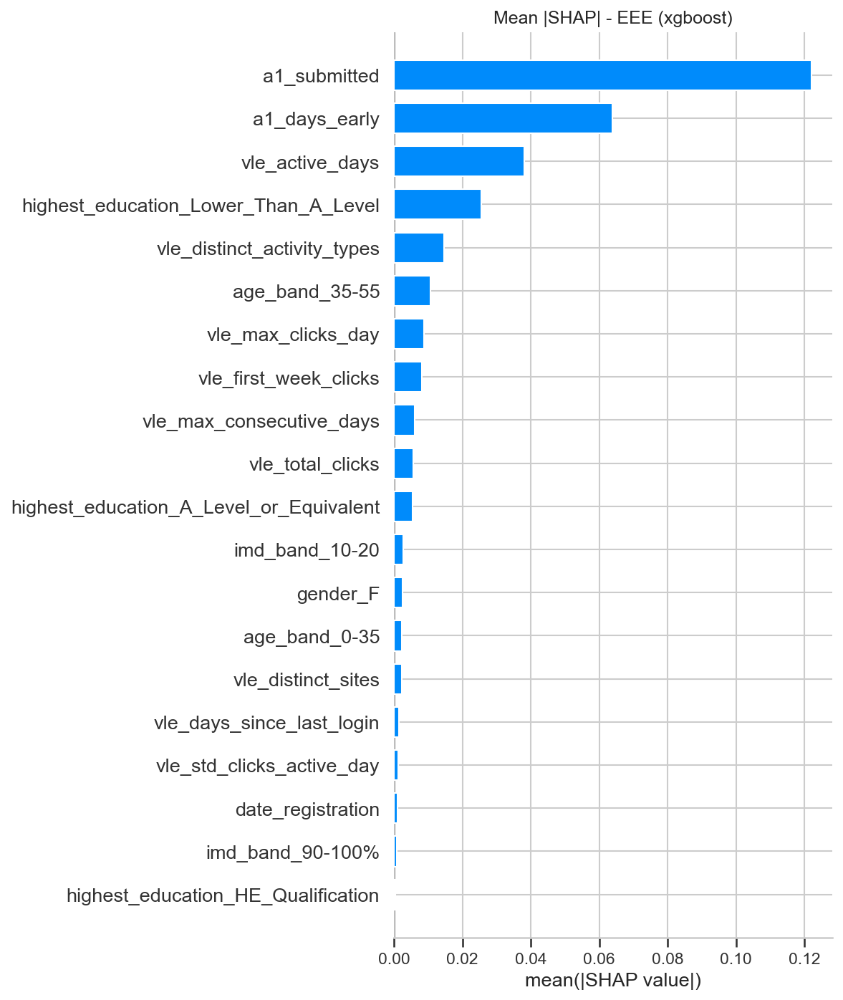

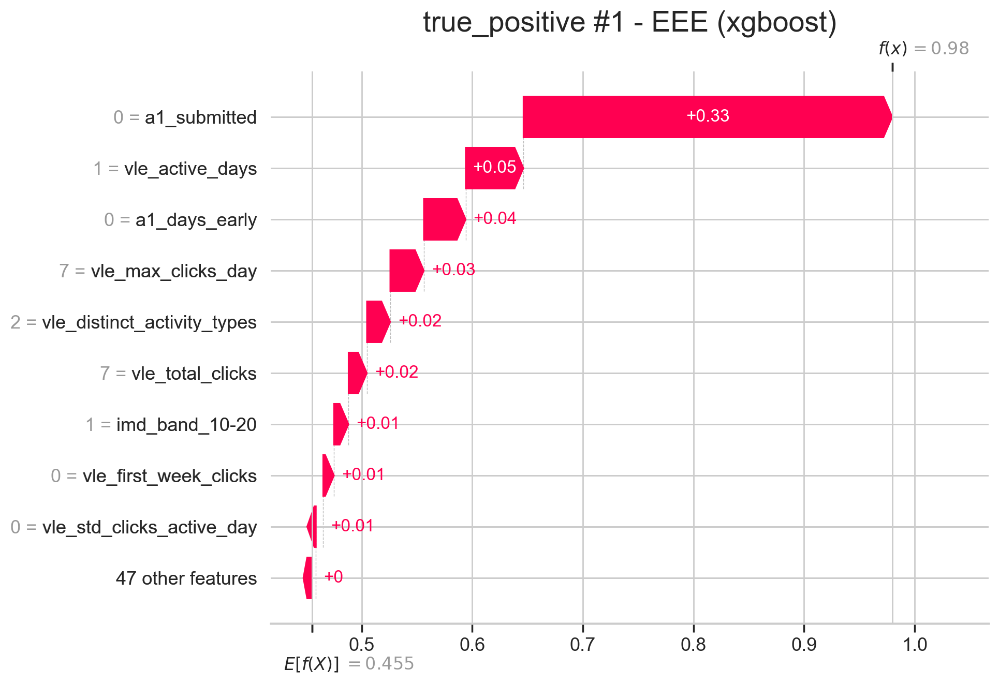

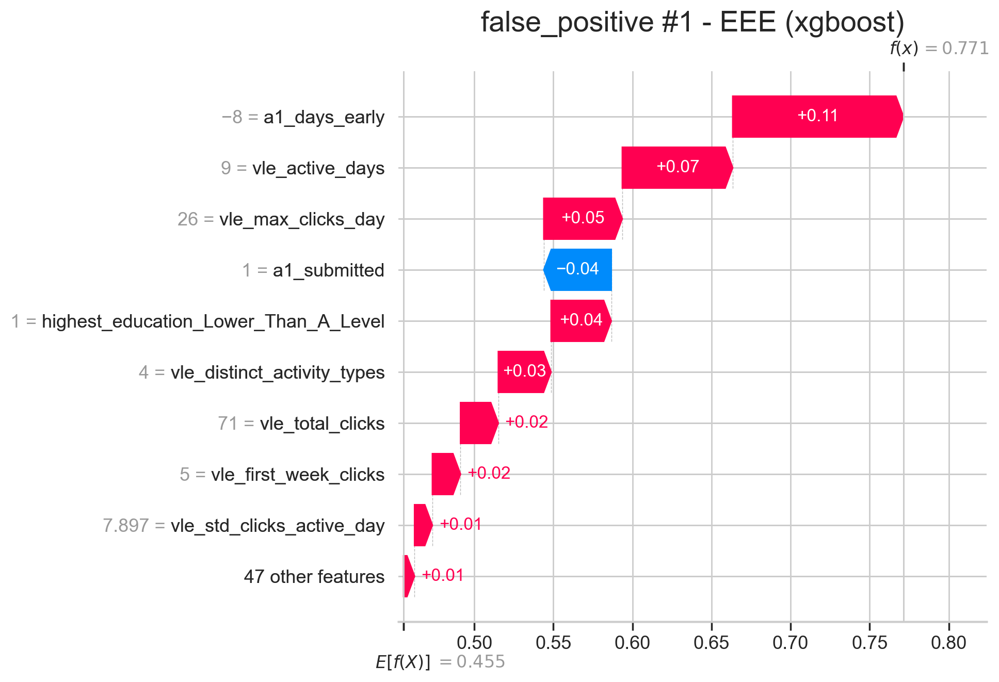

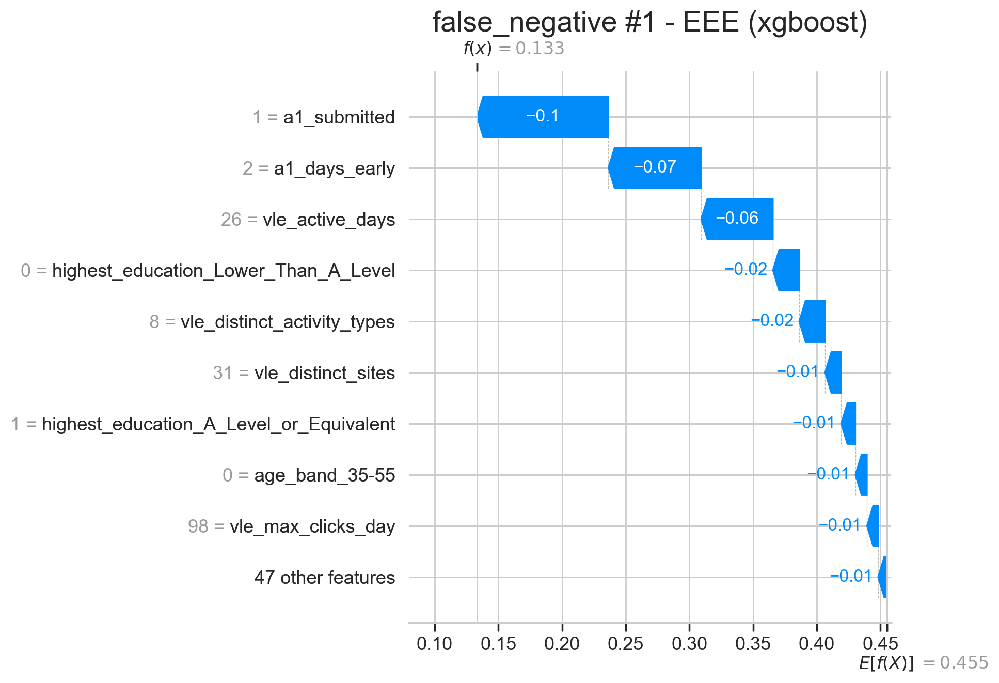

21:12:07 | INFO    | ======================================================================
21:12:07 | INFO    | PHASE 4 | SHAP explainability - FFF (xgboost)
21:12:07 | INFO    | ======================================================================
21:12:07 | WARNING | TreeExplainer unavailable for xgboost (could not convert string to float: '[5E-1]'); falling back to a sampled model-agnostic explainer. 


  0%|          | 0/200 [00:00<?, ?it/s]

21:13:02 | INFO    | Computed SHAP values: (200, 56)
21:13:03 | INFO    | Top global features:
                             feature  mean_abs_shap
                        a1_submitted       0.065787
highest_education_Lower_Than_A_Level       0.043440
                       a1_days_early       0.042027
                    vle_total_clicks       0.036872
                  vle_distinct_sites       0.028163
                     vle_active_days       0.019282
                vle_active_day_ratio       0.014833
                      imd_band_0-10%       0.009273
            vle_max_consecutive_days       0.004722
         vle_distinct_activity_types       0.004304
21:13:13 | INFO    | Per-student waterfall plots saved for TP/FP/FN cases.


### Course FFF — SHAP (best model: `xgboost`)

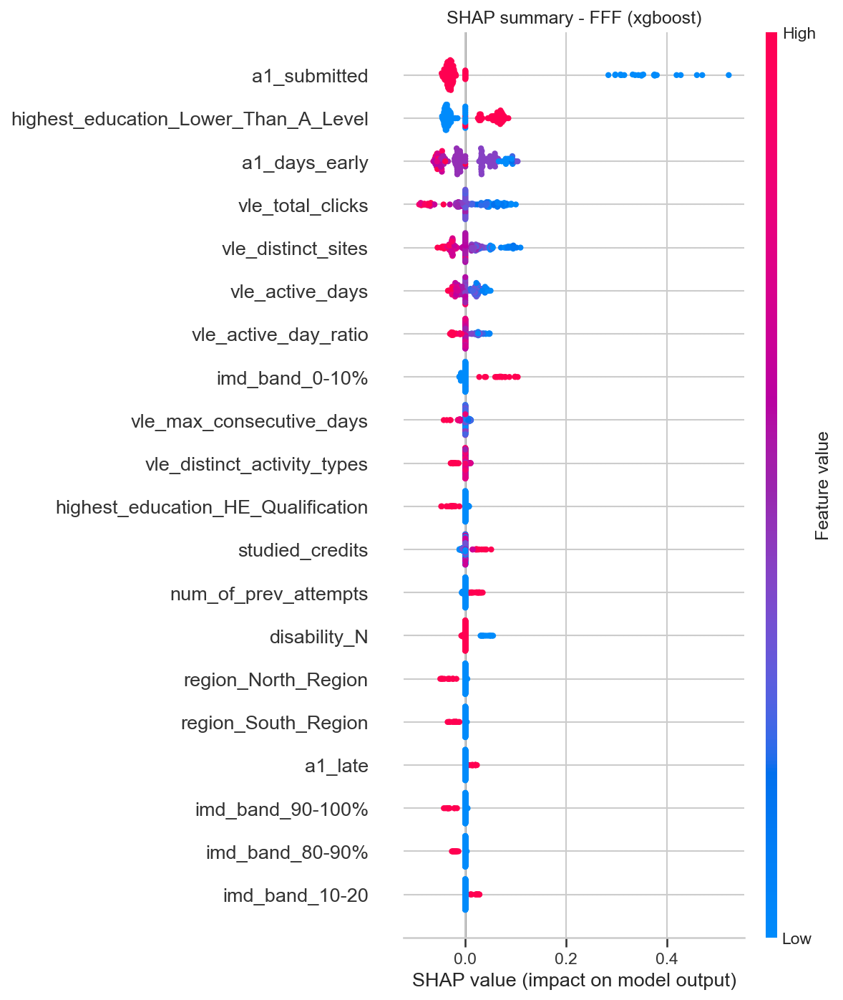

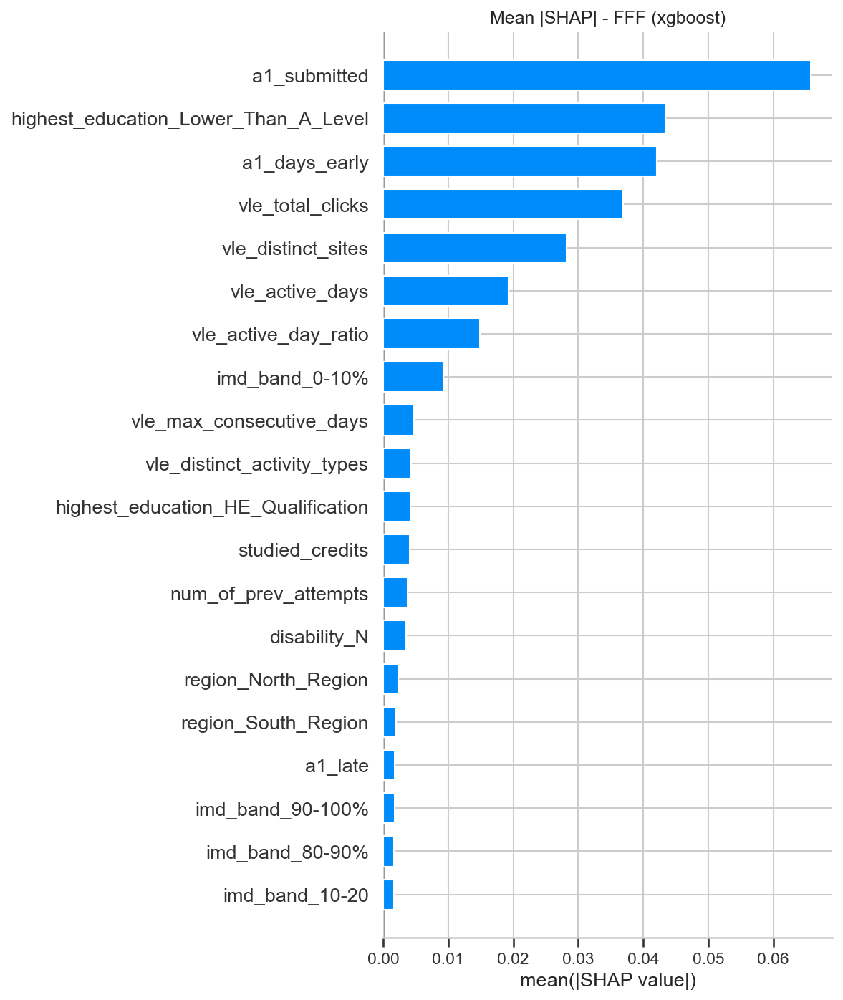

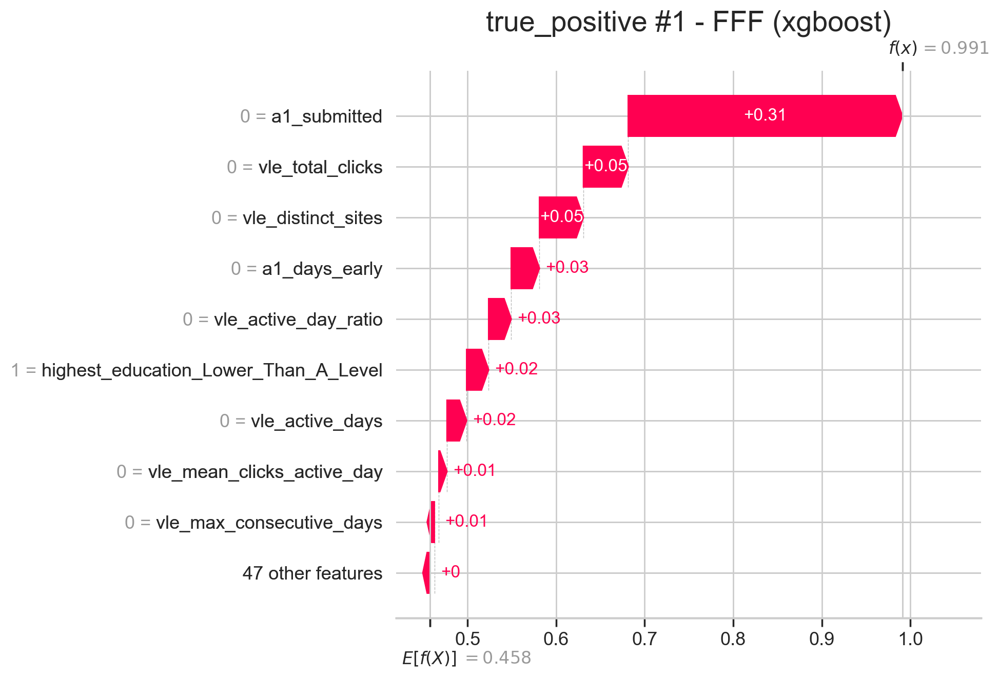

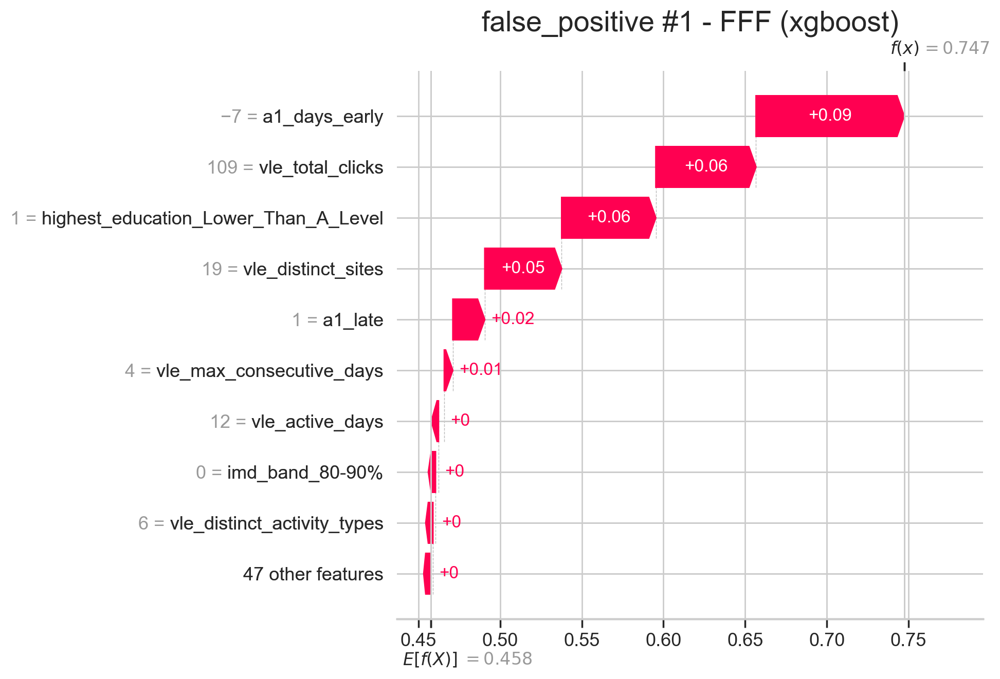

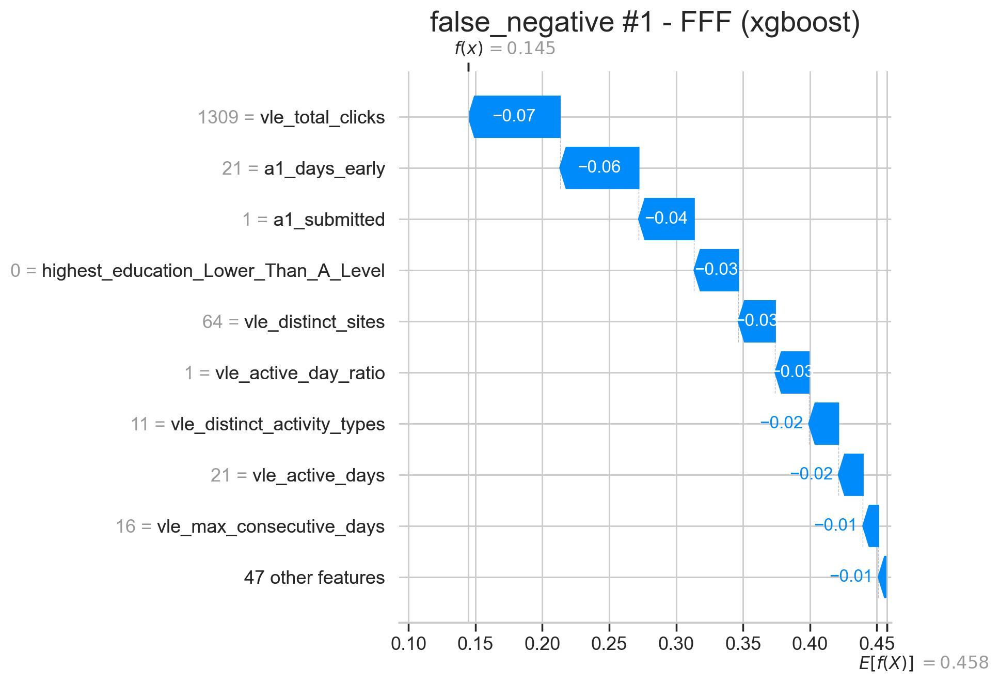

In [19]:
# Generate and display SHAP explanations for the best-performing model of
# each course, storing feature rankings and logging any errors encountered.
shap_rankings: Dict[str, pd.DataFrame] = {}

if RUN_SHAP:
    for course in all_results:
        best = summary[course]["best_model"]
        try:
            ranking = explain_best_model(course, all_results[course], best)
            shap_rankings[course] = ranking
            display(Markdown(f"### Course {course} — SHAP (best model: `{best}`)"))
            show_images([
                config.SHAP_DIR / f"shap_summary_{course}_{best}.png",
                config.SHAP_DIR / f"shap_bar_{course}_{best}.png",
                config.SHAP_DIR / f"shap_waterfall_{course}_{best}_true_positive_1.png",
                config.SHAP_DIR / f"shap_waterfall_{course}_{best}_false_positive_1.png",
                config.SHAP_DIR / f"shap_waterfall_{course}_{best}_false_negative_1.png",
            ])
        except Exception as exc:
            logger.warning("SHAP failed for %s: %s", course, exc)
else:
    logger.info("RUN_SHAP = False — skipping SHAP.")

## §10 · Cross-course generalisation  *(Phase 5)*

Three analyses: a model×course PR-AUC heatmap, a **train-on-one / test-on-the-
rest** transfer matrix for XGBoost (strong off-diagonal values indicate
generalisable disengagement signals), and a check of whether the top SHAP
features recur across courses.

In [20]:
def summarise_within_course(all_results: Dict[str, Dict[str, dict]]) -> pd.DataFrame:
    """Combine per-course metrics and draw a model x course PR-AUC heatmap."""
    banner(logger, "Cross-course | within-course comparison")
    rows = []
    for course, results in all_results.items():
        for model, r in results.items():
            m = r["metrics"]
            rows.append({"course": course, "model": model,
                         "pr_auc": m["pr_auc"], "roc_auc": m["roc_auc"],
                         "f1": m["f1"], "strategy": r["strategy"]})
    tab = pd.DataFrame(rows)
    tab.to_csv(config.TABLE_DIR / "metrics_all_courses.csv", index=False)

    pivot = tab.pivot(index="model", columns="course", values="pr_auc")
    fig, ax = plt.subplots(
        figsize=(1.1 * len(pivot.columns) + 2.6, 0.9 * len(pivot.index) + 2.6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", ax=ax,
                annot_kws={"size": 19}, cbar_kws={"shrink": 0.8},
                linewidths=0.5, linecolor="white")
    ax.set_title("PR-AUC by model and course", fontsize=17, pad=8)
    ax.set_xlabel("course", fontsize=16)
    ax.set_ylabel("model", fontsize=16)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=16)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=16)
    ax.collections[0].colorbar.ax.tick_params(labelsize=13)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "cross_course_pr_auc_heatmap.png", dpi=200)
    plt.close(fig)
    logger.info("Within-course PR-AUC:\n%s", pivot.round(3).to_string())
    return tab


def transfer_matrix(course_frames: Dict[str, pd.DataFrame],
                    feature_cols: Dict[str, list],
                    model_name: str = "xgboost") -> pd.DataFrame:
    """Train on one course, evaluate on every course (PR-AUC matrix)."""
    banner(logger, f"Cross-course | transfer matrix ({model_name})")
    categorical = feature_cols["categorical"]
    numeric = feature_cols["numeric"]
    feat_all = categorical + numeric
    courses = list(course_frames.keys())

    fitted = {}
    for src in courses:
        df = course_frames[src]
        X, y = df[feat_all], df["target"].astype(int).to_numpy()
        scale = model_name not in SCALE_FREE_MODELS
        pre = build_preprocessor(categorical, numeric, scale=scale)
        clf = get_classifier(model_name, class_weight="balanced")
        if model_name == "xgboost":
            clf.set_params(scale_pos_weight=xgb_scale_pos_weight(y))
        pipe = ImbPipeline([("pre", pre),
                            ("smote", SMOTE(random_state=config.RANDOM_STATE)),
                            ("classifier", clf)])
        pipe.fit(X, y)
        fitted[src] = pipe

    mat = pd.DataFrame(index=courses, columns=courses, dtype=float)
    for src in courses:
        for tgt in courses:
            df = course_frames[tgt]
            X, y = df[feat_all], df["target"].astype(int).to_numpy()
            proba = fitted[src].predict_proba(X)[:, 1]
            mat.loc[src, tgt] = compute_metrics(y, proba)["pr_auc"]

    mat = mat.astype(float)
    mat.to_csv(config.TABLE_DIR / f"transfer_pr_auc_{model_name}.csv")
    fig, ax = plt.subplots(
        figsize=(1.1 * len(courses) + 2.6, 0.9 * len(courses) + 2.6))
    sns.heatmap(mat, annot=True, fmt=".3f", cmap="magma", ax=ax,
                annot_kws={"size": 19}, cbar_kws={"shrink": 0.8},
                linewidths=0.5, linecolor="white")
    ax.set_xlabel("Tested on", fontsize=16)
    ax.set_ylabel("Trained on", fontsize=16)
    ax.set_title(f"Cross-course transfer PR-AUC ({model_name})", fontsize=17,
                 pad=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=16)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=16)
    ax.collections[0].colorbar.ax.tick_params(labelsize=13)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / f"cross_course_transfer_{model_name}.png",
                dpi=200)
    plt.close(fig)
    logger.info("Transfer PR-AUC matrix:\n%s", mat.round(3).to_string())
    return mat


def shap_consistency(shap_rankings: Dict[str, pd.DataFrame],
                     top_k: int = 10) -> pd.DataFrame:
    """Compare which features rank in the top-k across courses."""
    if not shap_rankings:
        return pd.DataFrame()
    banner(logger, "Cross-course | SHAP feature consistency")
    records = []
    for course, ranking in shap_rankings.items():
        for rank, feat in enumerate(ranking["feature"].head(top_k), 1):
            records.append({"course": course, "feature": feat, "rank": rank})
    long = pd.DataFrame(records)
    counts = (long.groupby("feature")["course"].nunique()
              .sort_values(ascending=False)
              .rename("n_courses_in_topk"))
    counts.to_csv(config.TABLE_DIR / "shap_feature_consistency.csv")
    logger.info("Features appearing in top-%d across courses:\n%s",
                top_k, counts.to_string())
    return counts.reset_index()

21:13:13 | INFO    | ======================================================================
21:13:13 | INFO    | Cross-course | within-course comparison
21:13:13 | INFO    | ======================================================================
21:13:15 | INFO    | Within-course PR-AUC:
course           BBB    DDD    EEE    FFF
model                                    
logreg         0.805  0.844  0.829  0.817
mlp            0.807  0.829  0.825  0.816
random_forest  0.804  0.840  0.826  0.808
xgboost        0.815  0.845  0.835  0.821


### All courses — held-out metrics (every model)

,course,model,pr_auc,roc_auc,f1,strategy
0,BBB,logreg,0.8047,0.7847,0.6574,class_weight
1,BBB,random_forest,0.8043,0.7887,0.6554,smote
2,BBB,xgboost,0.8147,0.7966,0.6867,class_weight
3,BBB,mlp,0.8075,0.7898,0.6599,class_weight
4,DDD,logreg,0.8444,0.8100,0.7263,class_weight
5,DDD,random_forest,0.8405,0.7995,0.7197,smote
6,DDD,xgboost,0.8450,0.8098,0.7299,smote
7,DDD,mlp,0.8292,0.7907,0.7335,none
8,EEE,logreg,0.8286,0.8442,0.6946,class_weight
9,EEE,random_forest,0.8265,0.8380,0.7026,class_weight


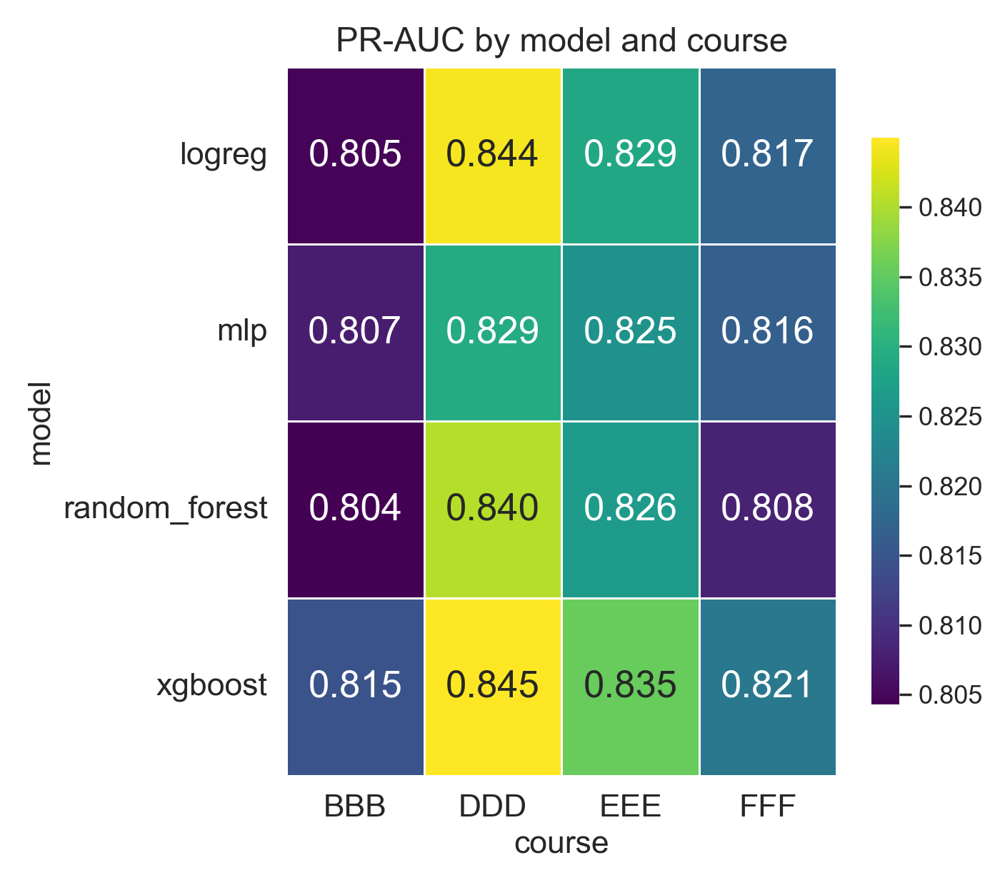

21:13:15 | INFO    | ======================================================================
21:13:15 | INFO    | Cross-course | transfer matrix (xgboost)
21:13:15 | INFO    | ======================================================================
21:13:20 | INFO    | Transfer PR-AUC matrix:
       BBB    DDD    EEE    FFF
BBB  0.986  0.816  0.808  0.794
DDD  0.777  0.995  0.812  0.800
EEE  0.767  0.826  1.000  0.798
FFF  0.785  0.831  0.810  0.990


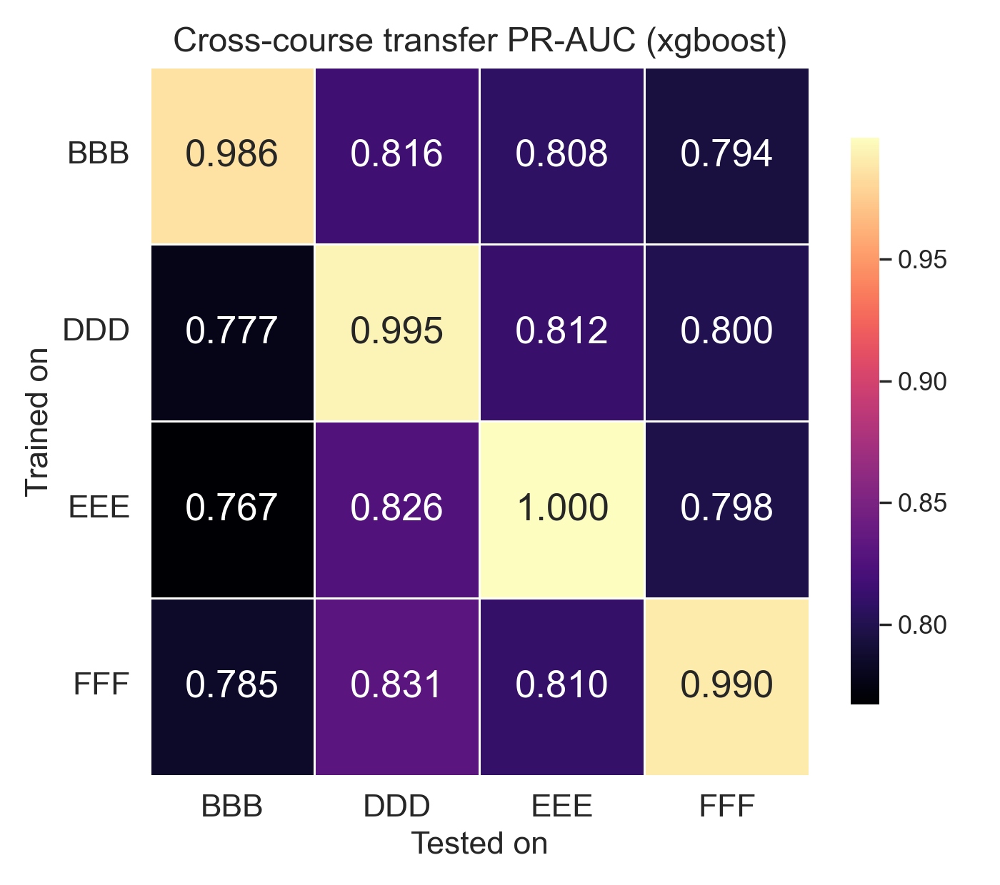

21:13:20 | INFO    | ======================================================================
21:13:20 | INFO    | Cross-course | SHAP feature consistency
21:13:20 | INFO    | ======================================================================
21:13:20 | INFO    | Features appearing in top-10 across courses:
feature
a1_days_early                           4
a1_submitted                            4
highest_education_Lower_Than_A_Level    4
vle_total_clicks                        4
vle_active_day_ratio                    3
vle_active_days                         3
imd_band_0-10%                          2
num_of_prev_attempts                    2
age_band_35-55                          2
vle_max_consecutive_days                2
vle_max_clicks_day                      2
vle_distinct_sites                      2
vle_distinct_activity_types             2
studied_credits                         1
date_registration                       1
vle_days_since_last_login               1
vle_first

,feature,n_courses_in_topk
0,a1_days_early,4
1,a1_submitted,4
2,highest_education_Lower_Than_A_Level,4
3,vle_total_clicks,4
4,vle_active_day_ratio,3
5,vle_active_days,3
6,imd_band_0-10%,2
7,num_of_prev_attempts,2
8,age_band_35-55,2
9,vle_max_consecutive_days,2


In [21]:
if len(all_results) > 1:
    # summarise_within_course() returns the consolidated table it writes to
    # tables/metrics_all_courses.csv -- every model on every course in one
    # place. Shown here in the same form as the per-course tables in section 8,
    # with the heatmap below it as the visual summary of its pr_auc column.
    all_metrics = summarise_within_course(all_results)
    display(Markdown("### All courses — held-out metrics (every model)"))
    display(all_metrics.round(4))
    show_images([config.FIGURE_DIR / "cross_course_pr_auc_heatmap.png"])

    if config.RUN_CROSS_COURSE_TRANSFER and RUN_TRANSFER:
        transfer_matrix(course_frames, feature_cols, model_name="xgboost")
        show_images([config.FIGURE_DIR / "cross_course_transfer_xgboost.png"])

    if shap_rankings:
        consistency = shap_consistency(shap_rankings)
        display(consistency)
else:
    logger.info("Only one course selected — cross-course analysis needs >= 2. "
                "Add courses to COURSES in §2 to enable it.")

## §11 · Summary  *(Phase 5)*

Persist a consolidated run summary and print the best model per course.

In [22]:
# Save the pipeline summary, log completion details, and create a DataFrame
# summarising the best-performing model and PR-AUC for each course.
save_json(summary, config.OUTPUT_DIR / "run_summary.json")
banner(logger, "Pipeline complete")
for course, s in summary.items():
    logger.info("%s | best=%s | PR-AUC=%.4f",
                course, s["best_model"], s["best_pr_auc"])
logger.info("All artefacts written under %s", config.OUTPUT_DIR)

pd.DataFrame([
    {"course": c, "best_model": s["best_model"],
     "best_pr_auc": round(s["best_pr_auc"], 4)}
    for c, s in summary.items()
])

21:13:20 | INFO    | ======================================================================
21:13:20 | INFO    | Pipeline complete
21:13:20 | INFO    | ======================================================================
21:13:20 | INFO    | BBB | best=xgboost | PR-AUC=0.8147
21:13:20 | INFO    | DDD | best=xgboost | PR-AUC=0.8450
21:13:20 | INFO    | EEE | best=xgboost | PR-AUC=0.8355
21:13:20 | INFO    | FFF | best=xgboost | PR-AUC=0.8206
21:13:20 | INFO    | All artefacts written under C:\Users\twuma\OneDrive - hull.ac.uk\Research\Research Project\Final Code (A1_score excluded)\outputs


,course,best_model,best_pr_auc
0,BBB,xgboost,0.8147
1,DDD,xgboost,0.8450
2,EEE,xgboost,0.8355
3,FFF,xgboost,0.8206


## §12 · Combined report figures

The pipeline above renders every individual panel. This section leaves all of
them in place but **stitches related panels into single composite figures**. Nothing is discarded. The panels are combined, labelled
`(a)`, `(b)`, `(c)` …, and written to `outputs/report_figures/`.

The resulting output consists of nine main figures: four global EDA figures covering the dataset overview, demographics, feature distributions, and correlations; four course-specific figures covering evaluation curves, confusion-matrix analysis, global SHAP explanations, and local SHAP explanations; and one cross-course comparison figure.

In [23]:
REPORT_DIR = config.OUTPUT_DIR / "report_figures"


def combine_images(paths, out_path, ncols=2, panel_letters=True,
                   suptitle=None, dpi=200, col_width=6.5):
    """Tile existing image files into one composite figure.

    Missing paths are skipped; returns ``out_path`` if at least one image was
    written, else ``None``. Panels keep their own aspect ratio (no distortion);
    the figure is sized to each row's tallest panel so there is little wasted
    whitespace and every panel is as large as possible. Panels are labelled
    (a), (b), (c) ... for easy reference.
    """
    paths = [Path(p) for p in paths if Path(p).exists()]
    if not paths:
        return None

    n = len(paths)
    ncols = max(1, min(ncols, n))
    nrows = math.ceil(n / ncols)
    imgs = [plt.imread(str(p)) for p in paths]

    # Row heights follow the tallest image aspect in each row (h/w * col_width).
    row_heights = []
    for r in range(nrows):
        row = imgs[r * ncols:(r + 1) * ncols]
        row_heights.append(max((im.shape[0] / im.shape[1]) * col_width
                               for im in row))

    fig = plt.figure(figsize=(col_width * ncols, sum(row_heights)))
    gs = fig.add_gridspec(nrows, ncols, height_ratios=row_heights,
                          hspace=0.04, wspace=0.02)

    for i, im in enumerate(imgs):
        r, c = divmod(i, ncols)
        ax = fig.add_subplot(gs[r, c])
        ax.imshow(im)
        if panel_letters and n > 1:
            ax.text(0.008, 0.992, f"({chr(97 + i)})", transform=ax.transAxes,
                    fontsize=15, fontweight="bold", va="top", ha="left",
                    bbox=dict(facecolor="white", edgecolor="none",
                              alpha=0.7, pad=1.5))
        ax.axis("off")

    if suptitle:
        fig.suptitle(suptitle, fontsize=15, fontweight="bold")
        fig.subplots_adjust(top=1 - 0.4 / sum(row_heights))
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    return out_path


def _demographics_figure(out_path, suptitle="Fail rate by demographic group"):
    """Build the demographics figure natively from the per-group CSVs so every
    panel is legible. The three low-cardinality groups share the top row; the
    two wide groups (education, IMD decile) each get a full-width row below.
    """
    import pandas as pd
    from matplotlib.gridspec import GridSpec

    T = config.TABLE_DIR
    specs = [("gender", "gender"), ("age_band", "age band"),
             ("disability", "disability"),
             ("highest_education", "highest education"),
             ("imd_band", "IMD band")]
    data = {}
    for col, _ in specs:
        f = T / f"eda_failrate_by_{col}.csv"
        if f.exists():
            data[col] = pd.read_csv(f, index_col=0)
    if not data:
        return None

    fig = plt.figure(figsize=(15, 9))
    gs = GridSpec(2, 3, figure=fig, height_ratios=[1, 1], hspace=0.55,
                  wspace=0.28)
    # Row 1: three narrow groups; Row 2: education (1 cell) + IMD (2 cells).
    axmap = {
        "gender": fig.add_subplot(gs[0, 0]),
        "age_band": fig.add_subplot(gs[0, 1]),
        "disability": fig.add_subplot(gs[0, 2]),
        "highest_education": fig.add_subplot(gs[1, 0]),
        "imd_band": fig.add_subplot(gs[1, 1:]),
    }
    letters = dict(zip(["gender", "age_band", "disability",
                        "highest_education", "imd_band"], "abcde"))

    import numpy as _np
    import seaborn as _sns
    for col, pretty in specs:
        if col not in data:
            continue
        ax = axmap[col]
        tab = data[col]
        cats = [str(i) for i in tab.index]
        rates = tab["fail_rate"].to_numpy()
        counts = tab["count"].to_numpy()
        colours = _sns.color_palette("mako", len(cats))
        ax.bar(range(len(cats)), rates, color=colours)
        ax.set_ylim(0, 1)
        ax.set_title(f"Fail rate by {pretty}", fontsize=15)
        ax.set_ylabel("Fail rate", fontsize=13)
        ax.tick_params(axis="y", labelsize=12)
        ax.set_xticks(range(len(cats)))
        rot = 30 if (len(cats) > 4 or col == "highest_education") else 0
        ax.set_xticklabels(cats, rotation=rot,
                           ha="right" if rot else "center", fontsize=12)
        for x, rate in enumerate(rates):
            ax.text(x, rate + 0.02, f"{rate:.0%}",
                    ha="center", va="bottom", fontsize=14)
        ax.text(-0.11, 1.14, f"({letters[col]})", transform=ax.transAxes,
                fontsize=15, fontweight="bold", va="bottom", ha="left",
                clip_on=False)

    if suptitle:
        fig.suptitle(suptitle, fontsize=15, fontweight="bold")
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    return out_path


def _copy(src: Path, dst: Path):
    """Copy an already-single figure into the report set unchanged."""
    src, dst = Path(src), Path(dst)
    if src.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy(src, dst)
        return dst
    return None


def build_report_figures(courses, summary, transfer_model="xgboost"):
    """Assemble the composite report figures from the panels on disk.

    ``courses`` is the list of courses that were modelled; ``summary`` is the
    per-course dict produced by training (used to find each course's best model
    for the SHAP figures). Returns the list of report-figure paths written.
    """
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    F, S = config.FIGURE_DIR, config.SHAP_DIR
    made = []

    # ---- Global EDA figures ------------------------------------------------ #
    p = combine_images(
        [F / "eda_class_balance.png", F / "eda_fail_rate_by_course.png"],
        REPORT_DIR / "report_eda_overview.png", ncols=2,
        suptitle="Class balance and fail rate by course")
    if p:
        made.append(p)

    demo_fig = _demographics_figure(
        REPORT_DIR / "report_eda_failrate_by_demographics.png")
    if demo_fig:
        made.append(demo_fig)

    # Already-single EDA figures are copied in unchanged.
    for src_name, dst_name in [
            ("eda_feature_distributions.png",
             "report_eda_feature_distributions.png"),
            ("eda_correlation_heatmap.png",
             "report_eda_correlation_heatmap.png")]:
        d = _copy(F / src_name, REPORT_DIR / dst_name)
        if d:
            made.append(d)

    # ---- Per-course modelling figures -------------------------------------- #
    for course in courses:
        best = summary[course]["best_model"]

        # Evaluation curves already combine PR + ROC — copy unchanged.
        d = _copy(F / f"eval_curves_{course}.png",
                  REPORT_DIR / f"report_eval_curves_{course}.png")
        if d:
            made.append(d)

        # Confusion matrices for every model -> one grid.
        conf = sorted(F.glob(f"eval_confusion_{course}_*.png"))
        p = combine_images(
            conf, REPORT_DIR / f"report_confusion_matrices_{course}.png",
            ncols=2, suptitle=f"Confusion matrices — course {course}")
        if p:
            made.append(p)

        # SHAP global: beeswarm + mean|SHAP| bar for the best model.
        p = combine_images(
            [S / f"shap_summary_{course}_{best}.png",
             S / f"shap_bar_{course}_{best}.png"],
            REPORT_DIR / f"report_shap_global_{course}.png", ncols=2,
            suptitle=f"SHAP global importance — course {course} ({best})")
        if p:
            made.append(p)

        # SHAP local: representative TP / FP / FN waterfalls side by side.
        wf = [S / f"shap_waterfall_{course}_{best}_{case}_1.png"
              for case in ("true_positive", "false_positive",
                           "false_negative")]
        p = combine_images(
            wf, REPORT_DIR / f"report_shap_waterfalls_{course}.png", ncols=3,
            col_width=7.0,
            suptitle=f"SHAP explanations for representative students — "
                     f"course {course}")
        if p:
            made.append(p)

    # ---- Cross-course generalisation --------------------------------------- #
    p = combine_images(
        [F / "cross_course_pr_auc_heatmap.png",
         F / f"cross_course_transfer_{transfer_model}.png"],
        REPORT_DIR / "report_cross_course.png", ncols=2, col_width=6.5,
        suptitle="Cross-course generalisation")
    if p:
        made.append(p)

    logger.info("Report figures written to %s (%d files)", REPORT_DIR,
                len(made))
    return made

21:13:43 | INFO    | Report figures written to C:\Users\twuma\OneDrive - hull.ac.uk\Research\Research Project\Final Code (A1_score excluded)\outputs\report_figures (21 files)
21:13:43 | INFO    | Combined report figures written to C:\Users\twuma\OneDrive - hull.ac.uk\Research\Research Project\Final Code (A1_score excluded)\outputs\report_figures


**report_eda_overview.png**

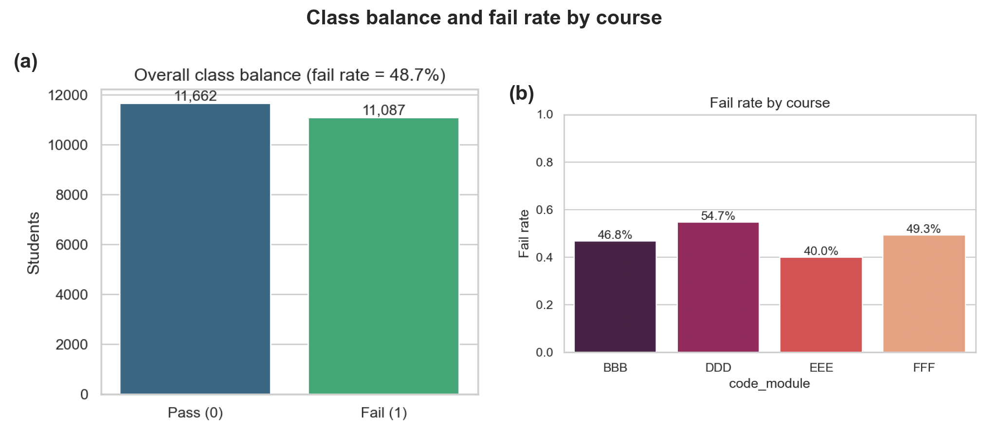

**report_eda_failrate_by_demographics.png**

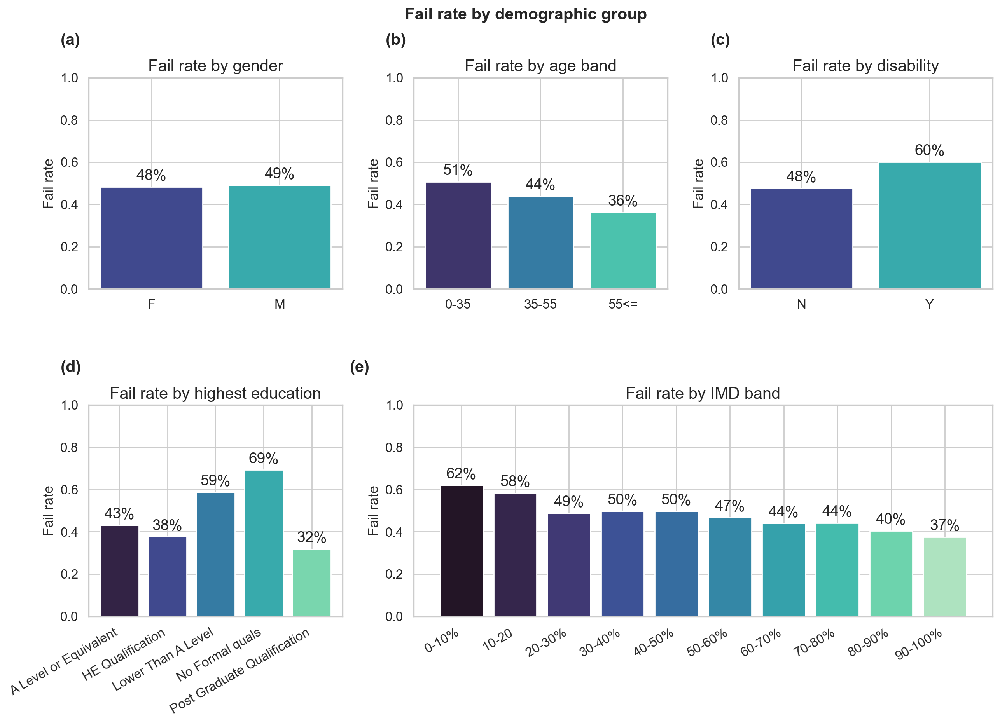

**report_eda_feature_distributions.png**

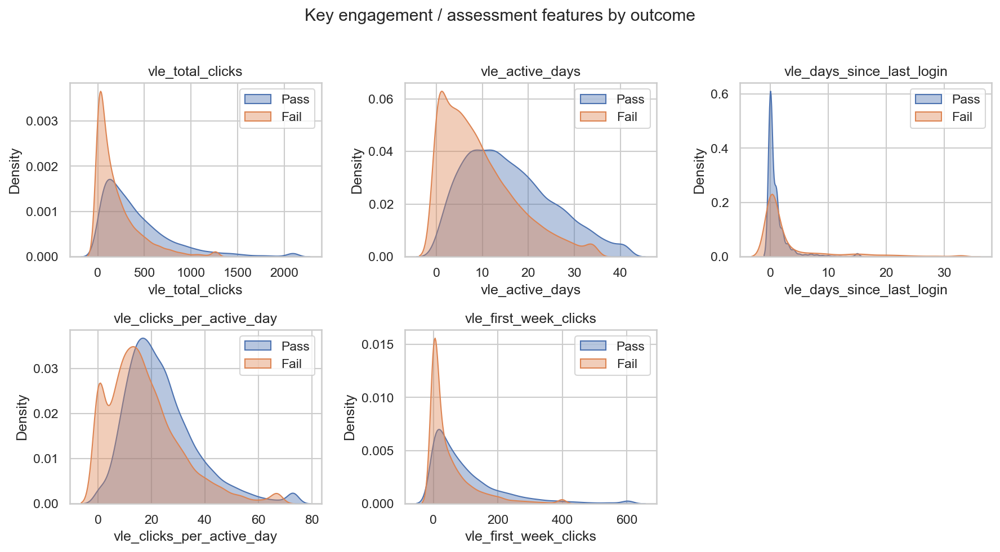

**report_eda_correlation_heatmap.png**

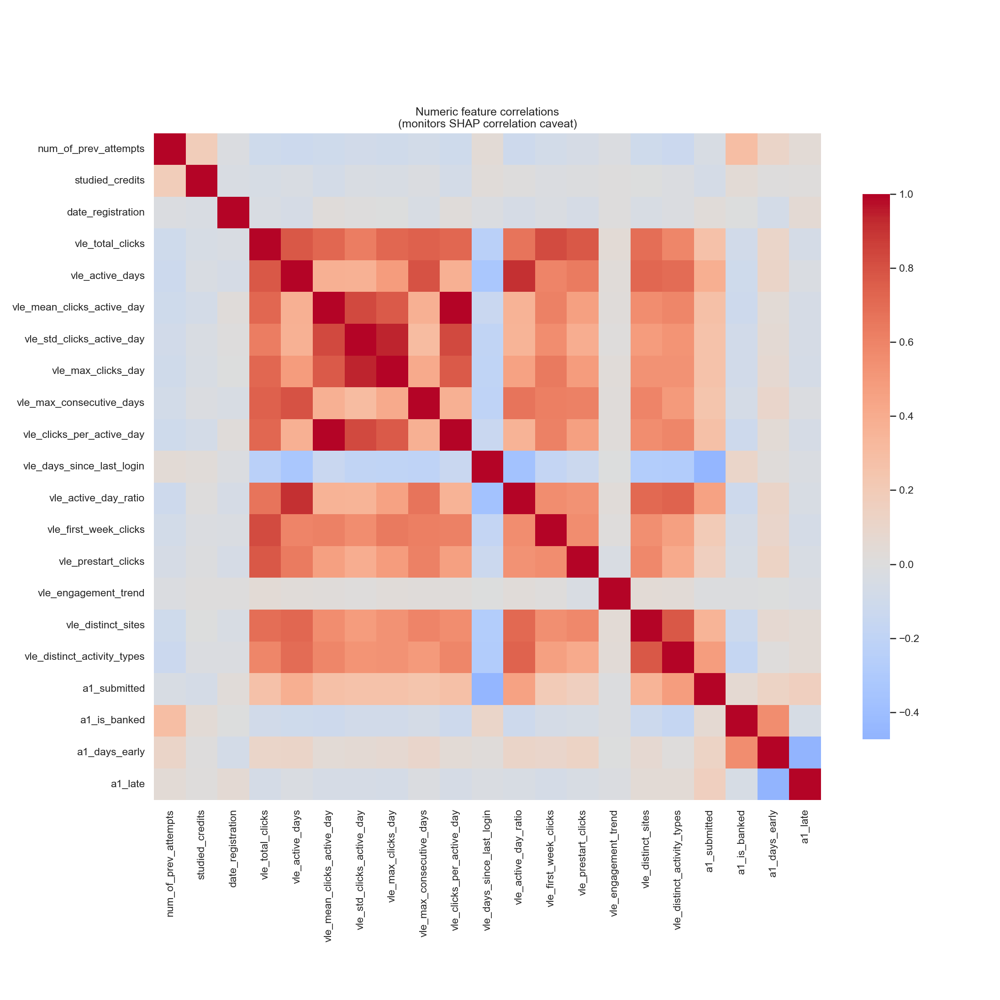

**report_eval_curves_BBB.png**

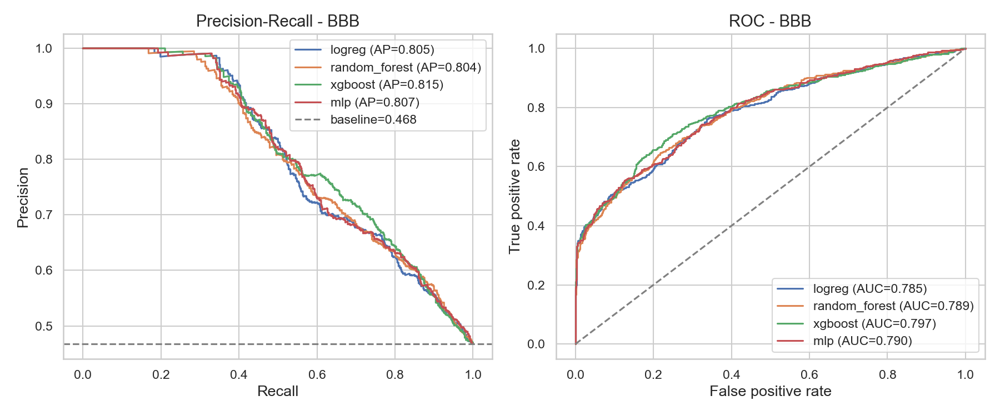

**report_confusion_matrices_BBB.png**

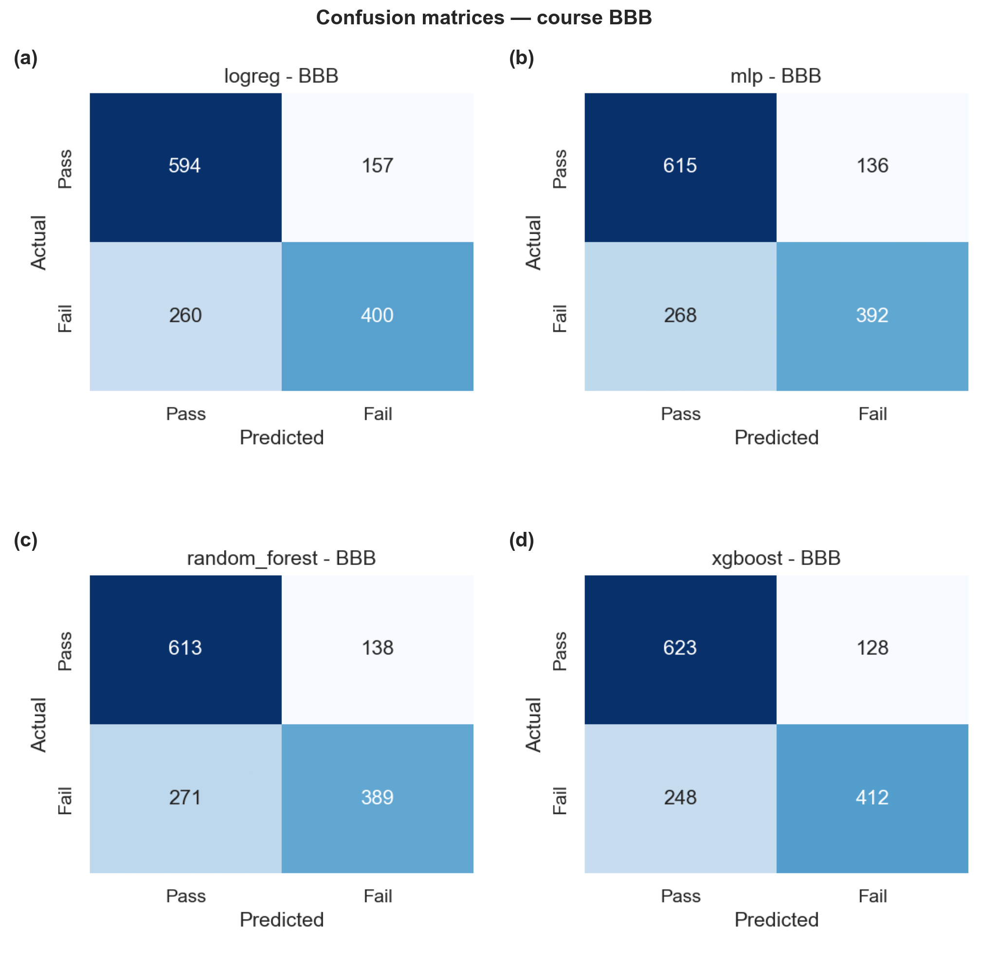

**report_shap_global_BBB.png**

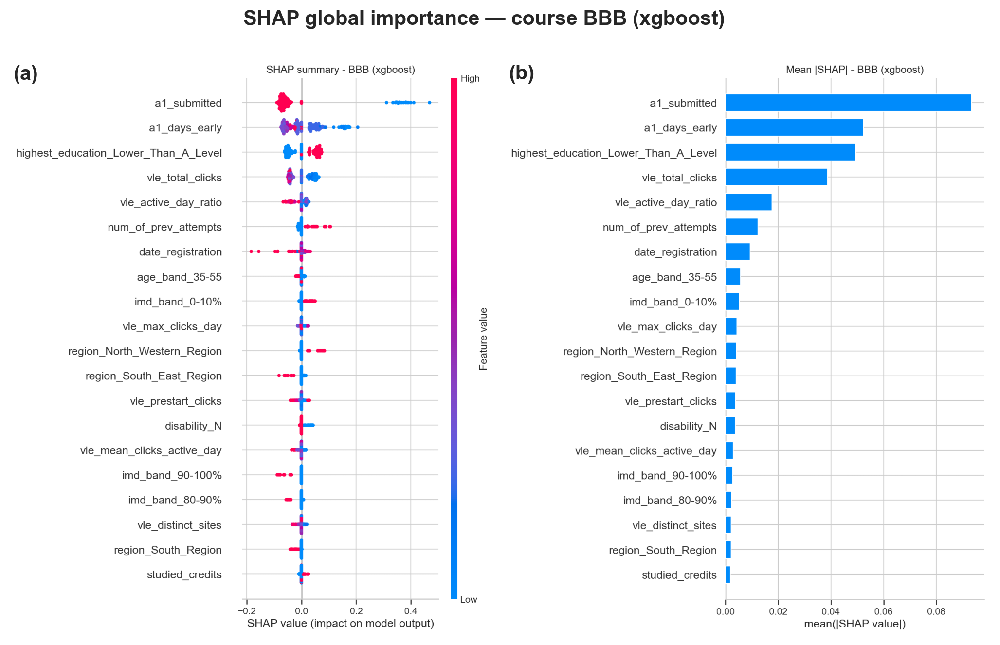

**report_shap_waterfalls_BBB.png**

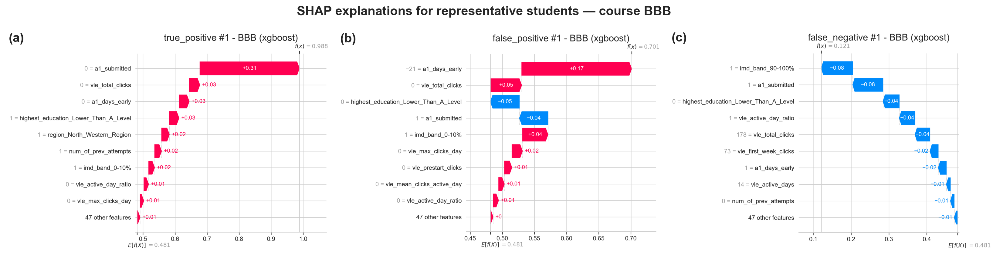

**report_eval_curves_DDD.png**

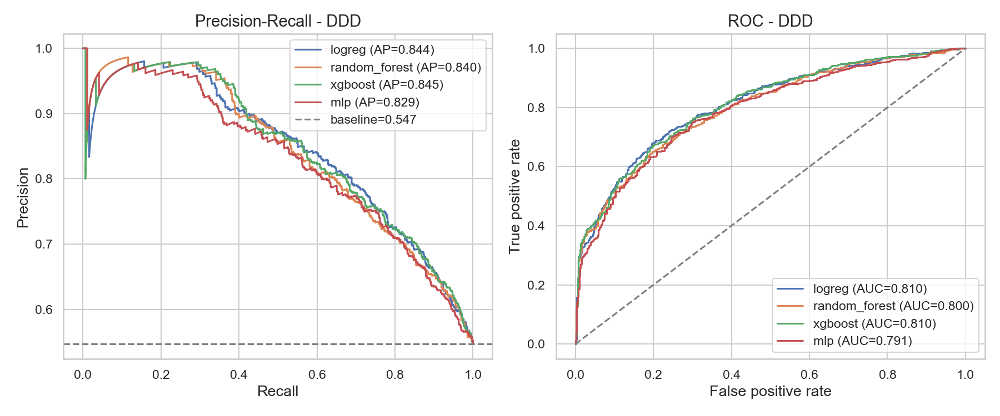

**report_confusion_matrices_DDD.png**

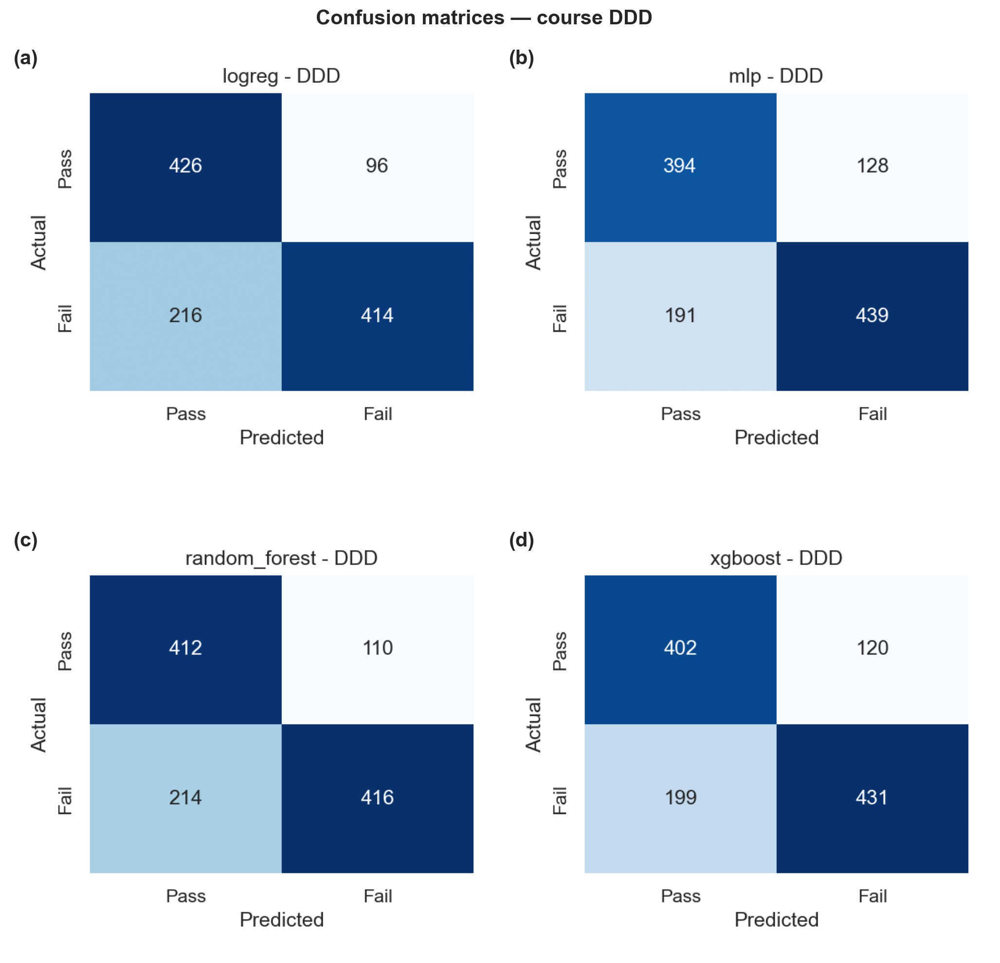

**report_shap_global_DDD.png**

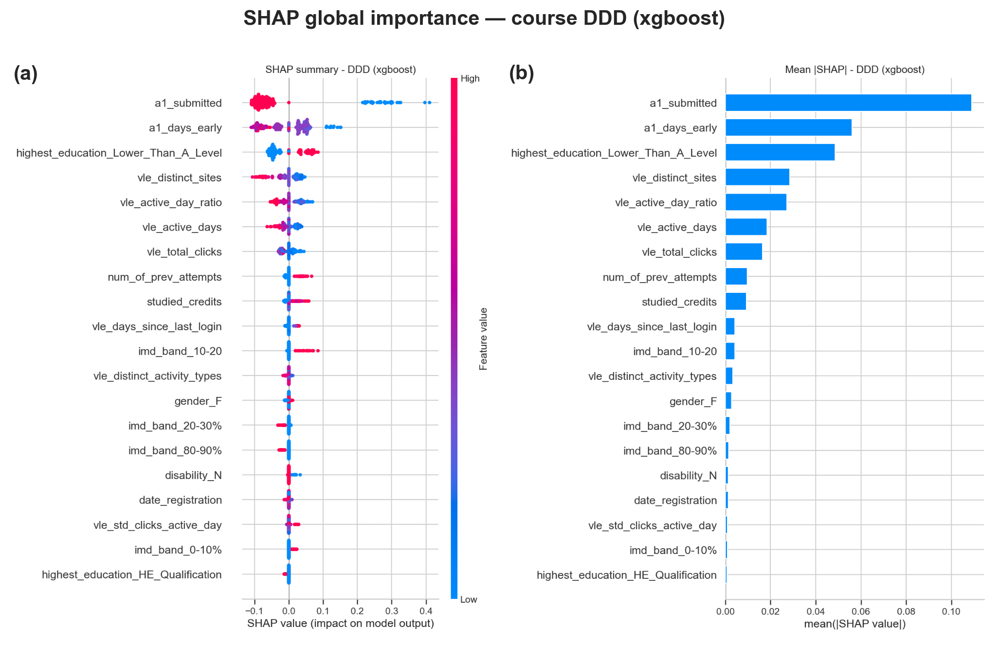

**report_shap_waterfalls_DDD.png**

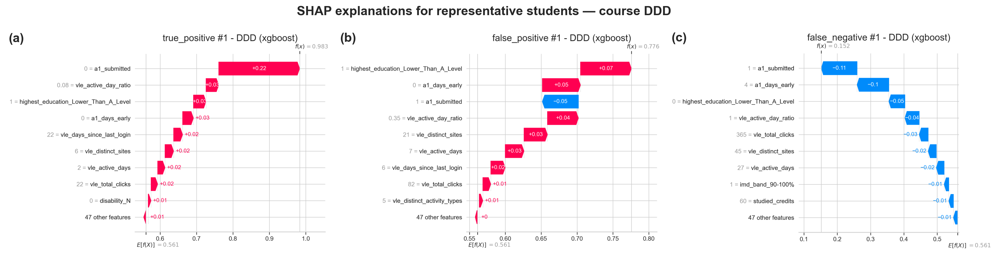

**report_eval_curves_EEE.png**

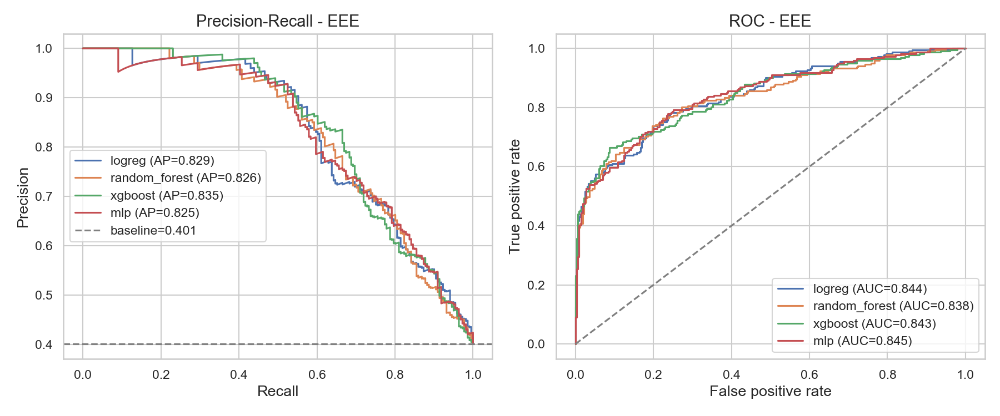

**report_confusion_matrices_EEE.png**

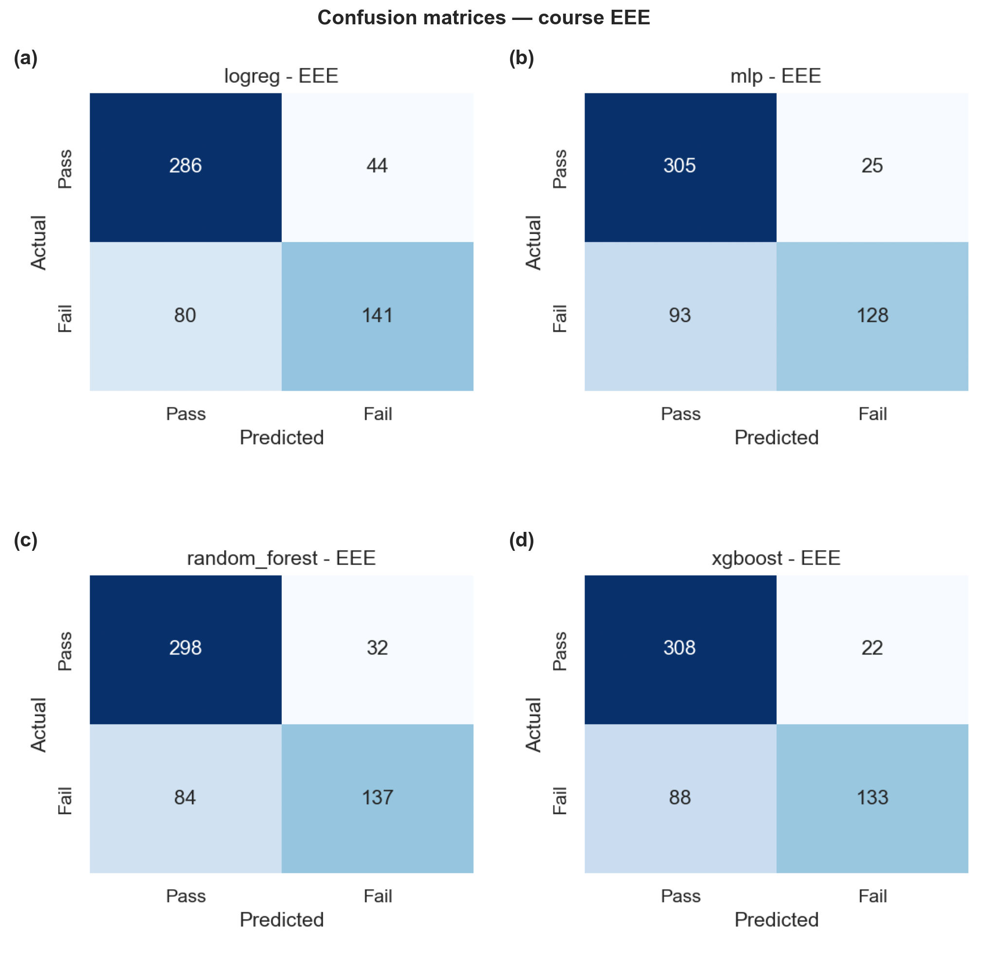

**report_shap_global_EEE.png**

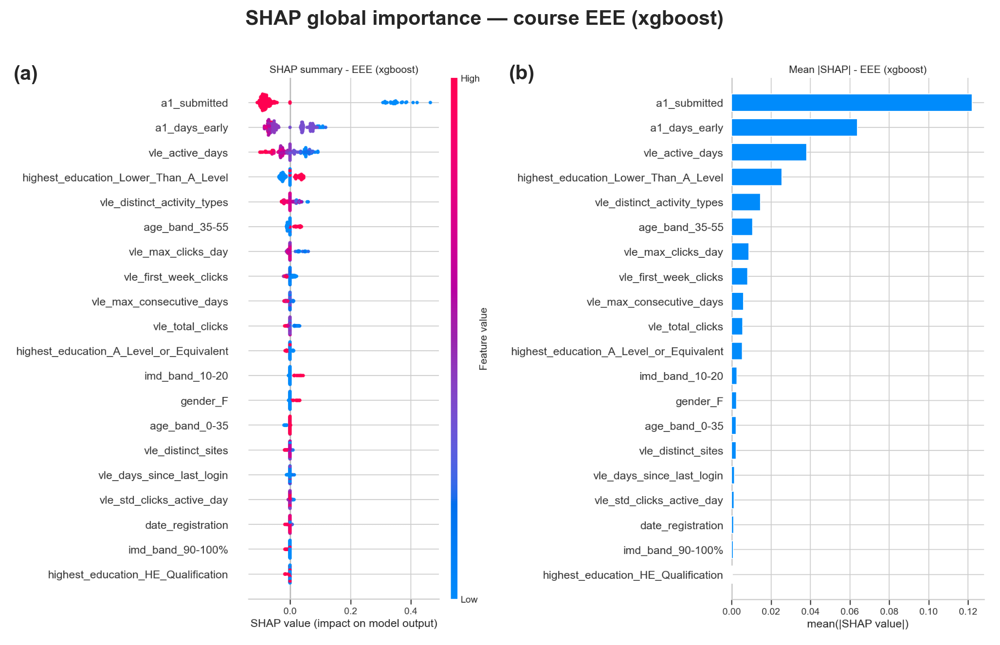

**report_shap_waterfalls_EEE.png**

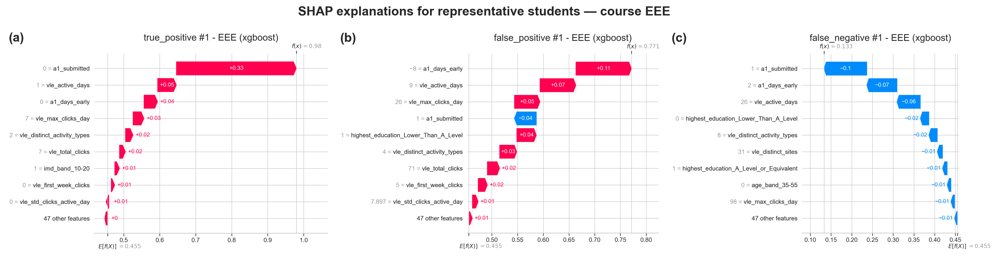

**report_eval_curves_FFF.png**

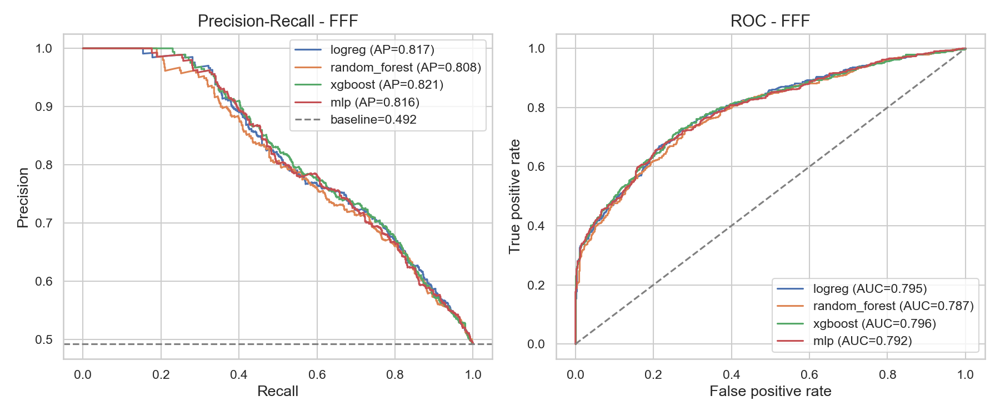

**report_confusion_matrices_FFF.png**

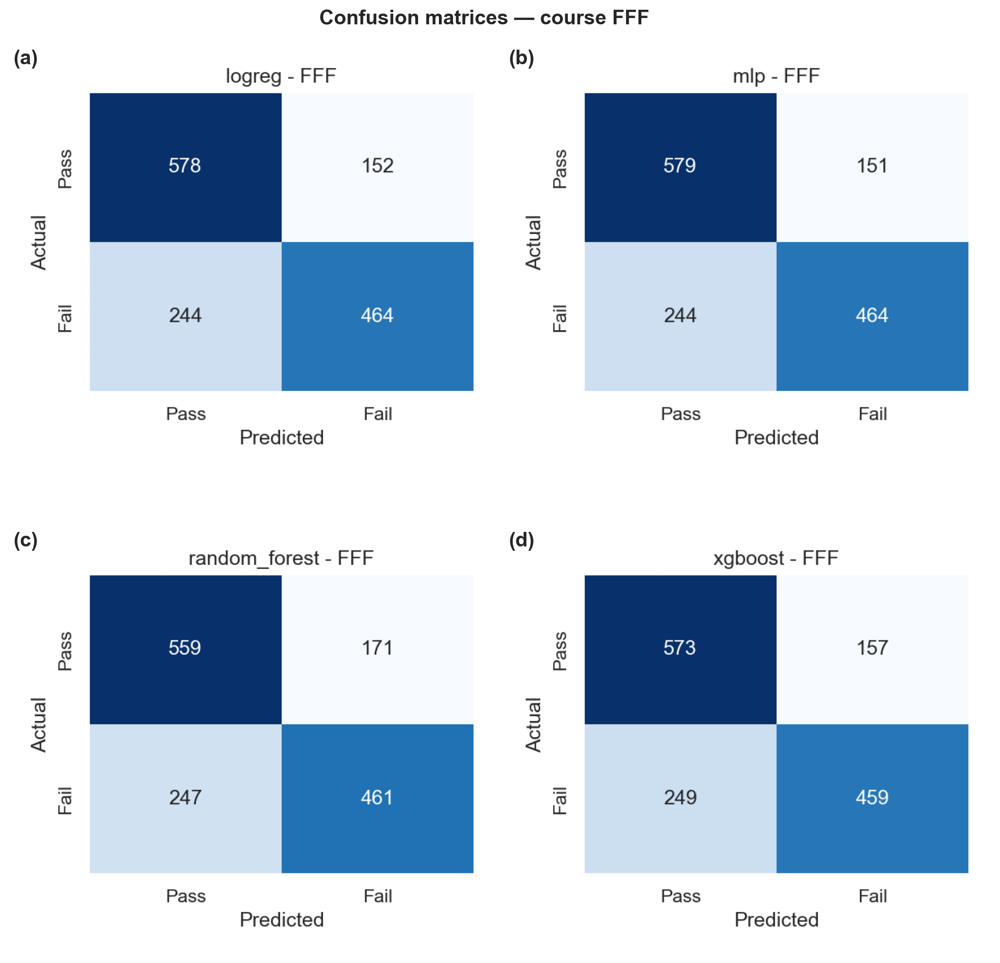

**report_shap_global_FFF.png**

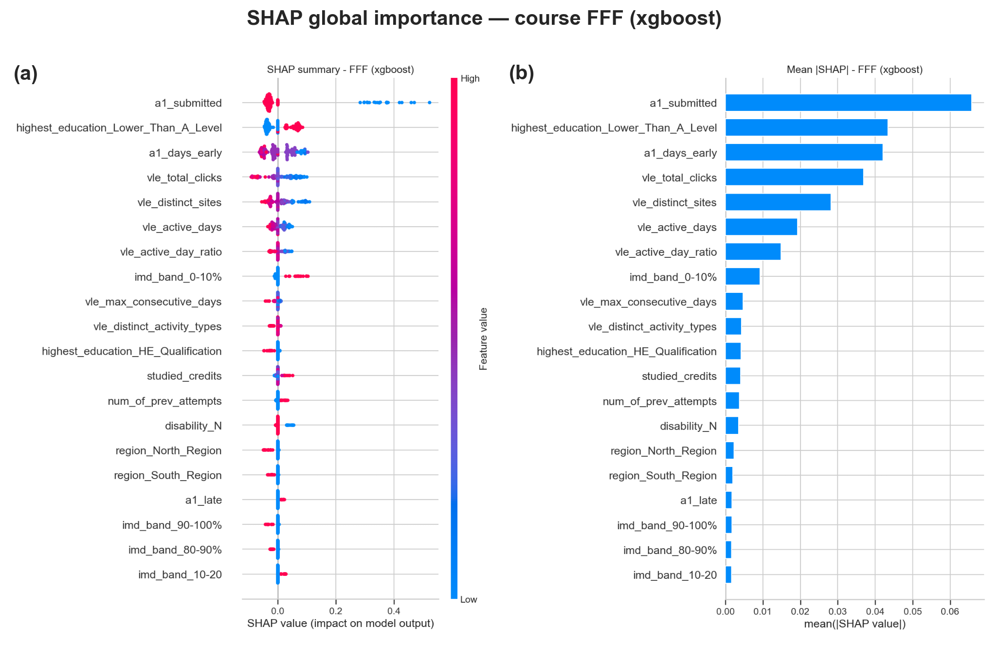

**report_shap_waterfalls_FFF.png**

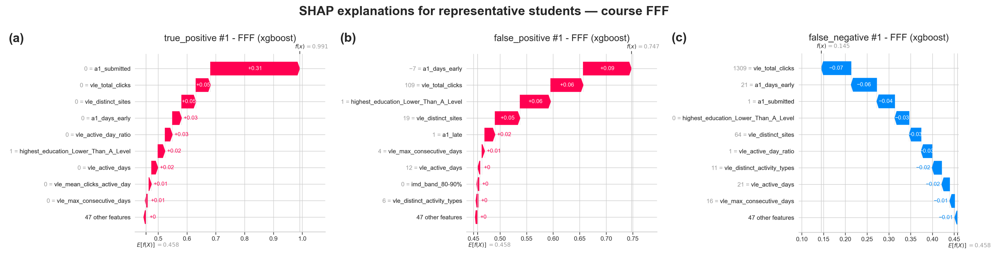

**report_cross_course.png**

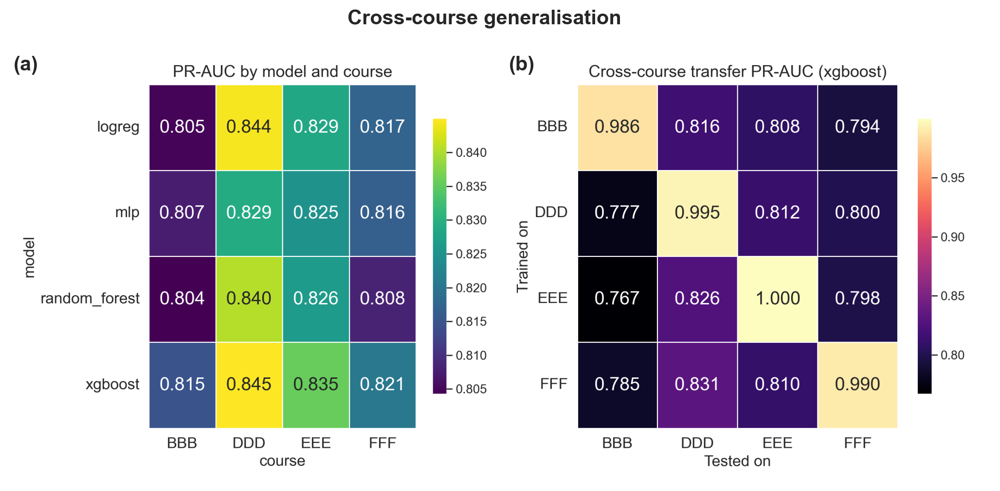

In [24]:
# Combine the generated visual panels into report figures and display them.
# Each combined image represents a single report figure. For the selected
# course analysis, nine figures were produced:
#   - Four EDA figures covering overview, demographics, distributions, and correlations
#   - Four course-specific figures covering evaluation curves, confusion matrix,
#     global SHAP explanations, and local SHAP explanations
#   - One cross-course comparison figure
# Additional figures were generated for other courses where applicable.
report_courses = list(all_results.keys())
report_paths = build_report_figures(report_courses, summary)
logger.info("Combined report figures written to %s", REPORT_DIR)

for _p in report_paths:
    display(Markdown(f"**{_p.name}**"))
    show_images([_p], width=760)